In [1]:
import os
import glob
import nilearn
import warnings
import numpy as np
import pandas as pd
import nibabel as nb
import pingouin as pg
import seaborn as sns
import os.path as path
import plotly.express as px
import statsmodels.api as sm
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler


/Users/jivesh/opt/anaconda3/lib/python3.8/site-packages/pandas/core/computation/expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/jivesh/opt/anaconda3/lib/python3.8/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package outdated is out of date. Your version is 0.2.1, the latest is 0.2.2.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(
/Users/jivesh/opt/anaconda3/lib/python3.8/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.3.11, the latest is 0.7.0.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


In [2]:
demo = pd.read_csv('/Users/jivesh/Downloads/hbcd_state_factors.csv').set_index('States')
demo


,Population Density,Proficiency Scores,Unemployment Rate,Gini Coefficient,Childcare Cost Burden,Political Preferences,Tightness and Looseness,Incarceration Rate,Working Women Index,Women Peace Security Index,Women Legislator Representation,Abortion Laws,Reproductive Rights Index
States,,,,,,,,,,,,,
Alabama,101,251,2.5,0.477,18.5,1,75.45,394,10.31,0.238,17.1,5,1.41
Arkansas,59,251,3.1,0.474,4.0,1,75.03,596,24.58,0.231,23.0,5,0.73
California,250,251,4.7,0.487,3.7,0,27.27,246,82.96,0.564,36.7,1,6.22
Georgia,192,252,3.3,0.479,56.2,1,60.26,449,13.51,0.382,34.7,4,1.95
Illinois,226,259,4.5,0.481,10.7,0,45.95,235,74.03,0.602,41.2,1,4.13
Maryland,637,262,2.2,0.456,0.8,0,45.50,261,52.17,0.639,41.0,1,5.21
Massachusetts,898,267,3.5,0.488,3.4,0,35.12,96,68.83,0.709,30.5,2,3.87
Minnesota,72,274,2.8,0.454,4.9,0,47.84,152,65.43,0.606,37.8,1,3.89
Missouri,90,259,3.1,0.461,8.8,1,59.60,385,40.01,0.381,29.4,2,0.22


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


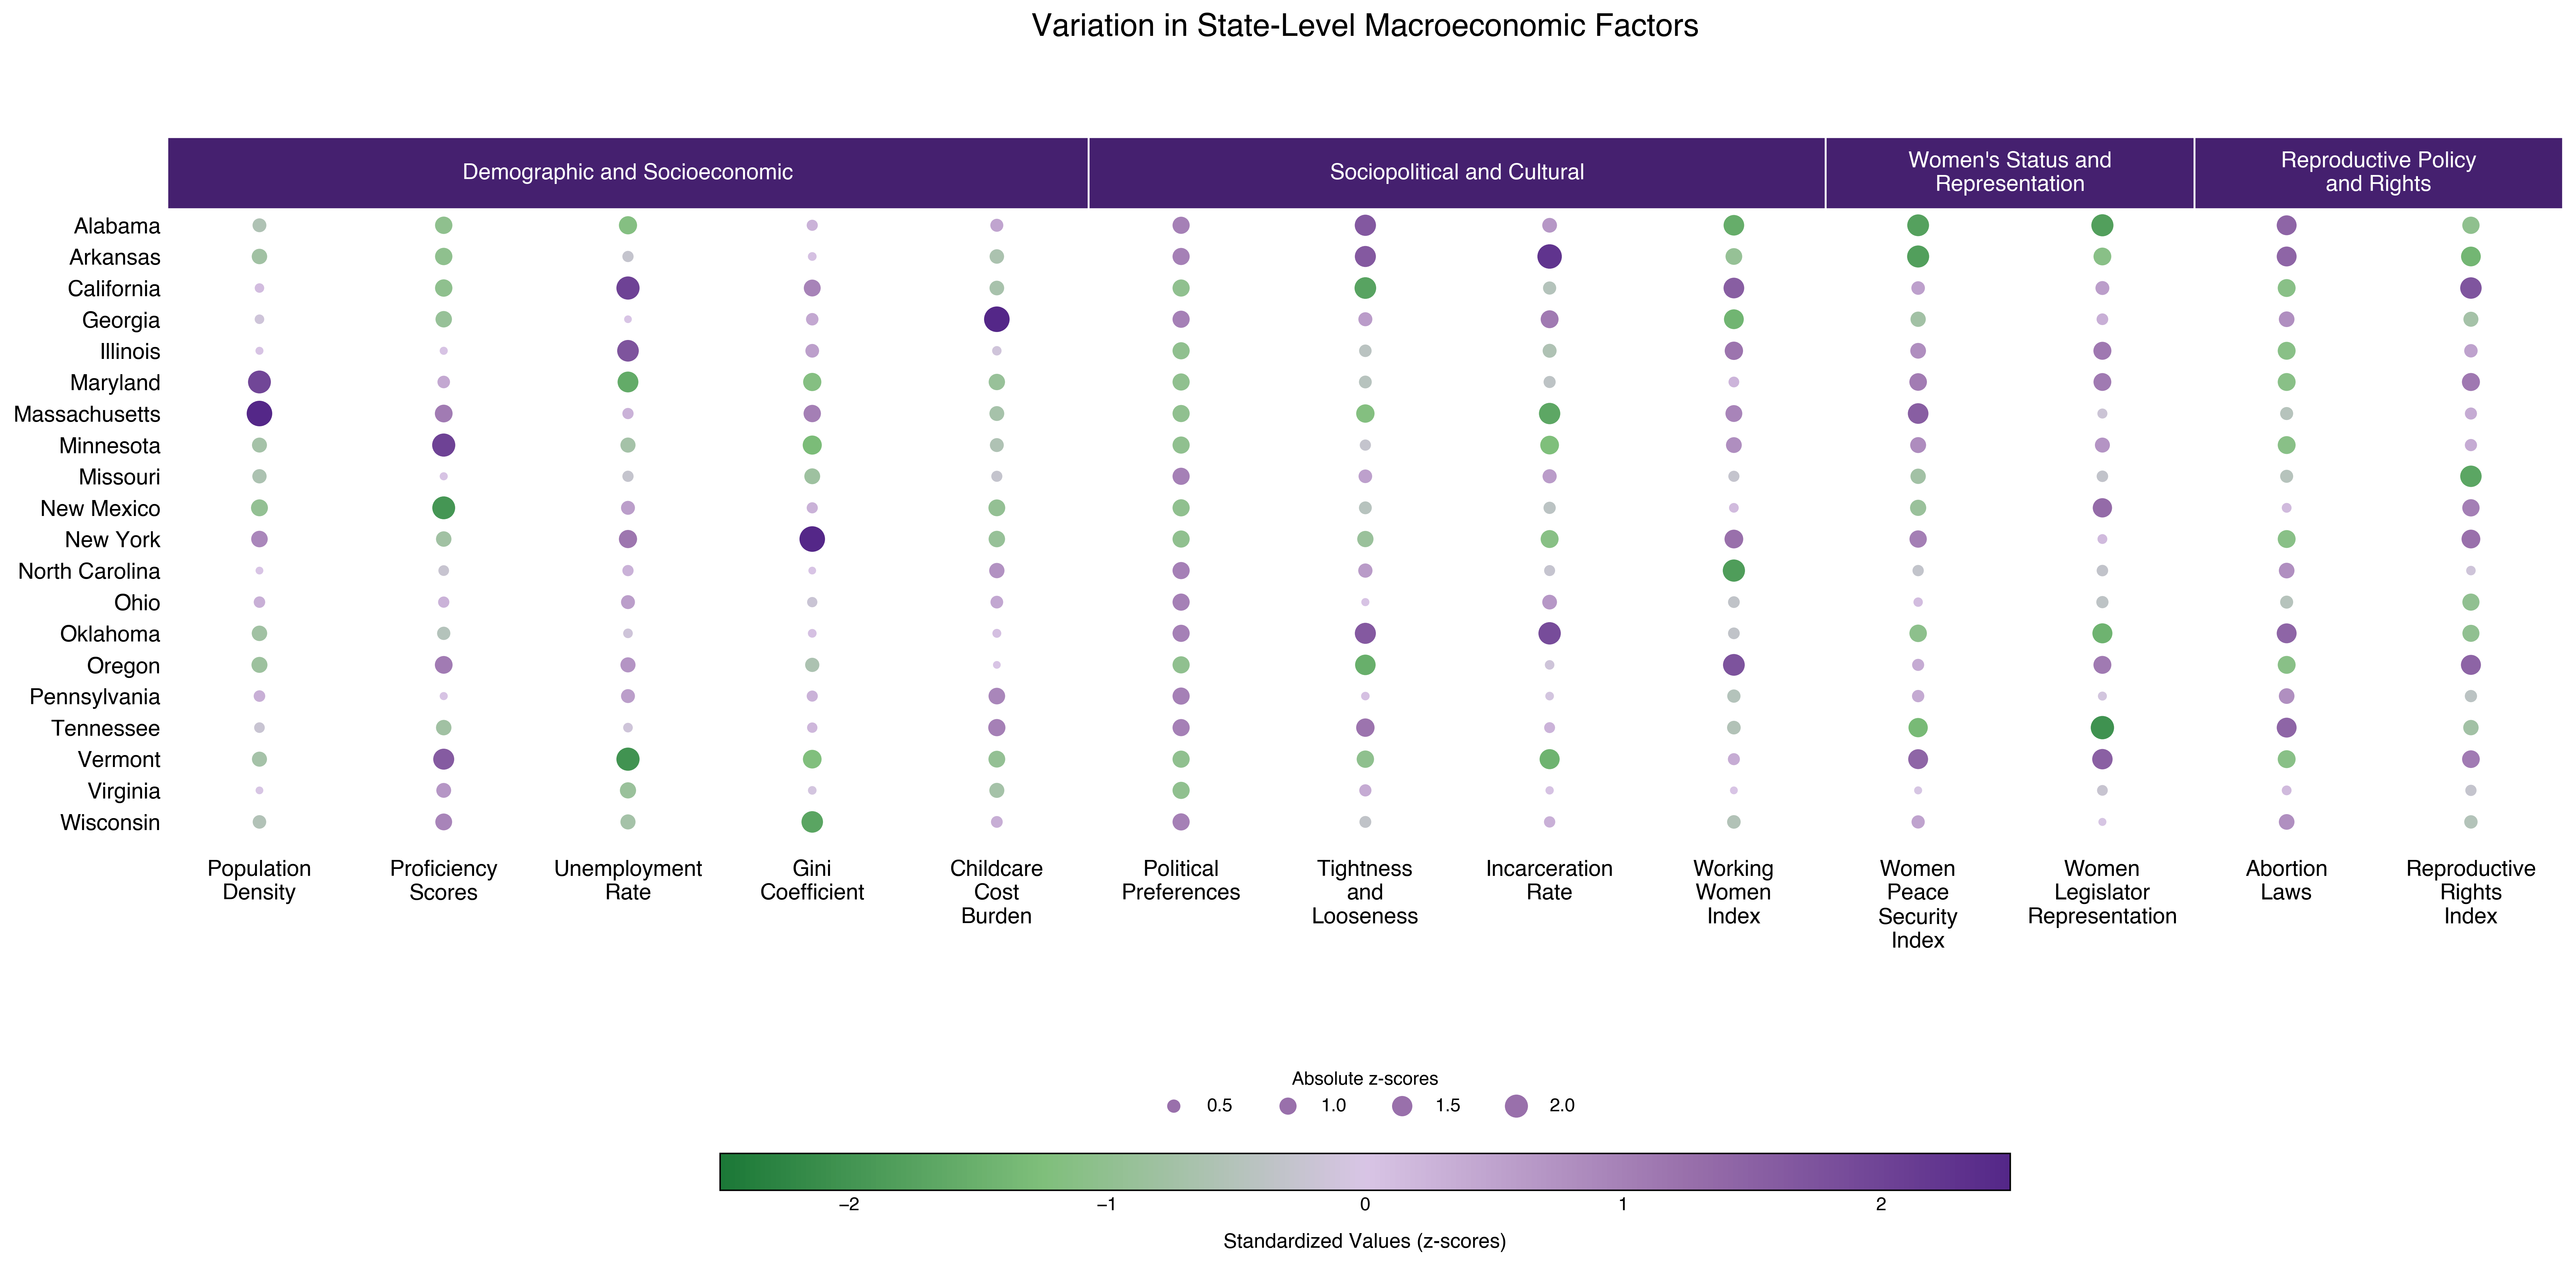

In [8]:
import matplotlib as mpl
from matplotlib.patches import Rectangle
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

# =====================================================
# 1. Define the 20 HBCD recruitment states
# =====================================================

states = [
    "Alabama", "Arkansas", "California", "Georgia",
    "Illinois", "Maryland", "Massachusetts", "Minnesota",
    "Missouri", "New Mexico", "New York", "North Carolina",
    "Ohio", "Oklahoma", "Oregon", "Pennsylvania",
    "Tennessee", "Vermont", "Virginia", "Wisconsin"
]

# =====================================================
# 2. Define the four domains and 13 factors
# =====================================================

domains = {
    "Demographic and Socioeconomic": [
        "Population Density",
        "Proficiency Scores",
        "Unemployment Rate",
        "Gini Coefficient",
        "Childcare Cost Burden"
    ],

    "Sociopolitical and Cultural": [
        "Political Preferences",
        "Tightness and Looseness",
        "Incarceration Rate",
        "Working Women Index"
    ],

    "Women's Status and\nRepresentation": [
        "Women Peace Security Index",
        "Women Legislator Representation"
    ],

    "Reproductive Policy\nand Rights": [
        "Abortion Laws",
        "Reproductive Rights Index"
    ]
}

factors = [
    factor
    for domain_factors in domains.values()
    for factor in domain_factors
]

# =====================================================
# 3. Prepare and standardize data
# =====================================================

# Assumes demo has state names as its index
heatmap_data = demo.loc[states, factors].astype(float)

# Standardize each factor across states
means = heatmap_data.mean(axis=0)
stds = heatmap_data.std(axis=0, ddof=0)

# Avoid division by zero for constant variables
stds = stds.replace(0, np.nan)

heatmap_z = (heatmap_data - means) / stds

# =====================================================
# 4. Figure settings
# =====================================================

plt.rcParams.update({
    "font.family": "Helvetica",
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, ax = plt.subplots(figsize=(22, 13))

# =====================================================
# 5. Custom Green–Lavender–Purple palette
# =====================================================

cmap = LinearSegmentedColormap.from_list(
    "GreenLavenderPurple",
    [
        "#1B7837",  # Dark green
        "#7FBF7B",  # Light green
        "#D8C5E5",  # Lavender midpoint
        "#9970AB",  # Medium purple
        "#542788"   # Dark purple
    ],
    N=256
)

cmap.set_bad("#E0E0E0")

norm = TwoSlopeNorm(
    vmin=-2.5,
    vcenter=0,
    vmax=2.5
)

n_states, n_factors = heatmap_z.shape

# =====================================================
# 6. Draw circle heatmap
# =====================================================

for i in range(n_states):

    for j in range(n_factors):

        z = heatmap_z.iloc[i, j]

        if pd.isna(z):
            continue

        # Clip values to the color range
        z_clipped = np.clip(z, -2.5, 2.5)

        # Smaller circles to prevent overlap
        circle_size = (
            20 + 180 * min(abs(z) / 2.5, 1)
        )

        ax.scatter(
            j + 0.5,
            i + 0.5,
            s=circle_size,
            color=cmap(norm(z_clipped)),
            edgecolors="#FFFFFF",
            linewidths=0.3,
            zorder=3
        )

# =====================================================
# 7. Format axes
# =====================================================

ax.set_xlim(0, n_factors)
ax.set_ylim(n_states, -2.3)

ax.set_xticks(np.arange(n_factors) + 0.5)
ax.set_yticks(np.arange(n_states) + 0.5)

# Wrap factor names onto multiple lines
ax.set_xticklabels(
    [factor.replace(" ", "\n") for factor in factors],
    fontsize=12,
    rotation=0,
    ha="center"
)

ax.set_yticklabels(
    states,
    fontsize=12,
    rotation=0
)

ax.tick_params(
    axis="both",
    length=0
)

ax.tick_params(
    axis="x",
    pad=12
)

ax.set_xlabel("")
ax.set_ylabel("")

# =====================================================
# 8. Add four purple domain headers
# =====================================================

header_colors = ["#45206F"] * 4

start = 0

for (domain, domain_factors), color in zip(
    domains.items(), header_colors
):

    width = len(domain_factors)

    # Domain header rectangle
    rect = Rectangle(
        (start, -2.3),
        width,
        2.3,
        facecolor=color,
        edgecolor="white",
        linewidth=1,
        clip_on=False,
        zorder=5
    )

    ax.add_patch(rect)

    # Domain label
    ax.text(
        start + width / 2,
        -1.15,
        domain,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="white",
        zorder=6
    )

    start += width

# =====================================================
# 9. Add horizontal colorbar
# =====================================================

sm = mpl.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation="horizontal",
    fraction=0.035,
    pad=0.30,
    shrink=0.55,
    aspect=35
)

cbar.set_ticks([-2, -1, 0, 1, 2])

cbar.set_label(
    "Standardized Values (z-scores)",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

cbar.ax.tick_params(
    labelsize=10,
    length=0
)

# =====================================================
# 10. Add circle size legend
# =====================================================

legend_values = [0.5, 1.0, 1.5, 2.0]

legend_handles = []

for value in legend_values:

    size = 20 + 180 * min(value / 2.5, 1)

    handle = ax.scatter(
        [],
        [],
        s=size,
        facecolor="#9970AB",
        edgecolor="white",
        linewidth=0.3,
        label=f"{value:.1f}"
    )

    legend_handles.append(handle)

ax.legend(
    handles=legend_handles,
    title="Absolute z-scores",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.31),
    ncol=4,
    frameon=False,
    fontsize=10,
    title_fontsize=10
)

# =====================================================
# 11. Final formatting
# =====================================================

ax.set_title(
    "Variation in State-Level Macroeconomic Factors",
    fontsize=17,
    fontweight="bold",
    pad=55
)

fig.subplots_adjust(
    top=0.85,
    bottom=0.24,
    left=0.15,
    right=0.97
)

# =====================================================
# 12. Save figures
# =====================================================

plt.savefig(
    "HBCD_Circle_Heatmap_GreenLavenderPurple.png",
    dpi=1000,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "HBCD_Circle_Heatmap_GreenLavenderPurple.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [53]:
%config InlineBackend.figure_format = 'retina'

plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 1000,
    "font.family": "Arial",
    "font.size": 12,
    "text.antialiased": True,
    "patch.antialiased": True,
    "lines.antialiased": True,
    "svg.fonttype": "none",
    "pdf.fonttype": 42
})

corr = demo.corr(method="pearson")

pvals = pd.DataFrame(
    np.zeros_like(corr),
    index=corr.index,
    columns=corr.columns
)

for i in range(len(demo.columns)):
    for j in range(len(demo.columns)):
        x = demo.iloc[:, i]
        y = demo.iloc[:, j]

        # Remove missing values pairwise
        valid = x.notna() & y.notna()

        rho, p = spearmanr(x[valid], y[valid])

        pvals.iloc[i, j] = p


# -----------------------------
# Significance function
# -----------------------------
def significance_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""


# -----------------------------
# Mask upper triangle + diagonal
# -----------------------------
mask = np.triu(
    np.ones_like(corr, dtype=bool),
    k=0
)


# -----------------------------
# Plot
# -----------------------------
plt.rcParams["font.family"] = "Helvetica"

fig, ax = plt.subplots(figsize=(10, 10), dpi=600)

sns.heatmap(
    corr,
    mask=mask,
    cmap="PRGn_r",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Pearson r",
        "shrink": 0.55,
        "aspect": 25
    },
    ax=ax
)


# -----------------------------
# Add stars ABOVE rho values
# -----------------------------
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):

        if not mask[i, j]:

            rho = corr.iloc[i, j]
            stars = significance_stars(pvals.iloc[i, j])

            # Significance stars
            if stars:
                ax.text(
                    j + 0.50,
                    i + 0.36,
                    stars,
                    ha="center",
                    va="center",
                    fontsize=10,
                    fontweight="bold"
                )

            # Spearman rho
            ax.text(
                j + 0.50,
                i + 0.62,
                f"{rho:.2f}",
                ha="center",
                va="center",
                fontsize=9
            )


plt.tight_layout()

fig.savefig(
    "correlation_matrix.pdf",
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


Number of states: 20
Number of variables: 13

PCA SUMMARY
      PC  Eigenvalue  Variance Explained (%)  Cumulative Variance (%)
0    PC1        7.33                   53.55                    53.55
1    PC2        2.33                   17.03                    70.58
2    PC3        1.26                    9.20                    79.78
3    PC4        0.98                    7.15                    86.93
4    PC5        0.61                    4.42                    91.35
5    PC6        0.35                    2.59                    93.94
6    PC7        0.24                    1.74                    95.68
7    PC8        0.22                    1.62                    97.30
8    PC9        0.13                    0.95                    98.25
9   PC10        0.12                    0.86                    99.11
10  PC11        0.07                    0.48                    99.59
11  PC12        0.04                    0.30                    99.89
12  PC13        0.02            

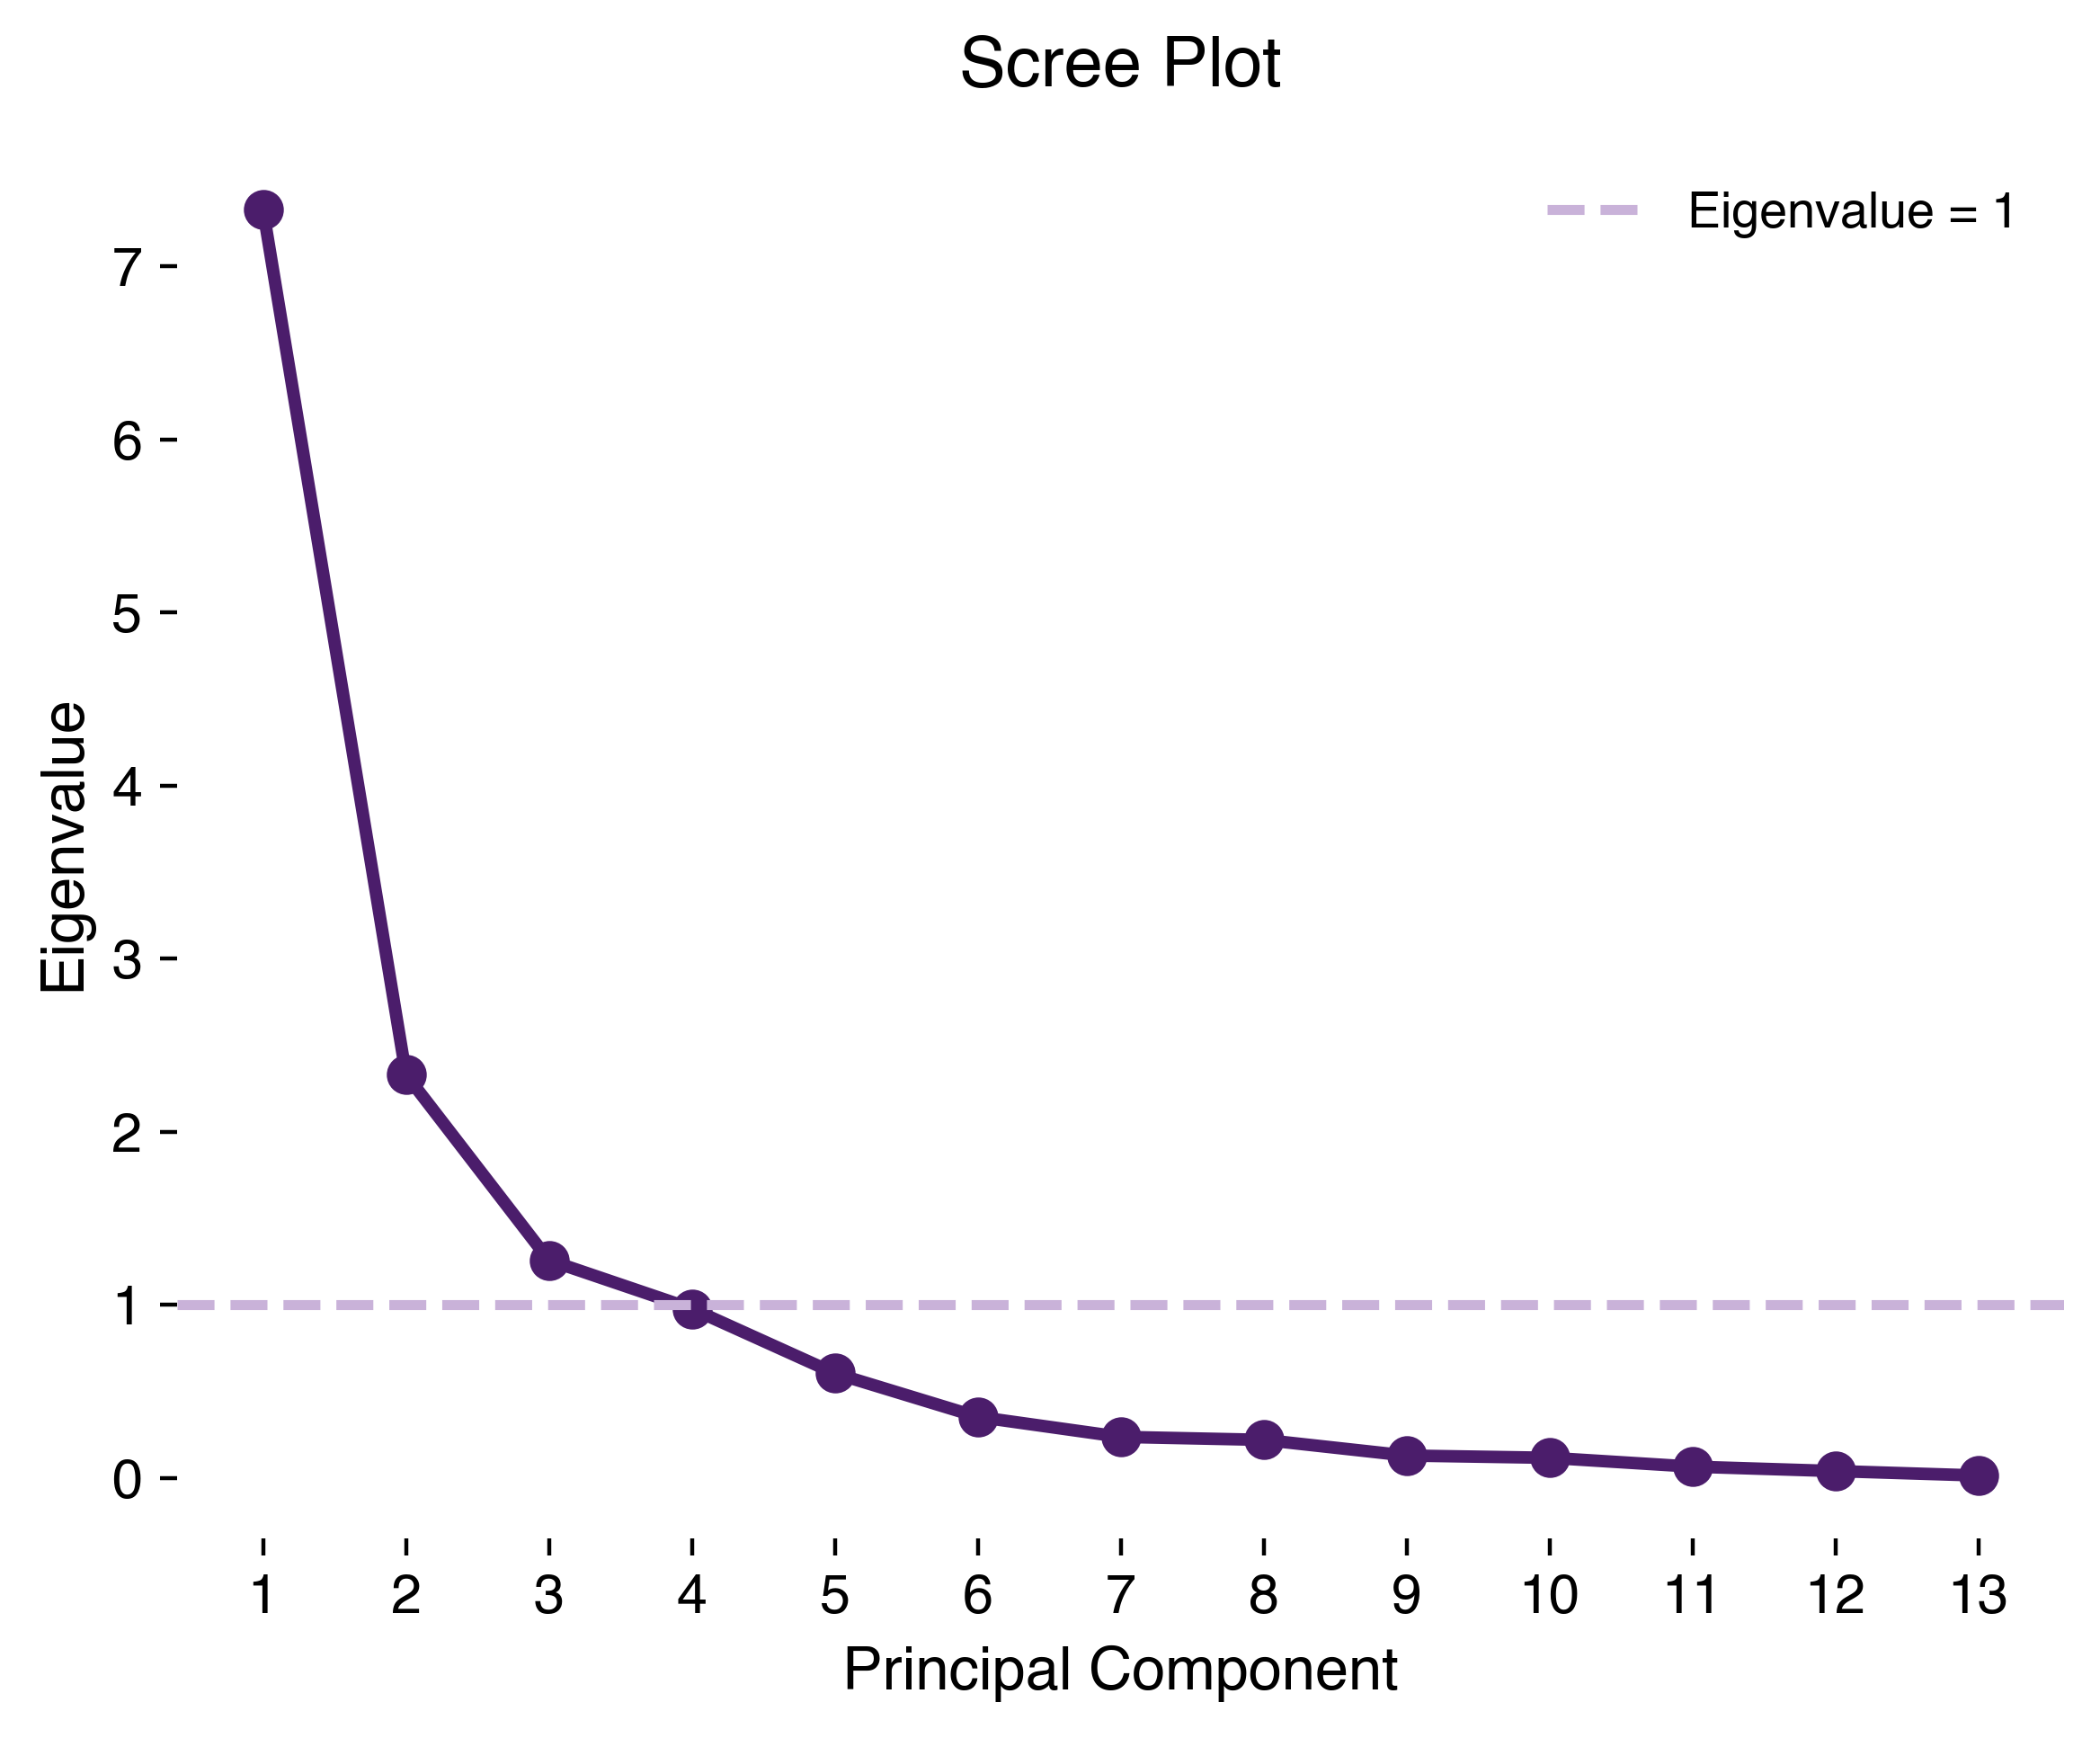


PARALLEL ANALYSIS
      PC  Observed  Random Mean  Random 95th  Retain (Mean)  Retain (95th)
0    PC1     7.328        2.799        3.268           True           True
1    PC2     2.331        2.257        2.565           True          False
2    PC3     1.259        1.873        2.121          False          False
3    PC4     0.979        1.559        1.769          False          False
4    PC5     0.605        1.293        1.479          False          False
5    PC6     0.354        1.058        1.230          False          False
6    PC7     0.238        0.848        1.009          False          False
7    PC8     0.221        0.665        0.814          False          False
8    PC9     0.130        0.505        0.641          False          False
9   PC10     0.117        0.365        0.486          False          False
10  PC11     0.066        0.246        0.348          False          False
11  PC12     0.041        0.148        0.230          False          False
12  PC

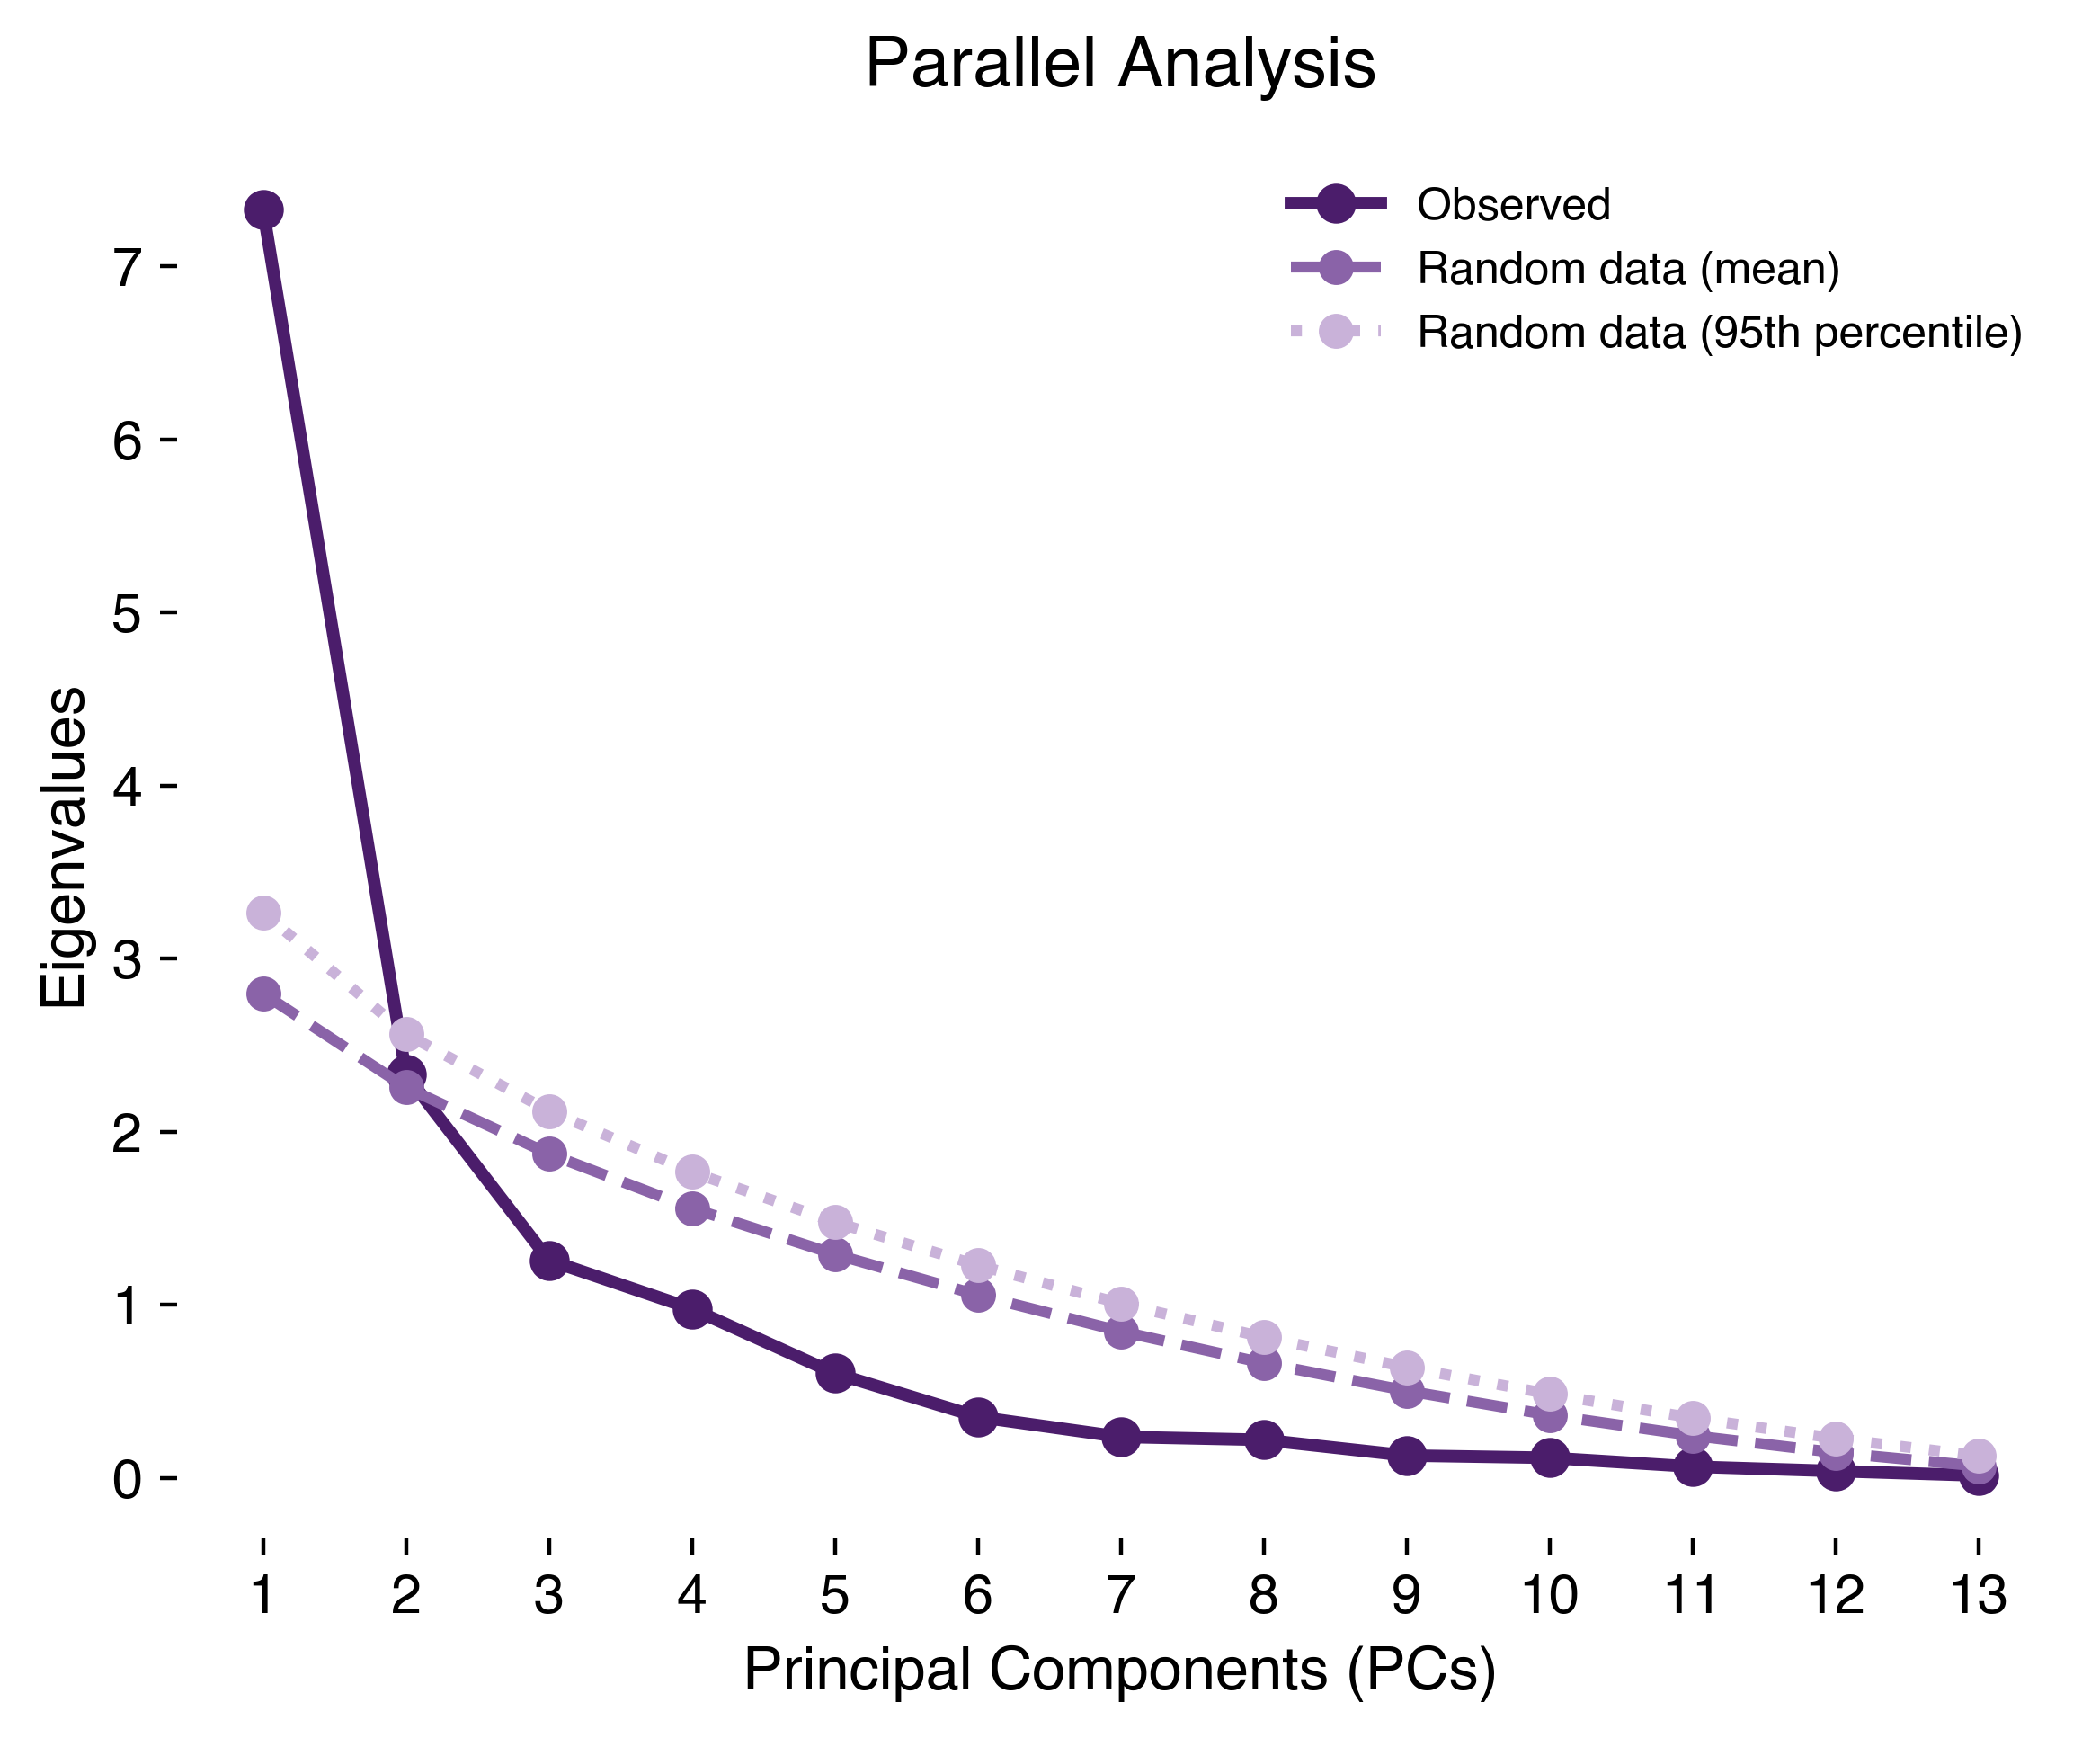


Final number of components retained: 2

RETAINED COMPONENT LOADINGS
                                   PC1    PC2
Population Density              -0.420  0.204
Proficiency Scores              -0.493 -0.750
Unemployment Rate               -0.225  0.843
Gini Coefficient                -0.081  0.933
Childcare Cost Burden            0.584  0.086
Political Preferences            0.927 -0.054
Tightness and Looseness          0.956 -0.072
Incarceration Rate               0.872  0.051
Working Women Index             -0.887  0.189
Women Peace Security Index      -0.911 -0.175
Women Legislator Representation -0.819 -0.151
Abortion Laws                    0.938  0.056
Reproductive Rights Index       -0.899  0.182

------------------------------
PC1
------------------------------
Tightness and Looseness            0.956
Abortion Laws                      0.938
Political Preferences              0.927
Women Peace Security Index        -0.911
Reproductive Rights Index         -0.899
Working Women I

,state,PC1,PC2,PC1_z,PC2_z
0,Alabama,4.092,0.020,1.551,0.014
1,Arkansas,4.046,0.303,1.534,0.203
2,California,-3.101,2.529,-1.175,1.699
3,Georgia,2.933,0.662,1.112,0.445
4,Illinois,-2.426,1.275,-0.920,0.857
5,Maryland,-2.559,-1.644,-0.970,-1.105
6,Massachusetts,-3.267,0.664,-1.238,0.446
7,Minnesota,-2.395,-2.360,-0.908,-1.586
8,Missouri,1.645,-0.948,0.624,-0.637
9,New Mexico,-0.829,1.425,-0.314,0.958



LEAVE-ONE-STATE-OUT PCA STABILITY
     State Removed  PC1 Congruence  PC2 Congruence  \
0          Alabama           0.999           0.999   
1         Arkansas           0.999           1.000   
2       California           0.997           0.986   
3          Georgia           0.999           0.998   
4         Illinois           0.999           0.999   
5         Maryland           0.998           0.984   
6    Massachusetts           0.999           0.999   
7        Minnesota           0.999           0.991   
8         Missouri           1.000           0.999   
9       New Mexico           0.999           0.992   
10        New York           0.993           0.988   
11  North Carolina           1.000           1.000   
12            Ohio           1.000           1.000   
13        Oklahoma           1.000           1.000   
14          Oregon           0.999           0.999   
15    Pennsylvania           1.000           1.000   
16       Tennessee           1.000           1.

In [9]:
# ============================================================
# PCA OF STATE-LEVEL VARIABLE
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

%config InlineBackend.figure_format = 'retina'

plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 1000,
    "font.family": "Arial",
    "font.size": 12,
    "text.antialiased": True,
    "patch.antialiased": True,
    "lines.antialiased": True,
    "svg.fonttype": "none",
    "pdf.fonttype": 42
})

# ============================================================
# 1. STANDARDIZE VARIABLES
# ============================================================

scaler = StandardScaler()

X = demo
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    index=X.index,
    columns=X.columns
)

print(f"Number of states: {X.shape[0]}")
print(f"Number of variables: {X.shape[1]}")


# ============================================================
# 2. INITIAL PCA — ALL COMPONENTS
# ============================================================

pca_all = PCA()

pca_all.fit(X_scaled)


# Eigenvalues
eigenvalues = pca_all.explained_variance_


# Percentage of variance explained
variance_explained = (
    pca_all.explained_variance_ratio_ * 100
)


# Cumulative variance explained
cumulative_variance = np.cumsum(
    variance_explained
)


# PCA summary table
summary = pd.DataFrame({
    "PC": [
        f"PC{i+1}"
        for i in range(len(eigenvalues))
    ],

    "Eigenvalue":
        eigenvalues,

    "Variance Explained (%)":
        variance_explained,

    "Cumulative Variance (%)":
        cumulative_variance
})


print("\n==============================")
print("PCA SUMMARY")
print("==============================")

print(
    summary.round(2)
)


# ============================================================
# 3. SCREE PLOT
# ============================================================

plt.rcParams["font.family"] = "Helvetica"

dark_purple = "#4B1D6B"
medium_purple = "#8A63A8"
pale_purple = "#C9B2D9"


fig, ax = plt.subplots(
    figsize=(6, 5)
)


x = np.arange(
    1,
    len(eigenvalues) + 1
)


# Observed eigenvalues
ax.plot(
    x,
    eigenvalues,
    marker="o",
    markersize=7,
    linewidth=2.5,
    color=dark_purple,
    markerfacecolor=dark_purple,
    markeredgecolor=dark_purple
)


# Kaiser eigenvalue = 1 reference line
ax.axhline(
    y=1,
    linestyle="--",
    linewidth=2,
    color=pale_purple,
    label="Eigenvalue = 1"
)


# Labels
ax.set_xlabel(
    "Principal Component",
    fontsize=12
)

ax.set_ylabel(
    "Eigenvalue",
    fontsize=12
)

ax.set_title(
    "Scree Plot",
    fontsize=14,
    pad=12
)


ax.set_xticks(x)


ax.tick_params(
    axis="both",
    labelsize=11
)


# Remove top and right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# Legend
ax.legend(
    frameon=False,
    fontsize=10
)


plt.tight_layout()

plt.savefig(
    "/Users/jivesh/Downloads/PCA_scree_plot.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    transparent=False
)

plt.show()


plt.show()


# ============================================================
# 4. PARALLEL ANALYSIS
# ============================================================

n_iter = 5000

n_obs, n_vars = X_scaled.shape


# Reproducibility
rng = np.random.default_rng(
    12345
)


# Store eigenvalues from random datasets
random_eigenvalues = np.zeros(
    (n_iter, n_vars)
)


for i in range(n_iter):

    # --------------------------------------------------------
    # Generate random dataset with same n and p
    # --------------------------------------------------------

    random_data = rng.normal(
        size=(n_obs, n_vars)
    )


    # --------------------------------------------------------
    # Standardize random dataset
    # --------------------------------------------------------

    random_data = (
        StandardScaler()
        .fit_transform(random_data)
    )


    # --------------------------------------------------------
    # PCA of random dataset
    # --------------------------------------------------------

    random_pca = PCA()

    random_pca.fit(
        random_data
    )


    # --------------------------------------------------------
    # Store eigenvalues
    # --------------------------------------------------------

    random_eigenvalues[i, :] = (
        random_pca.explained_variance_
    )


# ============================================================
# 5. RANDOM EIGENVALUE BENCHMARKS
# ============================================================


# Mean eigenvalue across random datasets
random_mean = np.mean(
    random_eigenvalues,
    axis=0
)


# 95th percentile eigenvalue
random_95 = np.percentile(
    random_eigenvalues,
    95,
    axis=0
)


# ============================================================
# 6. PARALLEL ANALYSIS RESULTS TABLE
# ============================================================

parallel_results = pd.DataFrame({

    "PC": [
        f"PC{i+1}"
        for i in range(n_vars)
    ],

    "Observed":
        eigenvalues,

    "Random Mean":
        random_mean,

    "Random 95th":
        random_95,

    "Retain (Mean)":
        eigenvalues > random_mean,

    "Retain (95th)":
        eigenvalues > random_95
})


print("\n==============================")
print("PARALLEL ANALYSIS")
print("==============================")

print(
    parallel_results.round(3)
)


# Number retained under each criterion
n_components_mean = (
    parallel_results[
        "Retain (Mean)"
    ].sum()
)

n_components_95 = (
    parallel_results[
        "Retain (95th)"
    ].sum()
)


print(
    "\nNumber of components retained "
    "using mean random eigenvalues:",
    n_components_mean
)

print(
    "Number of components retained "
    "using 95th-percentile random eigenvalues:",
    n_components_95
)


# ============================================================
# 7. PARALLEL ANALYSIS PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(6, 5)
)


x = np.arange(
    1,
    n_vars + 1
)


# ------------------------------------------------------------
# Observed eigenvalues
# ------------------------------------------------------------

ax.plot(
    x,
    eigenvalues,
    marker="o",
    markersize=7,
    linewidth=2.5,
    color=dark_purple,
    markerfacecolor=dark_purple,
    markeredgecolor=dark_purple,
    label="Observed"
)


# ------------------------------------------------------------
# Mean random eigenvalues
# ------------------------------------------------------------

ax.plot(
    x,
    random_mean,
    marker="o",
    markersize=6,
    linewidth=2.2,
    linestyle="--",
    color=medium_purple,
    markerfacecolor=medium_purple,
    markeredgecolor=medium_purple,
    label="Random data (mean)"
)


# ------------------------------------------------------------
# 95th percentile random eigenvalues
# ------------------------------------------------------------

ax.plot(
    x,
    random_95,
    marker="o",
    markersize=6,
    linewidth=2.2,
    linestyle=":",
    color=pale_purple,
    markerfacecolor=pale_purple,
    markeredgecolor=pale_purple,
    label="Random data (95th percentile)"
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Principal Components (PCs)",
    fontsize=12
)

ax.set_ylabel(
    "Eigenvalues",
    fontsize=12
)

ax.set_title(
    "Parallel Analysis",
    fontsize=14,
    pad=12
)


ax.set_xticks(x)


ax.tick_params(
    axis="both",
    labelsize=11
)


# Despine
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# Legend
ax.legend(
    frameon=False,
    fontsize=9
)


plt.tight_layout()


plt.savefig(
    "/Users/jivesh/Downloads/PCA_parallel_analysis.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    transparent=False
)

plt.show()


# ============================================================
# 8. RETAIN TWO COMPONENTS
# ============================================================
#
# Two components are retained based on consideration of:
#
# 1. Mean parallel analysis
# 2. Variance explained
# 3. Component interpretability
# 4. Leave-one-state-out stability
#
# Note:
# PC2 exceeds the mean random eigenvalue but not the
# more conservative 95th-percentile random eigenvalue.
# ============================================================

n_components = 2


print(
    "\nFinal number of components retained:",
    n_components
)


# ============================================================
# 9. FINAL TWO-COMPONENT PCA
# ============================================================

pca = PCA(
    n_components=n_components
)


PC_scores = pca.fit_transform(
    X_scaled
)


# ============================================================
# 10. PCA LOADINGS
# ============================================================

# Loadings = eigenvectors * sqrt(eigenvalues)

loadings = (
    pca.components_.T *
    np.sqrt(
        pca.explained_variance_
    )
)


loadings_df = pd.DataFrame(
    loadings,

    index=X.columns,

    columns=[
        f"PC{i+1}"
        for i in range(n_components)
    ]
)


print("\n==============================")
print("RETAINED COMPONENT LOADINGS")
print("==============================")

print(
    loadings_df.round(3)
)


# ============================================================
# 11. SORT LOADINGS BY ABSOLUTE MAGNITUDE
# ============================================================

for pc in loadings_df.columns:

    print(
        "\n------------------------------"
    )

    print(pc)

    print(
        "------------------------------"
    )

    sorted_loadings = (
        loadings_df[pc]
        .sort_values(
            key=lambda x: abs(x),
            ascending=False
        )
    )

    print(
        sorted_loadings.round(3)
    )


# ============================================================
# 12. PC1 LOADINGS TABLE
# ============================================================

PC1_loadings = pd.DataFrame({
    "PC1":
        loadings_df["PC1"]
})


PC1_loadings[
    "Absolute Loading"
] = (
    PC1_loadings["PC1"].abs()
)


PC1_loadings = (
    PC1_loadings
    .sort_values(
        "Absolute Loading",
        ascending=False
    )
)


print("\n==============================")
print("PC1 LOADINGS")
print("==============================")

print(
    PC1_loadings.round(3)
)


# ============================================================
# 13. PC2 LOADINGS TABLE
# ============================================================

PC2_loadings = pd.DataFrame({
    "PC2":
        loadings_df["PC2"]
})


PC2_loadings[
    "Absolute Loading"
] = (
    PC2_loadings["PC2"].abs()
)


PC2_loadings = (
    PC2_loadings
    .sort_values(
        "Absolute Loading",
        ascending=False
    )
)


print("\n==============================")
print("PC2 LOADINGS")
print("==============================")

print(
    PC2_loadings.round(3)
)


# ============================================================
# 14. VARIANCE EXPLAINED BY RETAINED COMPONENTS
# ============================================================

print("\n==============================")
print("VARIANCE EXPLAINED")
print("==============================")


for i in range(n_components):

    print(
        f"PC{i+1} explains "
        f"{pca.explained_variance_ratio_[i] * 100:.2f}% "
        "of the total variance."
    )


retained_cumulative_variance = (
    np.sum(
        pca.explained_variance_ratio_
    ) * 100
)


print(
    f"\nPC1 + PC2 explain "
    f"{retained_cumulative_variance:.2f}% "
    "of the total variance."
)


# ============================================================
# 15. STATE PC SCORES
# ============================================================

PC_scores_df = pd.DataFrame(
    PC_scores,

    index=X.index,

    columns=[
        "PC1",
        "PC2"
    ]
)


print("\n==============================")
print("STATE PC SCORES")
print("==============================")

print(
    PC_scores_df.round(3)
)

# ============================================================
# EXPORT STATE-LEVEL PC SCORES FOR HYPOTHESIS 2
# ============================================================

pc_power = PC_scores_df.copy()

# Convert state index into a column
pc_power.index.name = "state"
pc_power = pc_power.reset_index()

# Standardize PC scores across the 20 states
for pc in ["PC1", "PC2"]:
    pc_power[pc + "_z"] = (
        (pc_power[pc] - pc_power[pc].mean())
        / pc_power[pc].std(ddof=0)
    )

# Verify
print("Number of states:", len(pc_power))
print("Missing values:")
print(pc_power.isna().sum())

display(pc_power.round(3))

# Save
pc_power.to_csv(
    "HBCD_state_PC_scores.csv",
    index=False
)

# ============================================================
# 16. TUCKER'S CONGRUENCE FUNCTION
# ============================================================

def tuckers_congruence(x, y):

    """
    Calculate Tucker's congruence coefficient
    between two loading vectors.
    """

    x = np.asarray(x)
    y = np.asarray(y)

    return (
        np.sum(x * y)
        /
        np.sqrt(
            np.sum(x ** 2)
            *
            np.sum(y ** 2)
        )
    )

# ============================================================
# 17. LEAVE-ONE-STATE-OUT PCA
#     WITH COMPONENT MATCHING
# ============================================================
#
# For each state:
#
# 1. Remove the state
# 2. Re-standardize the remaining states
# 3. Re-run a two-component PCA
# 4. Calculate variance explained
# 5. Compare BOTH leave-one-out components with BOTH
#    full-sample components
# 6. Match components based on Tucker's congruence
# 7. Account for arbitrary PCA sign reversals
# 8. Match variance explained to the corresponding component
#
# This avoids assuming that leave-one-out PC1 must always
# correspond to full-sample PC1.
# ============================================================


# Full-sample PC1 and PC2 loadings
full_PC1 = loadings_df["PC1"].values
full_PC2 = loadings_df["PC2"].values


# Store leave-one-state-out results
stability_results = []


for state in X.index:

    # --------------------------------------------------------
    # Remove one state
    # --------------------------------------------------------

    X_leaveout = X.drop(
        index=state
    )


    # --------------------------------------------------------
    # Re-standardize remaining states
    # --------------------------------------------------------

    X_leaveout_scaled = (
        StandardScaler()
        .fit_transform(
            X_leaveout
        )
    )


    # --------------------------------------------------------
    # Re-run PCA with two components
    # --------------------------------------------------------

    pca_leaveout = PCA(
        n_components=2
    )

    pca_leaveout.fit(
        X_leaveout_scaled
    )


    # --------------------------------------------------------
    # Variance explained in leave-one-state-out PCA
    # --------------------------------------------------------

    leaveout_variance = (
        pca_leaveout.explained_variance_ratio_
        * 100
    )

    leaveout_PC1_variance = (
        leaveout_variance[0]
    )

    leaveout_PC2_variance = (
        leaveout_variance[1]
    )


    # --------------------------------------------------------
    # Calculate leave-one-out loadings
    # --------------------------------------------------------

    leaveout_loadings = (
        pca_leaveout.components_.T
        *
        np.sqrt(
            pca_leaveout.explained_variance_
        )
    )


    leaveout_PC1 = (
        leaveout_loadings[:, 0]
    )

    leaveout_PC2 = (
        leaveout_loadings[:, 1]
    )


    # ========================================================
    # Calculate all pairwise Tucker congruence coefficients
    # ========================================================

    # Full PC1 vs leave-one-out PC1
    congruence_11 = tuckers_congruence(
        full_PC1,
        leaveout_PC1
    )

    # Full PC1 vs leave-one-out PC2
    congruence_12 = tuckers_congruence(
        full_PC1,
        leaveout_PC2
    )

    # Full PC2 vs leave-one-out PC1
    congruence_21 = tuckers_congruence(
        full_PC2,
        leaveout_PC1
    )

    # Full PC2 vs leave-one-out PC2
    congruence_22 = tuckers_congruence(
        full_PC2,
        leaveout_PC2
    )


    # ========================================================
    # Compare the two possible component assignments
    # ========================================================
    #
    # Assignment A:
    #
    # Full PC1 -> leave-out PC1
    # Full PC2 -> leave-out PC2
    #
    # Assignment B:
    #
    # Full PC1 -> leave-out PC2
    # Full PC2 -> leave-out PC1
    #
    # Absolute values are used because PCA signs are arbitrary.
    # ========================================================

    assignment_A = (
        abs(congruence_11)
        +
        abs(congruence_22)
    )

    assignment_B = (
        abs(congruence_12)
        +
        abs(congruence_21)
    )


    # ========================================================
    # Select best component matching
    # ========================================================

    if assignment_A >= assignment_B:

        # Components retain their original order

        matched_PC1 = (
            leaveout_PC1.copy()
        )

        matched_PC2 = (
            leaveout_PC2.copy()
        )

        PC1_congruence_signed = (
            congruence_11
        )

        PC2_congruence_signed = (
            congruence_22
        )

        # Variance explained follows the same matching
        matched_PC1_variance = (
            leaveout_PC1_variance
        )

        matched_PC2_variance = (
            leaveout_PC2_variance
        )

        component_order = "Original"


    else:

        # Components switched order

        matched_PC1 = (
            leaveout_PC2.copy()
        )

        matched_PC2 = (
            leaveout_PC1.copy()
        )

        PC1_congruence_signed = (
            congruence_12
        )

        PC2_congruence_signed = (
            congruence_21
        )

        # Switch variance explained as well
        matched_PC1_variance = (
            leaveout_PC2_variance
        )

        matched_PC2_variance = (
            leaveout_PC1_variance
        )

        component_order = "Switched"


    # ========================================================
    # Correct arbitrary sign reversals
    # ========================================================
    #
    # If Tucker's congruence is negative, multiply the
    # leave-one-out loading vector by -1 so its orientation
    # matches the full-sample component.
    # ========================================================

    if PC1_congruence_signed < 0:

        matched_PC1 = (
            matched_PC1 * -1
        )

        PC1_sign_flipped = True

    else:

        PC1_sign_flipped = False


    if PC2_congruence_signed < 0:

        matched_PC2 = (
            matched_PC2 * -1
        )

        PC2_sign_flipped = True

    else:

        PC2_sign_flipped = False


    # ========================================================
    # Recalculate Tucker congruence after matching/sign
    # alignment
    # ========================================================

    PC1_congruence = tuckers_congruence(
        full_PC1,
        matched_PC1
    )

    PC2_congruence = tuckers_congruence(
        full_PC2,
        matched_PC2
    )


    # ========================================================
    # Combined variance explained
    # ========================================================

    matched_total_variance = (
        matched_PC1_variance
        +
        matched_PC2_variance
    )


    # ========================================================
    # Store results
    # ========================================================

    stability_results.append({

        "State Removed":
            state,

        "PC1 Congruence":
            PC1_congruence,

        "PC2 Congruence":
            PC2_congruence,

        "PC1 Variance Explained (%)":
            matched_PC1_variance,

        "PC2 Variance Explained (%)":
            matched_PC2_variance,

        "PC1 + PC2 Variance Explained (%)":
            matched_total_variance,

        "Component Order":
            component_order,

        "PC1 Sign Flipped":
            PC1_sign_flipped,

        "PC2 Sign Flipped":
            PC2_sign_flipped
    })


# ============================================================
# 18. STABILITY RESULTS
# ============================================================

stability_PC1_PC2 = pd.DataFrame(
    stability_results
)


print("\n========================================")
print("LEAVE-ONE-STATE-OUT PCA STABILITY")
print("========================================")


print(
    stability_PC1_PC2.round(3)
)


# ============================================================
# 19. TUCKER CONGRUENCE SUMMARY
# ============================================================

print("\n========================================")
print("TUCKER CONGRUENCE SUMMARY")
print("========================================")


print(
    stability_PC1_PC2[
        [
            "PC1 Congruence",
            "PC2 Congruence"
        ]
    ]
    .describe()
    .round(3)
)


# ============================================================
# 20. CONGRUENCE RANGES
# ============================================================

PC1_min = (
    stability_PC1_PC2[
        "PC1 Congruence"
    ].min()
)

PC1_max = (
    stability_PC1_PC2[
        "PC1 Congruence"
    ].max()
)


PC2_min = (
    stability_PC1_PC2[
        "PC2 Congruence"
    ].min()
)

PC2_max = (
    stability_PC1_PC2[
        "PC2 Congruence"
    ].max()
)


print(
    f"\nPC1 congruence range: "
    f"{PC1_min:.3f} to {PC1_max:.3f}"
)

print(
    f"PC2 congruence range: "
    f"{PC2_min:.3f} to {PC2_max:.3f}"
)


# ============================================================
# 21. LEAVE-ONE-STATE-OUT VARIANCE EXPLAINED SUMMARY
# ============================================================

variance_cols = [
    "PC1 Variance Explained (%)",
    "PC2 Variance Explained (%)",
    "PC1 + PC2 Variance Explained (%)"
]


variance_summary = pd.DataFrame({

    "Mean (%)":
        stability_PC1_PC2[
            variance_cols
        ].mean(),

    "SD (%)":
        stability_PC1_PC2[
            variance_cols
        ].std(),

    "Min (%)":
        stability_PC1_PC2[
            variance_cols
        ].min(),

    "Max (%)":
        stability_PC1_PC2[
            variance_cols
        ].max()
})


print("\n========================================")
print("LEAVE-ONE-STATE-OUT VARIANCE SUMMARY")
print("========================================")


print(
    variance_summary.round(2)
)


# ============================================================
# 22. PRINT MEAN ± SD VARIANCE EXPLAINED
# ============================================================

PC1_variance_mean = (
    stability_PC1_PC2[
        "PC1 Variance Explained (%)"
    ].mean()
)

PC1_variance_sd = (
    stability_PC1_PC2[
        "PC1 Variance Explained (%)"
    ].std()
)


PC2_variance_mean = (
    stability_PC1_PC2[
        "PC2 Variance Explained (%)"
    ].mean()
)

PC2_variance_sd = (
    stability_PC1_PC2[
        "PC2 Variance Explained (%)"
    ].std()
)


total_variance_mean = (
    stability_PC1_PC2[
        "PC1 + PC2 Variance Explained (%)"
    ].mean()
)

total_variance_sd = (
    stability_PC1_PC2[
        "PC1 + PC2 Variance Explained (%)"
    ].std()
)


print("\n========================================")
print("MEAN ± SD VARIANCE EXPLAINED")
print("========================================")


print(
    f"PC1: "
    f"{PC1_variance_mean:.2f}% ± "
    f"{PC1_variance_sd:.2f}%"
)

print(
    f"PC2: "
    f"{PC2_variance_mean:.2f}% ± "
    f"{PC2_variance_sd:.2f}%"
)

print(
    f"PC1 + PC2: "
    f"{total_variance_mean:.2f}% ± "
    f"{total_variance_sd:.2f}%"
)


# ============================================================
# 23. CHECK FOR COMPONENT SWITCHING
# ============================================================

n_switched = (
    stability_PC1_PC2[
        "Component Order"
    ]
    .eq("Switched")
    .sum()
)


print(
    f"\nNumber of leave-one-state-out solutions "
    f"requiring PC1/PC2 switching: "
    f"{n_switched}"
)


# ============================================================
# 24. CHECK FOR SIGN REVERSALS
# ============================================================

PC1_flips = (
    stability_PC1_PC2[
        "PC1 Sign Flipped"
    ].sum()
)

PC2_flips = (
    stability_PC1_PC2[
        "PC2 Sign Flipped"
    ].sum()
)


print(
    f"PC1 sign reversals corrected: "
    f"{PC1_flips}"
)

print(
    f"PC2 sign reversals corrected: "
    f"{PC2_flips}"
)


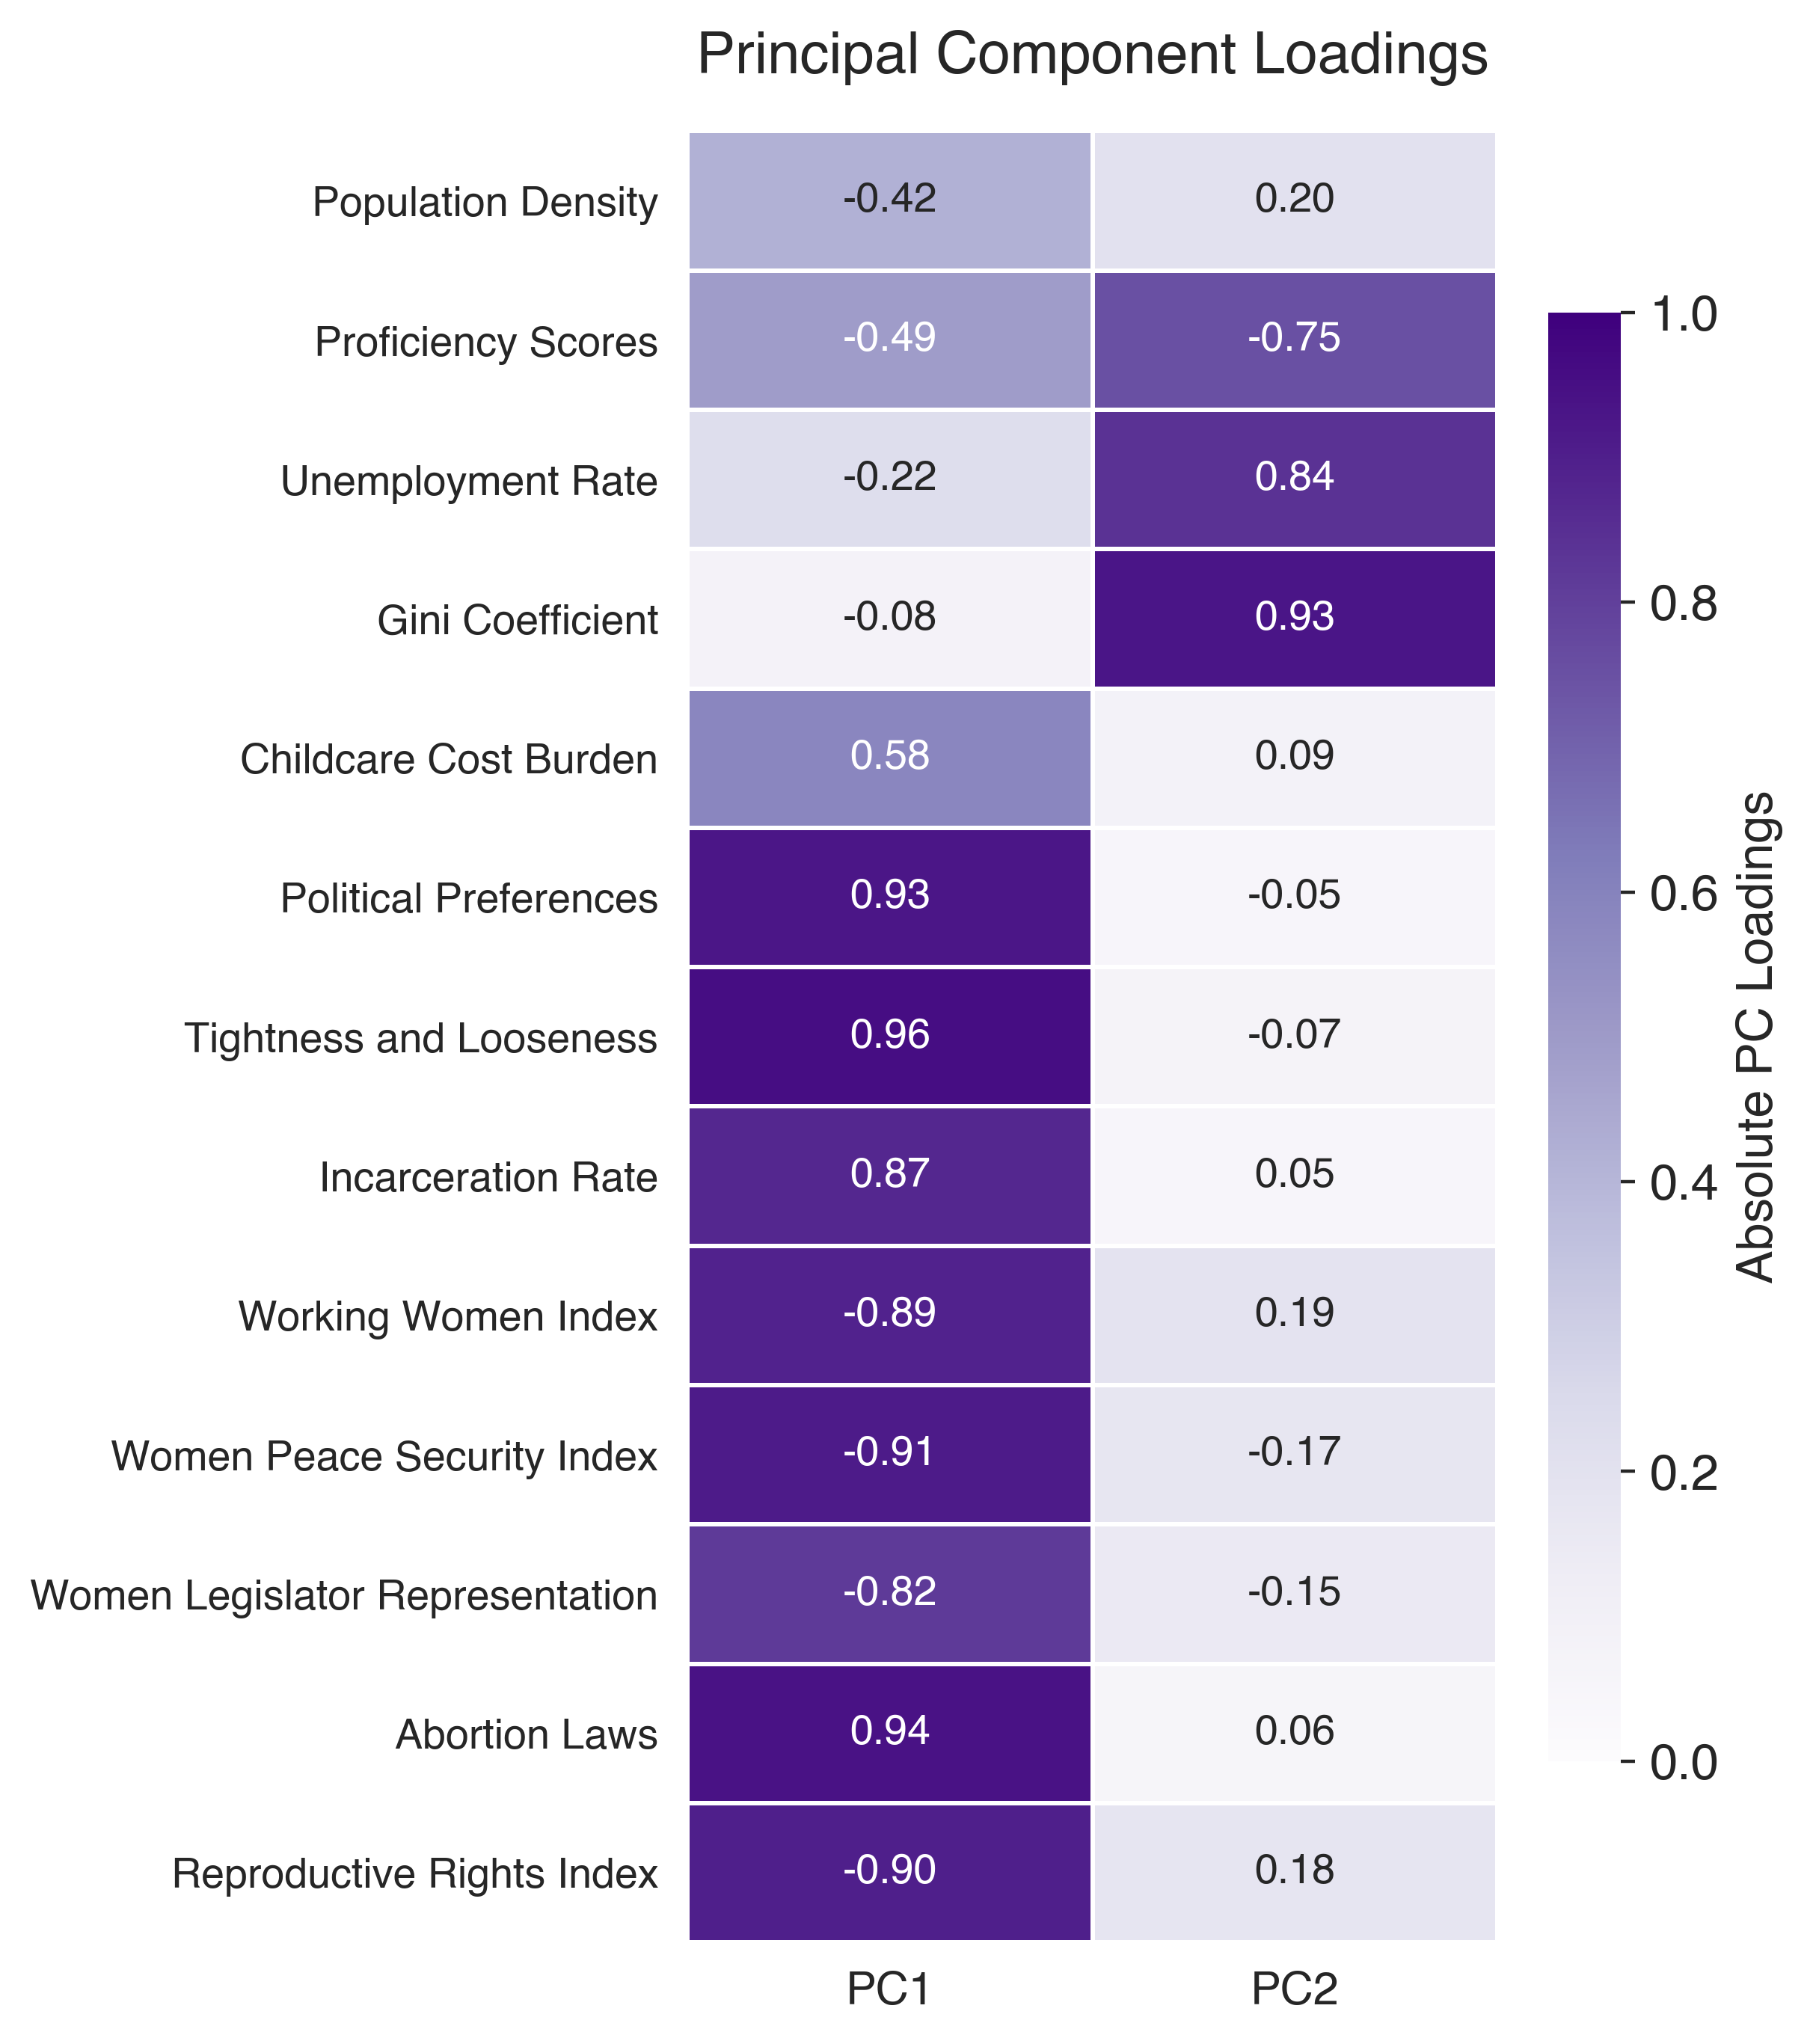

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


In [40]:
%config InlineBackend.figure_format = 'retina'

plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 1000,
    "font.family": "Arial",
    "font.size": 12,
    "text.antialiased": True,
    "patch.antialiased": True,
    "lines.antialiased": True,
    "svg.fonttype": "none",
    "pdf.fonttype": 42
})

# ============================================================
# PC1 AND PC2 LOADINGS HEATMAP
# ============================================================

# Keep PC1 and PC2
heatmap_data = loadings_df[["PC1", "PC2"]].copy()

# Absolute loadings determine purple intensity
heatmap_abs = heatmap_data.abs()

plt.rcParams["font.family"] = "Helvetica"

fig, ax = plt.subplots(
    figsize=(6, 7),
    facecolor="white"
)

ax.set_facecolor("white")

sns.heatmap(
    heatmap_abs,
    annot=heatmap_data,
    fmt=".2f",
    cmap="Purples",
    vmin=0,
    vmax=1,
    linewidths=1,
    linecolor="white",
    cbar_kws={
        "label": "Absolute PC Loadings",
        "shrink": 0.8
    },
    annot_kws={
        "fontsize": 10
    },
    ax=ax
)

ax.set_xlabel("")
ax.set_ylabel("")

ax.set_title(
    "Principal Component Loadings",
    fontsize=14,
    pad=14
)

ax.set_xticklabels(
    ["PC1", "PC2"],
    fontsize=11,
    rotation=0
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    fontsize=10,
    rotation=0
)

plt.tight_layout()

plt.show()
# Save as PDF (vector graphics)
fig.savefig(
    "PC1_PC2_loadings_heatmap.pdf",
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


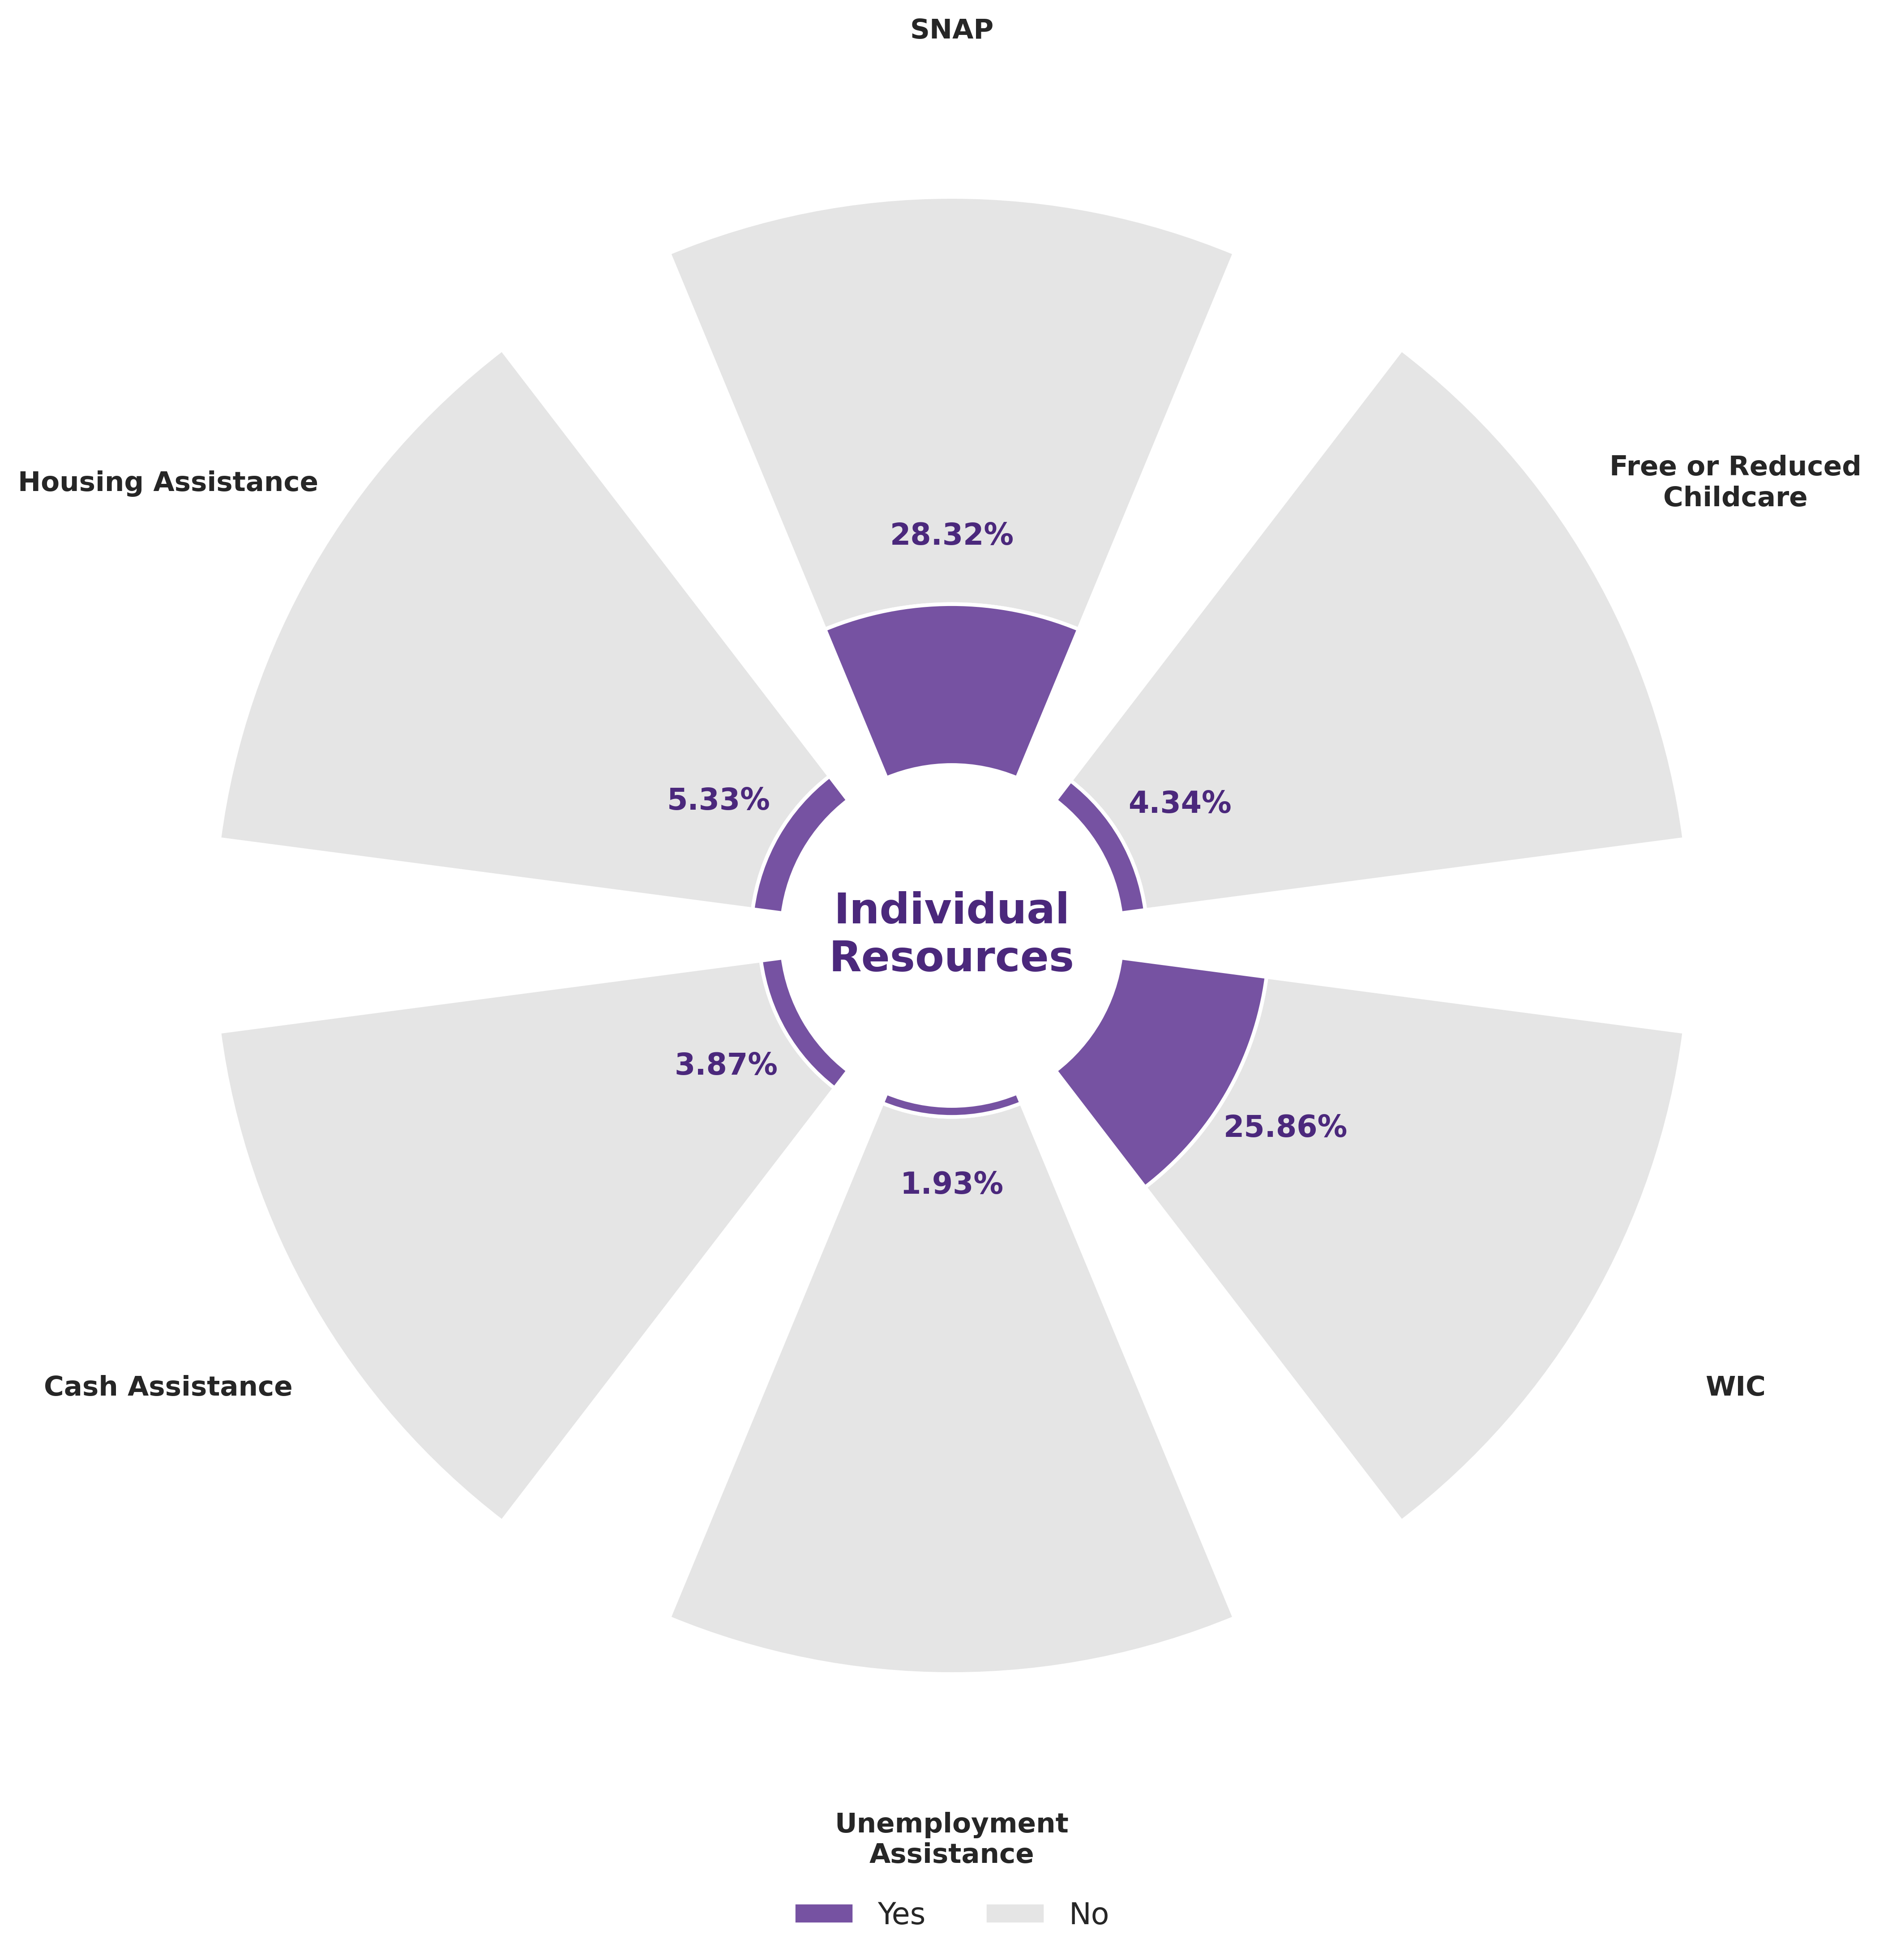

In [102]:
resources = [
    "SNAP",
    "Free or Reduced\nChildcare",
    "WIC",
    "Unemployment\nAssistance",
    "Cash Assistance",
    "Housing Assistance"
]

yes = np.array([28.32, 4.34, 25.86, 1.93, 3.87, 5.33])
no = 100 - yes

# Figure settings
plt.rcParams["font.family"] = "DejaVu Sans"

n = len(resources)
angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
bar_width = 2 * np.pi / n * 0.75
inner_radius = 30

fig, ax = plt.subplots(
    figsize=(11, 11),
    subplot_kw={"projection": "polar"}
)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# No segments (light gray)
ax.bar(
    angles,
    no,
    width=bar_width,
    bottom=inner_radius + yes,
    color="#E5E5E5",
    edgecolor="white",
    linewidth=1.5
)

# Yes segments (purple)
ax.bar(
    angles,
    yes,
    width=bar_width,
    bottom=inner_radius,
    color="#7652A2",
    edgecolor="white",
    linewidth=1.5
)

# Percentage labels on bars
for angle, pct in zip(angles, yes):
    ax.text(
        angle,
        inner_radius + pct + 12,
        f"{pct:.2f}%",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="#4B287C"
    )

# Resource labels
ax.set_xticks(angles)
ax.set_xticklabels(
    resources,
    fontsize=11,
    fontweight="bold"
)
ax.tick_params(axis="x", pad=22)

# Center label
ax.text(
    0,
    0,
    "Individual\nResources",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold",
    color="#4B287C"
)

# Formatting
ax.set_ylim(0, inner_radius + 115)
ax.set_yticks([])
ax.grid(False)
ax.spines["polar"].set_visible(False)

# Legend
ax.legend(
    handles=[
        Patch(facecolor="#7652A2", label="Yes"),
        Patch(facecolor="#E5E5E5", label="No")
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False,
    fontsize=12
)

# Move SNAP label closer to the circular bar
labels = ax.get_xticklabels()

labels[0].set_y(0)  # SNAP is the first label

#ax.set_title(
#    "Receipt of Individual Resources",
#    fontsize=18,
#    fontweight="bold",
#    pad=40
#)

plt.tight_layout()

plt.savefig(
    "individual_resources_stacked_radial.png",
    dpi=1000,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "individual_resources_stacked_radial.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [89]:
%run hbcd_h1_power_updated.py

{'moderator': 'cash_monthly_z', 'interaction_beta': 0.0, 'n_sim': 100, 'valid_fits': 81, 'convergence_rate': 0.81, 'power_unadjusted': 0.07407407407407407, 'mc_se': 0.029099044493273562}
{'moderator': 'cash_monthly_z', 'interaction_beta': 0.05, 'n_sim': 100, 'valid_fits': 81, 'convergence_rate': 0.81, 'power_unadjusted': 0.30864197530864196, 'mc_se': 0.05132589007920359}
{'moderator': 'cash_monthly_z', 'interaction_beta': 0.1, 'n_sim': 100, 'valid_fits': 80, 'convergence_rate': 0.8, 'power_unadjusted': 0.8625, 'mc_se': 0.03850223207815359}
{'moderator': 'cash_monthly_z', 'interaction_beta': 0.15, 'n_sim': 100, 'valid_fits': 85, 'convergence_rate': 0.85, 'power_unadjusted': 1.0, 'mc_se': 0.0}
{'moderator': 'cash_monthly_z', 'interaction_beta': 0.2, 'n_sim': 100, 'valid_fits': 72, 'convergence_rate': 0.72, 'power_unadjusted': 1.0, 'mc_se': 0.0}
{'moderator': 'cash_monthly_z', 'interaction_beta': 0.25, 'n_sim': 100, 'valid_fits': 89, 'convergence_rate': 0.89, 'power_unadjusted': 1.0, 'mc_

In [90]:
import pandas as pd

results = pd.read_csv("hbcd_h1_power_results.csv")

display(results.head(20))

,moderator,interaction_beta,n_sim,valid_fits,convergence_rate,power_unadjusted,mc_se
0,cash_monthly_z,0.00,100,81,0.81,0.074074,0.029099
1,cash_monthly_z,0.05,100,81,0.81,0.308642,0.051326
2,cash_monthly_z,0.10,100,80,0.80,0.862500,0.038502
3,cash_monthly_z,0.15,100,85,0.85,1.000000,0.000000
4,cash_monthly_z,0.20,100,72,0.72,1.000000,0.000000
5,cash_monthly_z,0.25,100,89,0.89,1.000000,0.000000
6,cash_monthly_z,0.30,100,81,0.81,1.000000,0.000000
7,rpp_z,0.00,100,72,0.72,0.027778,0.019367
8,rpp_z,0.05,100,76,0.76,0.394737,0.056069
9,rpp_z,0.10,100,81,0.81,0.962963,0.020984


In [92]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for moderator, df in results.groupby("moderator"):
    df = df.sort_values("effect_size")

    plt.plot(
        df["effect_size"],
        df["power"],
        marker="o",
        label=moderator
    )

plt.axhline(
    y=0.80,
    color="red",
    linestyle="--",
    label="80% power"
)

plt.xlabel("Standardized interaction effect size")
plt.ylabel("Statistical power")
plt.title("HBCD Hypothesis 1: Simulation-Based Power Analysis")

plt.legend()
plt.tight_layout()
plt.show()

KeyError: 'effect_size'

<Figure size 1800x1200 with 0 Axes>

Available columns: ['moderator', 'interaction_beta', 'n_sim', 'valid_fits', 'convergence_rate', 'power_unadjusted', 'mc_se']


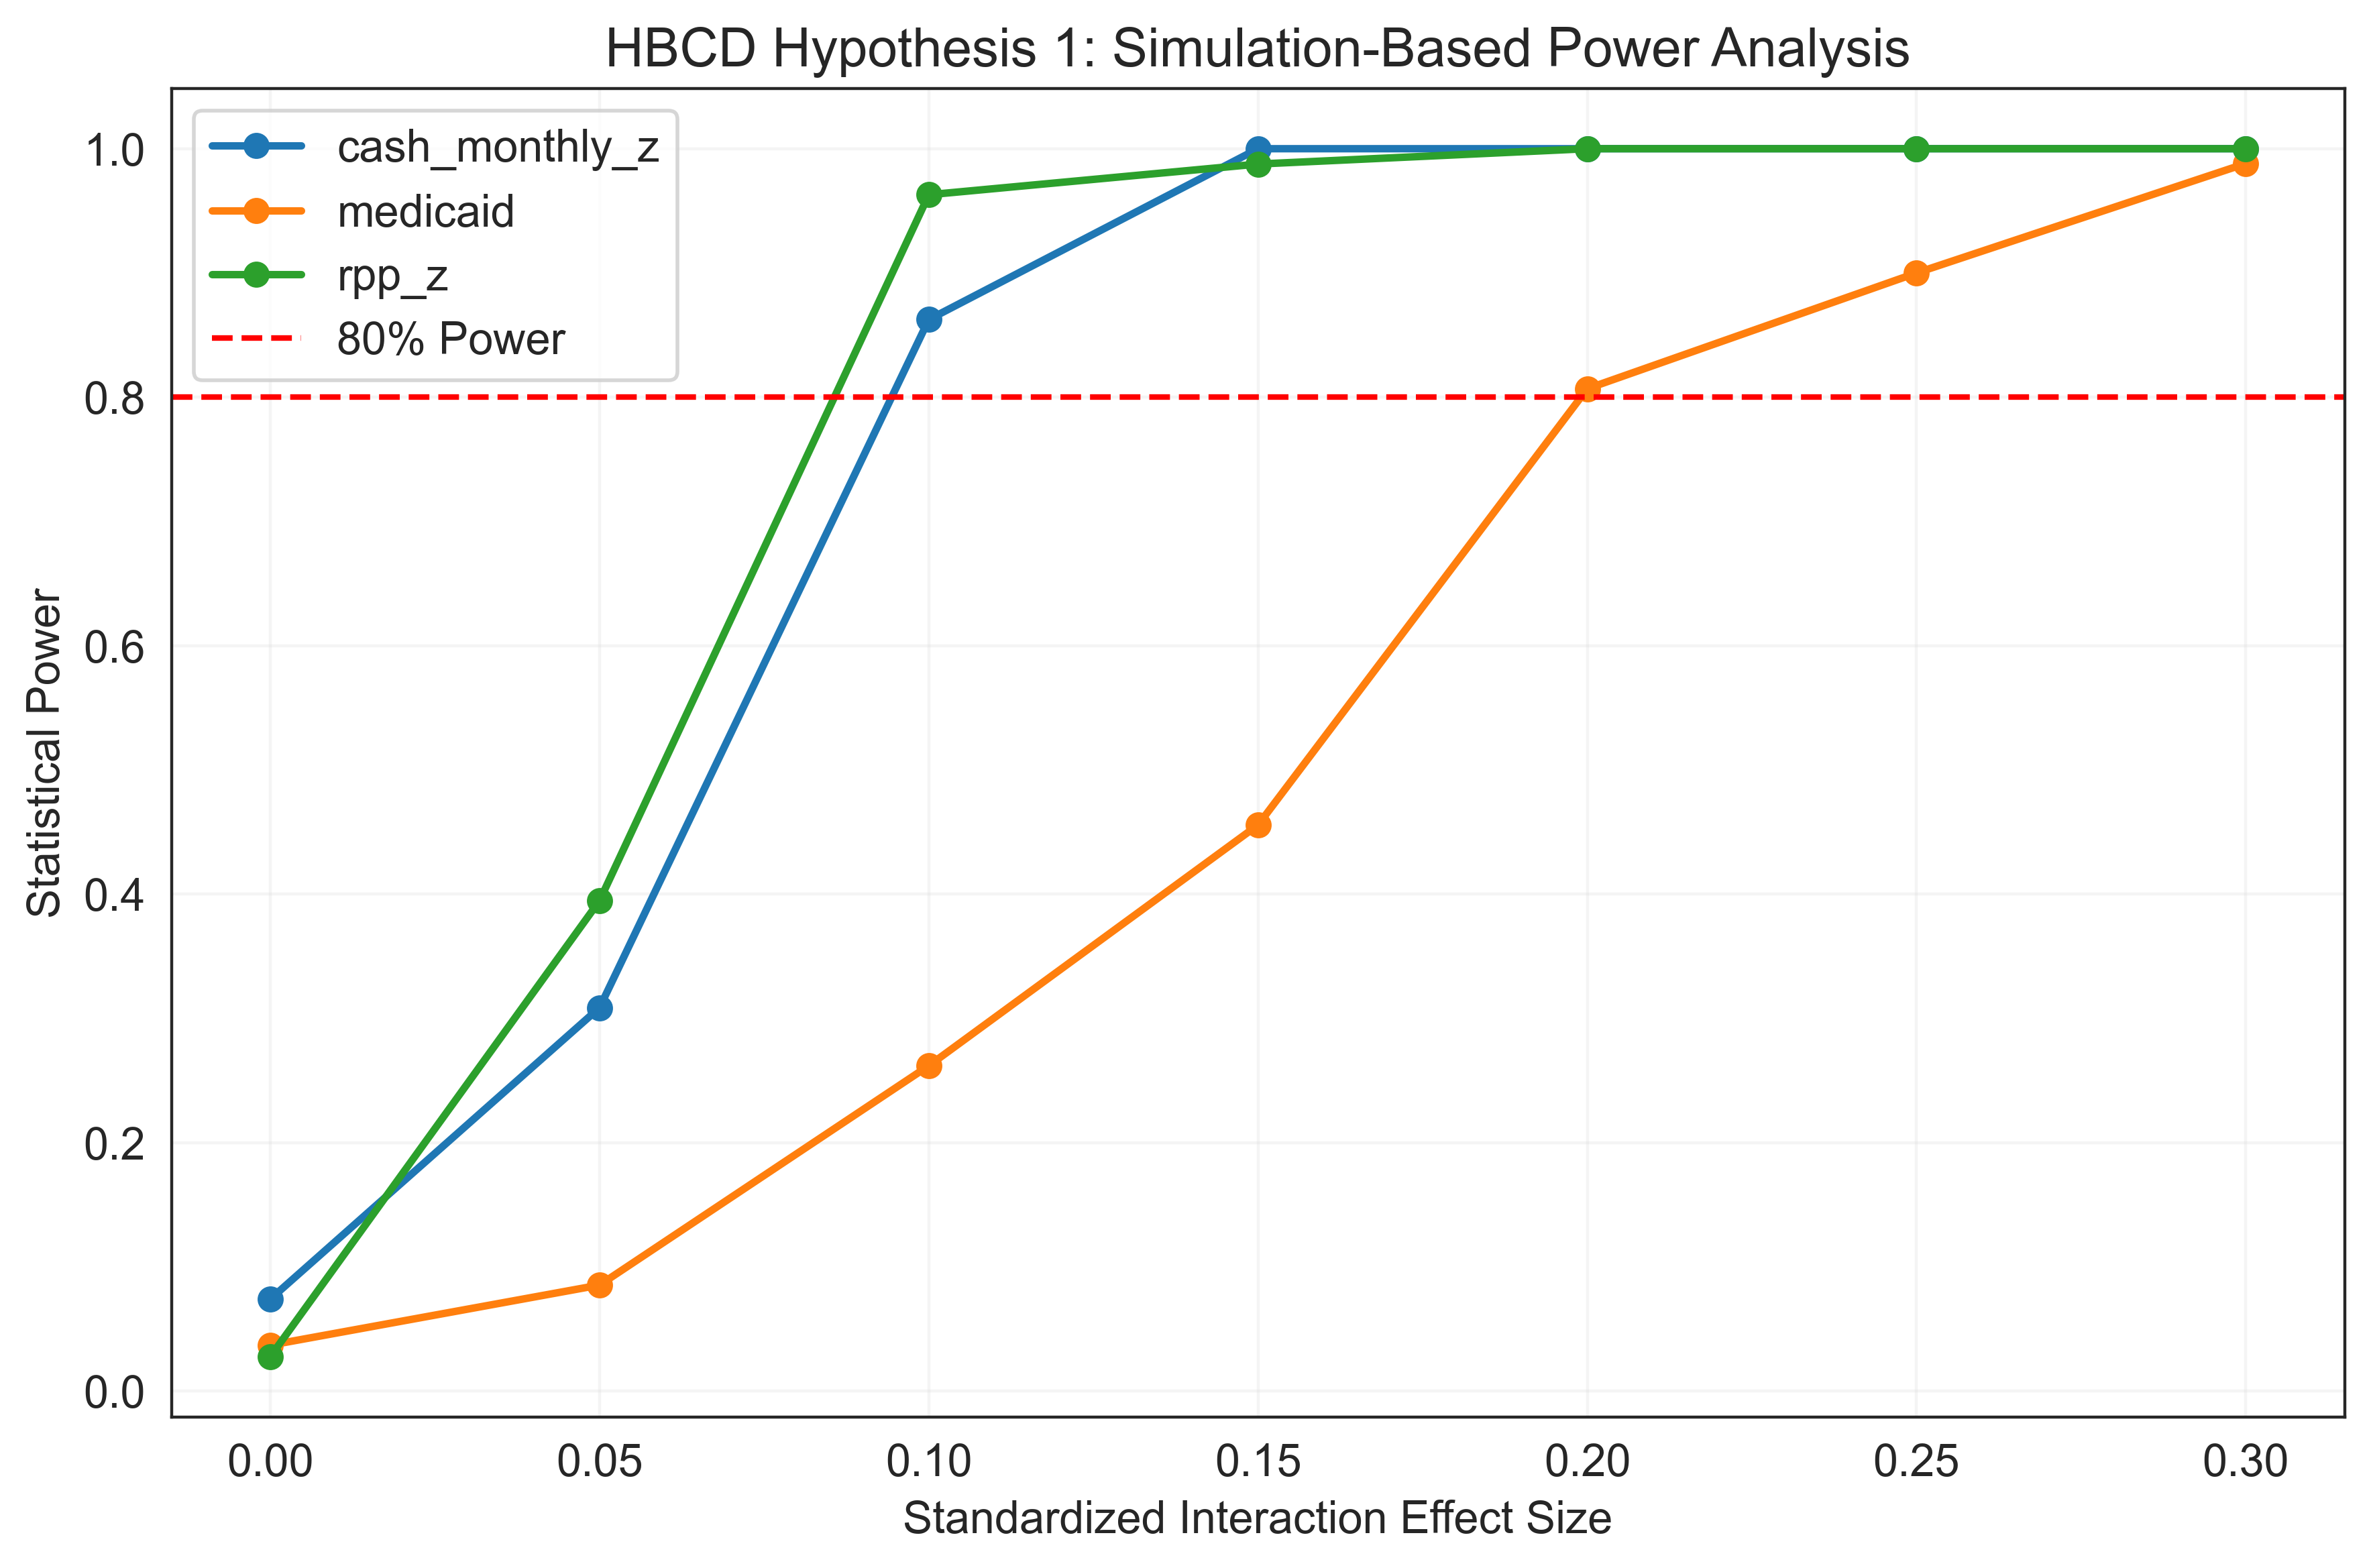

In [94]:
import pandas as pd
import matplotlib.pyplot as plt

# Remove accidental spaces in column names
results.columns = results.columns.str.strip()

print("Available columns:", results.columns.tolist())

# Find relevant columns
effect_candidates = [
    "effect_size", "beta_interaction", "beta",
    "interaction_beta", "true_beta"
]

power_candidates = [
    "power", "power_unadjusted",
    "estimated_power", "power_raw"
]

effect_col = next(
    (c for c in effect_candidates if c in results.columns),
    None
)

power_col = next(
    (c for c in power_candidates if c in results.columns),
    None
)

if effect_col is None or power_col is None:
    raise ValueError(
        "Could not identify effect-size or power columns. "
        f"Available columns: {results.columns.tolist()}"
    )

# Plot
plt.figure(figsize=(9, 6))

for moderator, df in results.groupby("moderator"):

    df = df.sort_values(effect_col)

    plt.plot(
        df[effect_col],
        df[power_col],
        marker="o",
        linewidth=2,
        label=moderator
    )

# Handle proportions versus percentages
power_max = results[power_col].max()
threshold = 80 if power_max > 1 else 0.80

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="80% Power"
)

plt.xlabel("Standardized Interaction Effect Size")
plt.ylabel("Statistical Power")
plt.title("HBCD Hypothesis 1: Simulation-Based Power Analysis")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [105]:
breakdown = pd.read_csv('/Users/jivesh/Downloads/data102826.csv').set_index('participant_id')
breakdown


,sed_basic_demographics_gestational_age_delivery,sed_basic_demographics_sex,sed_basic_demographics_child_race,sed_basic_demographics_child_ethnicity,sed_basic_demographics_gestational_age_delivery.1,sed_basic_demographics_rc_mother_education,sed_basic_demographics_recruitment_site,LR_hip_volume,img_mriqc_T2w_candidate_age,img_mriqc_T2w_adjusted_age,...,Association_UncinateFasciculus_dti_fa,ProjectionBasalGanglia_Fornix_dti_fa,Association_Cingulum_md,Association_UncinateFasciculus_md,ProjectionBasalGanglia_Fornix_md,sed_bm_demo_income_002,total_household_size,income_midpoint,pex_bm_apa_apa2_depr_promistscore,substance_use_total
participant_id,,,,,,,,,,,,,,,,,,,,,
sub-8012156453,40,0,0,1,40,1,0,1085.440052,0.068,3.0,...,0.205835,0.275675,1.241590,1.244700,1.393825,7,3,62499.5,55.1,1
sub-4044959361,40,1,0,1,40,3,0,1422.336068,0.068,3.0,...,0.231286,0.244577,1.271880,1.242420,1.244890,9,2,149999.5,38.2,1
sub-9656135401,39,0,1,1,39,3,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,5,0,29999.5,61.2,3
sub-8573430162,39,1,0,1,39,4,0,1287.680061,0.068,2.0,...,0.207940,0.231695,1.297810,1.309255,1.322240,8,1,87499.5,55.1,3
sub-4495347014,39,1,0,1,39,3,0,1504.768071,0.099,3.0,...,0.251680,0.279209,1.264175,1.235300,1.348920,10,4,200000.0,44.7,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sub-3580583838,39,0,5,1,39,4,26,1388.500021,0.060,2.0,...,NaN,NaN,NaN,NaN,NaN,9,3,149999.5,58.5,2
sub-6687322701,38,1,0,1,38,4,26,1297.800019,0.112,3.0,...,NaN,NaN,NaN,NaN,NaN,10,1,200000.0,38.2,3
sub-2777412042,39,0,0,0,39,2,26,1347.400020,0.088,3.0,...,0.242585,0.274418,1.302185,1.306885,1.336910,6,1,42499.5,38.2,2


In [3]:
%pip install numpy pandas scipy statsmodels matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.


HBCD H1 simulations:   0%|                                               | 0/30000 [00:00<?, ?fit/s]

Number of states: 20
Medicaid expansion counts:
medicaid
0     4
1    16
Name: count, dtype: int64


HBCD H1 simulations: 100%|████████████████████████████████| 30000/30000 [12:59:39<00:00,  1.56s/fit]


Simulation complete.


,moderator,interaction_beta,n_analysis,n_sim,n_valid,n_failed,convergence_rate,power_unadjusted,mc_se
0,cash_benefits,0.00,1500,1000,779,221,0.779,0.044929,0.007422
1,cash_benefits,0.05,1500,1000,793,207,0.793,0.509458,0.017752
2,cash_benefits,0.10,1500,1000,801,199,0.801,0.972534,0.005775
3,cash_benefits,0.15,1500,1000,823,177,0.823,1.000000,0.000000
4,cash_benefits,0.20,1500,1000,778,222,0.778,1.000000,0.000000
5,cash_benefits,0.25,1500,1000,771,229,0.771,1.000000,0.000000
6,cash_benefits,0.30,1500,1000,775,225,0.775,1.000000,0.000000
7,cash_benefits,0.35,1500,1000,799,201,0.799,1.000000,0.000000
8,cash_benefits,0.40,1500,1000,787,213,0.787,1.000000,0.000000
9,cash_benefits,0.50,1500,1000,781,219,0.781,1.000000,0.000000



Minimum tested effect reaching 95% power:
cash_benefits : 0.1
rpp : 0.1
medicaid : 0.25


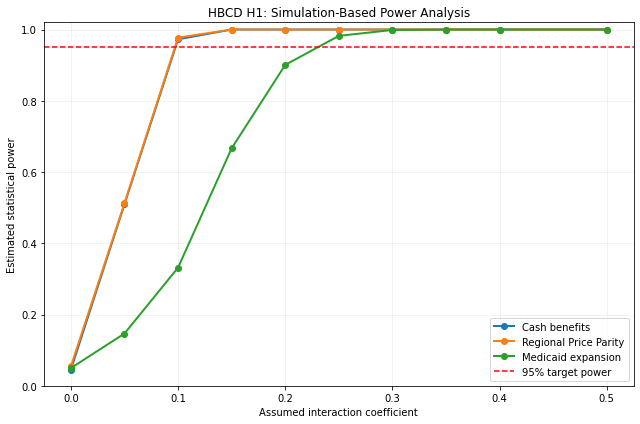

,moderator,interaction_beta,convergence_rate,n_failed
0,cash_benefits,0.00,0.779,221
1,cash_benefits,0.05,0.793,207
2,cash_benefits,0.10,0.801,199
3,cash_benefits,0.15,0.823,177
4,cash_benefits,0.20,0.778,222
5,cash_benefits,0.25,0.771,229
6,cash_benefits,0.30,0.775,225
7,cash_benefits,0.35,0.799,201
8,cash_benefits,0.40,0.787,213
9,cash_benefits,0.50,0.781,219



Results saved to: hbcd_h1_power_2026_results.csv


In [4]:
from scipy.stats import truncnorm, norm
from statsmodels.regression.mixed_linear_model import MixedLM
from tqdm import tqdm

# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 2026
rng = np.random.default_rng(SEED)

N_TOTAL = 1915
N_HIPPO = 1552
N_ANALYSIS = 1500

N_STATES = 20
N_SITES = 27

N_SIM = 1000
TARGET_POWER = 0.95
ALPHA = 0.05

EFFECTS = [
    0.00, 0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.35, 0.40, 0.50
]

MODERATORS = ["cash_benefits", "rpp", "medicaid"]

OUTPUT_FILE = "hbcd_h1_power_2026_results.csv"

# Illustrative variance components, in standardized
# outcome variance units. Change for sensitivity analyses.
VAR_STATE = 0.03
VAR_SITE = 0.04
VAR_FAMILY = 0.03
VAR_RESIDUAL = 0.90

# Assumed outcome effects, not observed HBCD estimates.
BETA_INCOME = 0.10
BETA_MODERATOR = 0.05

# Illustrative covariate coefficients
BETA_GESTATIONAL = 0.08
BETA_SCAN_AGE = 0.10
BETA_SEX = 0.05
BETA_ICV = 0.25

# ============================================================
# 2. ACTUAL 2023 STATE-LEVEL DATA
# ============================================================

states = [
    "Alabama", "Arkansas", "California", "Georgia",
    "Illinois", "Maryland", "Massachusetts", "Minnesota",
    "Missouri", "New Mexico", "New York", "North Carolina",
    "Ohio", "Oklahoma", "Oregon", "Pennsylvania",
    "Tennessee", "Vermont", "Virginia", "Wisconsin"
]

cash_benefits = [
    255, 249, 778, 287, 465,
    584, 583, 542, 308, 458,
    586, 283, 486, 300, 418,
    349, 341, 631, 423, 490
]

rpp = [
    0.89, 0.87, 1.12, 0.96, 0.99,
    1.05, 1.08, 0.98, 0.91, 0.91,
    1.08, 0.94, 0.92, 0.89, 1.05,
    0.97, 0.92, 0.97, 1.01, 0.93
]

medicaid = [
    0, 1, 1, 0, 1,
    1, 1, 1, 1, 1,
    1, 1, 1, 1, 1,
    1, 0, 1, 1, 0
]

state_df = pd.DataFrame({
    "state": states,
    "cash_benefits": cash_benefits,
    "rpp": rpp,
    "medicaid": medicaid
})

# Standardize continuous moderators across states.
# Medicaid remains binary.
for col in ["cash_benefits", "rpp"]:
    state_df[col + "_z"] = (
        (state_df[col] - state_df[col].mean())
        / state_df[col].std(ddof=0)
    )

print("Number of states:", len(state_df))
print("Medicaid expansion counts:")
print(state_df["medicaid"].value_counts().sort_index())

# ============================================================
# 3. UPDATED HBCD DEMOGRAPHIC DISTRIBUTIONS
# ============================================================

RACE_COUNTS = np.array([
    1050, 413, 59, 15, 273, 105
])

RACE_LABELS = [
    "White", "Black", "Asian",
    "AIAN", "Mixed", "Other"
]

EDUCATION_COUNTS = np.array([
    382, 432, 439, 662
])

INCOME_COUNTS = np.array([
    193, 94, 56, 75, 92,
    131, 192, 194, 564, 324
])

# Requested representative values for open-ended bands.
INCOME_MIDPOINTS = np.array([
    10000, 12500, 17500, 22500, 30000,
    42500, 62500, 87500, 150000, 200000
], dtype=float)

RACE_PROBS = RACE_COUNTS / RACE_COUNTS.sum()
EDUCATION_PROBS = (
    EDUCATION_COUNTS / EDUCATION_COUNTS.sum()
)
INCOME_PROBS = INCOME_COUNTS / INCOME_COUNTS.sum()

# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def standardize(x):
    x = np.asarray(x, dtype=float)
    sd = np.std(x, ddof=0)
    if sd == 0:
        return np.zeros_like(x)
    return (x - np.mean(x)) / sd


def truncated_normal(mean, sd, low, high, n, rng):
    a = (low - mean) / sd
    b = (high - mean) / sd

    return truncnorm.rvs(
        a, b,
        loc=mean,
        scale=sd,
        size=n,
        random_state=rng
    )


# ============================================================
# 5. GENERATE AN ILLUSTRATIVE HBCD SAMPLE
# ============================================================

def generate_design(n, rng):

    # State allocation is assumed equal, not observed.
    state_ids = np.arange(n) % N_STATES
    rng.shuffle(state_ids)

    # Illustrative allocation of 27 sites across 20 states.
    # Seven states have two sites; others have one.
    site_ids = np.empty(n, dtype=int)

    sites_per_state = [
        2 if s < 7 else 1 for s in range(N_STATES)
    ]

    site_counter = 0

    for s, count in enumerate(sites_per_state):
        idx = np.where(state_ids == s)[0]

        available_sites = np.arange(
            site_counter, site_counter + count
        )

        site_ids[idx] = rng.choice(
            available_sites, size=len(idx)
        )

        site_counter += count

    # Simulate mostly singleton families with some siblings.
    # The sibling proportion is an assumption.
    family_ids = np.arange(n)

    for s in range(N_STATES):
        idx = np.where(state_ids == s)[0]
        rng.shuffle(idx)

        n_pairs = int(len(idx) * 0.05)

        for j in range(n_pairs):
            a = idx[2 * j]
            b = idx[2 * j + 1]
            family_ids[b] = family_ids[a]

    gestational_age = truncated_normal(
        38.52, 1.79, 25, 45, n, rng
    )

    scan_age = truncated_normal(
        3.05, 1.82, 0, 16, n, rng
    )

    sex_male = rng.binomial(1, 1005 / 1915, n)

    race = rng.choice(
        RACE_LABELS, size=n, p=RACE_PROBS
    )

    hispanic = rng.binomial(1, 389 / 1915, n)

    education = rng.choice(
        np.arange(4),
        size=n,
        p=EDUCATION_PROBS
    )

    income_band = rng.choice(
        np.arange(10),
        size=n,
        p=INCOME_PROBS
    )

    family_income = INCOME_MIDPOINTS[income_band]

    # Log income is a proxy, not true income-to-needs.
    income_z = standardize(np.log(family_income))

    # ICV distribution is not available.
    # This is an illustrative standardized covariate.
    icv_z = standardize(rng.normal(size=n))

    # Scanner manufacturer is not available.
    # Synthetic categories are assigned by site.
    manufacturer_by_site = rng.choice(
        ["GE", "Philips", "Siemens"],
        size=N_SITES,
        p=[0.25, 0.15, 0.60]
    )

    df = pd.DataFrame({
        "state_id": state_ids,
        "site_id": site_ids,
        "family_id": family_ids,
        "gestational_z": standardize(gestational_age),
        "scan_age_z": standardize(scan_age),
        "sex_male": sex_male,
        "race": race,
        "hispanic": hispanic,
        "education": education,
        "income_z": income_z,
        "icv_z": icv_z,
        "manufacturer": manufacturer_by_site[site_ids]
    })

    df["state"] = state_df.loc[
        df["state_id"], "state"
    ].to_numpy()

    df = df.merge(
        state_df[
            ["state", "cash_benefits_z", "rpp_z", "medicaid"]
        ],
        on="state",
        how="left",
        validate="many_to_one"
    )

    return df


# ============================================================
# 6. SIMULATE HIPPOCAMPAL VOLUME
# ============================================================

def simulate_outcome(df, moderator, beta, rng):

    n = len(df)

    if moderator == "cash_benefits":
        m = df["cash_benefits_z"].to_numpy()
    elif moderator == "rpp":
        m = df["rpp_z"].to_numpy()
    elif moderator == "medicaid":
        m = df["medicaid"].to_numpy()
    else:
        raise ValueError("Unknown moderator")

    x = df["income_z"].to_numpy()

    state_effects = rng.normal(
        0, np.sqrt(VAR_STATE), N_STATES
    )

    site_effects = rng.normal(
        0, np.sqrt(VAR_SITE), N_SITES
    )

    family_codes, _ = pd.factorize(df["family_id"])

    family_effects = rng.normal(
        0,
        np.sqrt(VAR_FAMILY),
        len(np.unique(family_codes))
    )

    # Illustrative nuisance effects
    race_effect = {
        "White": 0.0,
        "Black": 0.02,
        "Asian": -0.02,
        "AIAN": 0.01,
        "Mixed": 0.01,
        "Other": 0.0
    }

    education_effect = np.array([
        -0.04, -0.02, 0.00, 0.02
    ])

    manufacturer_effect = {
        "GE": 0.02,
        "Philips": -0.02,
        "Siemens": 0.0
    }

    fixed = (
        BETA_INCOME * x
        + BETA_MODERATOR * m
        + beta * x * m
        + BETA_GESTATIONAL * df["gestational_z"].to_numpy()
        + BETA_SCAN_AGE * df["scan_age_z"].to_numpy()
        + BETA_SEX * df["sex_male"].to_numpy()
        + BETA_ICV * df["icv_z"].to_numpy()
        + df["race"].map(race_effect).to_numpy()
        + education_effect[df["education"].to_numpy()]
        + 0.02 * df["hispanic"].to_numpy()
        + df["manufacturer"].map(
            manufacturer_effect
        ).to_numpy()
    )

    random_part = (
        state_effects[df["state_id"].to_numpy()]
        + site_effects[df["site_id"].to_numpy()]
        + family_effects[family_codes]
        + rng.normal(
            0, np.sqrt(VAR_RESIDUAL), n
        )
    )

    # Outcome in standardized-volume units.
    # Do not restandardize after adding the interaction.
    y_z = fixed + random_part

    # Translate to approximate hippocampal-volume units.
    return 1220 + 187 * y_z


# ============================================================
# 7. FIT LINEAR MIXED-EFFECTS MODEL
# ============================================================

def fit_interaction(df, moderator):

    moderator_col = {
        "cash_benefits": "cash_benefits_z",
        "rpp": "rpp_z",
        "medicaid": "medicaid"
    }[moderator]

    data = df.copy()

    data["moderator_value"] = data[moderator_col]
    data["interaction"] = (
        data["income_z"] * data["moderator_value"]
    )

    # Scale outcome to improve numerical conditioning.
    data["hippo_z"] = (
        data["hippocampal_volume"] - 1220
    ) / 187

    fixed_formula = (
        "hippo_z ~ income_z + moderator_value "
        "+ interaction + gestational_z + scan_age_z "
        "+ sex_male + icv_z + hispanic "
        "+ C(race) + C(education) + C(manufacturer)"
    )

    # State random intercept, plus site and family
    # variance components. Family IDs are nested in state.
    model = MixedLM.from_formula(
        fixed_formula,
        data=data,
        groups="state_id",
        re_formula="1",
        vc_formula={
            "site": "0 + C(site_id)",
            "family": "0 + C(family_id)"
        }
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        fit = model.fit(
            reml=False,
            method="lbfgs",
            maxiter=200,
            disp=False
        )

    if not fit.converged:
        return np.nan, False

    p = float(fit.pvalues["interaction"])

    return p, True


# ============================================================
# 8. MONTE CARLO POWER SIMULATION
# ============================================================

def run_power_analysis():

    total = (
        len(MODERATORS) * len(EFFECTS) * N_SIM
    )

    records = []

    with tqdm(
        total=total,
        desc="HBCD H1 simulations",
        unit="fit",
        ncols=100,
        mininterval=1
    ) as progress:

        for moderator in MODERATORS:

            for beta in EFFECTS:

                pvalues = []
                n_failed = 0

                for sim in range(N_SIM):

                    # Reproducible independent random streams
                    # from the main generator.
                    local_rng = np.random.default_rng(
                        rng.integers(0, 2**32 - 1)
                    )

                    try:
                        df = generate_design(
                            N_ANALYSIS, local_rng
                        )

                        df["hippocampal_volume"] = (
                            simulate_outcome(
                                df,
                                moderator,
                                beta,
                                local_rng
                            )
                        )

                        p, converged = fit_interaction(
                            df, moderator
                        )

                        if converged and np.isfinite(p):
                            pvalues.append(p)
                        else:
                            n_failed += 1

                    except Exception:
                        n_failed += 1

                    progress.update(1)

                n_valid = len(pvalues)

                if n_valid > 0:
                    power = np.mean(
                        np.asarray(pvalues) < ALPHA
                    )
                    mc_se = np.sqrt(
                        power * (1 - power) / n_valid
                    )
                else:
                    power = np.nan
                    mc_se = np.nan

                records.append({
                    "moderator": moderator,
                    "interaction_beta": beta,
                    "n_analysis": N_ANALYSIS,
                    "n_sim": N_SIM,
                    "n_valid": n_valid,
                    "n_failed": n_failed,
                    "convergence_rate": n_valid / N_SIM,
                    "power_unadjusted": power,
                    "mc_se": mc_se
                })

                # Save after each completed scenario.
                pd.DataFrame(records).to_csv(
                    OUTPUT_FILE, index=False
                )

    return pd.DataFrame(records)


# ============================================================
# 9. EXECUTE SIMULATIONS
# ============================================================

results = run_power_analysis()

print("\nSimulation complete.")
display(results)

# ============================================================
# 10. FIND MINIMUM DETECTABLE EFFECT
# ============================================================

print("\nMinimum tested effect reaching 95% power:")

for moderator in MODERATORS:

    sub = results[
        (results["moderator"] == moderator)
        & (results["power_unadjusted"] >= TARGET_POWER)
    ].sort_values("interaction_beta")

    if len(sub) == 0:
        print(
            moderator,
            ": No tested effect reached 95% power."
        )
    else:
        print(
            moderator,
            ":",
            sub.iloc[0]["interaction_beta"]
        )

# ============================================================
# 11. PLOT POWER CURVES
# ============================================================

plt.figure(figsize=(9, 6))

labels = {
    "cash_benefits": "Cash benefits",
    "rpp": "Regional Price Parity",
    "medicaid": "Medicaid expansion"
}

for moderator in MODERATORS:

    sub = results[
        results["moderator"] == moderator
    ].sort_values("interaction_beta")

    plt.plot(
        sub["interaction_beta"],
        sub["power_unadjusted"],
        marker="o",
        linewidth=2,
        label=labels[moderator]
    )

plt.axhline(
    TARGET_POWER,
    linestyle="--",
    color="red",
    label="95% target power"
)

plt.xlabel("Assumed interaction coefficient")
plt.ylabel("Estimated statistical power")
plt.title("HBCD H1: Simulation-Based Power Analysis")

plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ============================================================
# 12. MODEL CONVERGENCE DIAGNOSTICS
# ============================================================

display(
    results[
        [
            "moderator",
            "interaction_beta",
            "convergence_rate",
            "n_failed"
        ]
    ]
)

print("\nResults saved to:", OUTPUT_FILE)



In [5]:
import pandas as pd

results = pd.read_csv("hbcd_h1_power_2026_results.csv")

null_results = results[
    results["interaction_beta"] == 0
].copy()

display(
    null_results[
        [
            "moderator",
            "power_unadjusted",
            "mc_se",
            "convergence_rate",
            "n_failed"
        ]
    ].rename(
        columns={
            "power_unadjusted": "type1_error_rate"
        }
    )
)

,moderator,type1_error_rate,mc_se,convergence_rate,n_failed
0,cash_benefits,0.044929,0.007422,0.779,221
10,rpp,0.054569,0.008091,0.788,212
20,medicaid,0.049682,0.007755,0.785,215


Optimizer diagnostics:   0%|                                               | 0/300 [00:00<?, ?fit/s]

Starting HBCD H1 convergence diagnostics
Moderator: cash_benefits
Interaction beta: 0.0
Simulations: 100
Optimizers: ['lbfgs', 'bfgs', 'powell']



Optimizer diagnostics: 100%|█████████████████████████████████████| 300/300 [10:01<00:00,  2.01s/fit]


Diagnostics complete.

OPTIMIZER COMPARISON


,optimizer,n_fits,convergence_rate,usable_rate,mean_seconds,median_seconds,boundary_rate,mean_warnings
0,bfgs,100,7.0,7.0,1.87,1.65,9.0,3.63
1,lbfgs,100,85.0,85.0,1.68,1.33,12.0,1.20
2,powell,100,100.0,100.0,2.46,1.95,62.0,1.68



TYPE I ERROR (NULL INTERACTION)


,optimizer,n_valid,type1_error
0,bfgs,7,0.1429
1,lbfgs,85,0.0588
2,powell,100,0.0700



EXCEPTIONS BY OPTIMIZER
No fitting exceptions recorded.


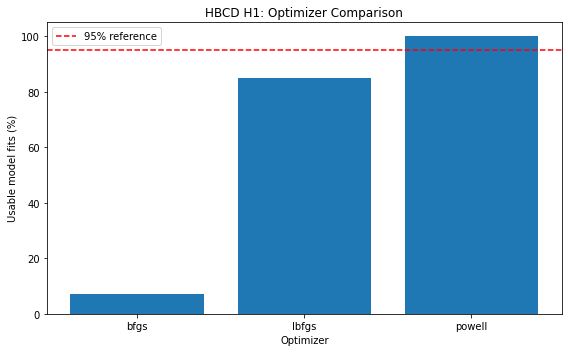


BEST OBSERVED OPTIMIZER
Optimizer: powell
Usable fits: 100.0 %
Mean fit time: 2.46 seconds

Saved: hbcd_optimizer_diagnostics.csv


In [6]:

# ============================================================
# HBCD H1: MIXED-MODEL CONVERGENCE DIAGNOSTICS
# Compare L-BFGS, BFGS, and Powell on identical datasets
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from statsmodels.regression.mixed_linear_model import MixedLM

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

N_DIAGNOSTIC = 100
DIAGNOSTIC_SEED = 20261030

OPTIMIZERS = ["lbfgs", "bfgs", "powell"]

# Start with the null interaction, which is useful for
# investigating convergence and Type I error.
DIAGNOSTIC_MODERATOR = "cash_benefits"
DIAGNOSTIC_BETA = 0.00

# Use 1500 to match your previous power simulation.
DIAGNOSTIC_N = 1500

diagnostic_rng = np.random.default_rng(DIAGNOSTIC_SEED)

# ------------------------------------------------------------
# 2. GENERATE ONE SIMULATED DATASET
# ------------------------------------------------------------

def make_diagnostic_dataset(rng, moderator, beta, n):

    df = generate_design(n, rng)

    df["hippocampal_volume"] = simulate_outcome(
        df, moderator, beta, rng
    )

    moderator_col = {
        "cash_benefits": "cash_benefits_z",
        "rpp": "rpp_z",
        "medicaid": "medicaid"
    }[moderator]

    df["moderator_value"] = df[moderator_col]

    df["interaction"] = (
        df["income_z"] * df["moderator_value"]
    )

    df["hippo_z"] = (
        df["hippocampal_volume"] - 1220
    ) / 187

    return df


# ------------------------------------------------------------
# 3. FIT MODEL USING SPECIFIED OPTIMIZER
# ------------------------------------------------------------

def fit_diagnostic_model(df, optimizer):

    formula = (
        "hippo_z ~ income_z + moderator_value "
        "+ interaction + gestational_z + scan_age_z "
        "+ sex_male + icv_z + hispanic "
        "+ C(race) + C(education) + C(manufacturer)"
    )

    start = time.perf_counter()

    result = {
        "optimizer": optimizer,
        "converged": False,
        "valid_pvalue": False,
        "p_interaction": np.nan,
        "beta_interaction": np.nan,
        "se_interaction": np.nan,
        "state_variance": np.nan,
        "site_variance": np.nan,
        "family_variance": np.nan,
        "residual_variance": np.nan,
        "boundary_component": False,
        "warning_count": 0,
        "warning_messages": "",
        "error": ""
    }

    try:
        model = MixedLM.from_formula(
            formula,
            data=df,
            groups="state_id",
            re_formula="1",
            vc_formula={
                "site": "0 + C(site_id)",
                "family": "0 + C(family_id)"
            }
        )

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")

            fit = model.fit(
                reml=False,
                method=optimizer,
                maxiter=500,
                disp=False
            )

        result["warning_count"] = len(caught)
        result["warning_messages"] = " | ".join(
            str(w.message) for w in caught
        )[:1000]

        result["converged"] = bool(fit.converged)

        p = float(fit.pvalues["interaction"])

        result["p_interaction"] = p
        result["valid_pvalue"] = bool(np.isfinite(p))

        result["beta_interaction"] = float(
            fit.params["interaction"]
        )

        result["se_interaction"] = float(
            fit.bse["interaction"]
        )

        # Variances are expressed in outcome-scale units.
        state_var = float(fit.cov_re.iloc[0, 0])

        result["state_variance"] = state_var
        result["residual_variance"] = float(fit.scale)

        # Match variance components by name, not position.
        variance_lookup = dict(
            zip(model.exog_vc.names, fit.vcomp)
        )

        result["site_variance"] = float(
            variance_lookup.get("site", np.nan)
        )

        result["family_variance"] = float(
            variance_lookup.get("family", np.nan)
        )

        variance_values = np.array([
            result["state_variance"],
            result["site_variance"],
            result["family_variance"]
        ])

        # Heuristic flag for variance estimates near zero.
        result["boundary_component"] = bool(
            np.any(
                variance_values
                < 1e-4 * result["residual_variance"]
            )
        )

    except Exception as e:
        result["error"] = (
            type(e).__name__ + ": " + str(e)
        )[:1000]

    result["elapsed_seconds"] = (
        time.perf_counter() - start
    )

    result["usable"] = (
        result["converged"]
        and result["valid_pvalue"]
    )

    return result


# ------------------------------------------------------------
# 4. RUN DIAGNOSTIC SIMULATIONS
# ------------------------------------------------------------

diagnostic_records = []

print("Starting HBCD H1 convergence diagnostics")
print("Moderator:", DIAGNOSTIC_MODERATOR)
print("Interaction beta:", DIAGNOSTIC_BETA)
print("Simulations:", N_DIAGNOSTIC)
print("Optimizers:", OPTIMIZERS)
print()

with tqdm(
    total=N_DIAGNOSTIC * len(OPTIMIZERS),
    desc="Optimizer diagnostics",
    unit="fit",
    ncols=100,
    mininterval=1
) as progress:

    for simulation in range(N_DIAGNOSTIC):

        local_rng = np.random.default_rng(
            diagnostic_rng.integers(0, 2**32 - 1)
        )

        # Generate ONCE per simulation so all optimizers
        # are evaluated on the same dataset.
        df = make_diagnostic_dataset(
            local_rng,
            DIAGNOSTIC_MODERATOR,
            DIAGNOSTIC_BETA,
            DIAGNOSTIC_N
        )

        for optimizer in OPTIMIZERS:

            record = fit_diagnostic_model(
                df, optimizer
            )

            record["simulation"] = simulation + 1
            record["moderator"] = DIAGNOSTIC_MODERATOR
            record["true_beta"] = DIAGNOSTIC_BETA

            diagnostic_records.append(record)

            progress.update(1)

        # Save every 10 datasets to protect against
        # interruption.
        if (simulation + 1) % 10 == 0:
            pd.DataFrame(diagnostic_records).to_csv(
                "hbcd_optimizer_diagnostics.csv",
                index=False
            )

diagnostics = pd.DataFrame(diagnostic_records)

diagnostics.to_csv(
    "hbcd_optimizer_diagnostics.csv",
    index=False
)

print("\nDiagnostics complete.")


# ------------------------------------------------------------
# 5. COMPARE CONVERGENCE RATES
# ------------------------------------------------------------

summary = (
    diagnostics
    .groupby("optimizer")
    .agg(
        n_fits=("usable", "size"),
        convergence_rate=("converged", "mean"),
        usable_rate=("usable", "mean"),
        mean_seconds=("elapsed_seconds", "mean"),
        median_seconds=("elapsed_seconds", "median"),
        boundary_rate=("boundary_component", "mean"),
        mean_warnings=("warning_count", "mean")
    )
    .reset_index()
)

summary["convergence_rate"] *= 100
summary["usable_rate"] *= 100
summary["boundary_rate"] *= 100

print("\nOPTIMIZER COMPARISON")
display(summary.round(2))


# ------------------------------------------------------------
# 6. TYPE I ERROR AMONG USABLE MODELS
# ------------------------------------------------------------

if DIAGNOSTIC_BETA == 0:

    type1 = (
        diagnostics[diagnostics["usable"]]
        .groupby("optimizer")
        .agg(
            n_valid=("p_interaction", "size"),
            type1_error=(
                "p_interaction",
                lambda p: np.mean(p < 0.05)
            )
        )
        .reset_index()
    )

    print("\nTYPE I ERROR (NULL INTERACTION)")
    display(type1.round(4))


# ------------------------------------------------------------
# 7. SUMMARIZE FITTING ERRORS
# ------------------------------------------------------------

errors = diagnostics[
    diagnostics["error"] != ""
]

print("\nEXCEPTIONS BY OPTIMIZER")

if len(errors):
    display(
        errors.groupby(
            ["optimizer", "error"]
        ).size().reset_index(name="count")
    )
else:
    print("No fitting exceptions recorded.")


# ------------------------------------------------------------
# 8. PLOT CONVERGENCE RATES
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    summary["optimizer"],
    summary["usable_rate"]
)

plt.axhline(
    95,
    color="red",
    linestyle="--",
    label="95% reference"
)

plt.ylim(0, 105)
plt.xlabel("Optimizer")
plt.ylabel("Usable model fits (%)")
plt.title("HBCD H1: Optimizer Comparison")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. IDENTIFY BEST OPTIMIZER
# ------------------------------------------------------------

best = summary.sort_values(
    ["usable_rate", "mean_seconds"],
    ascending=[False, True]
).iloc[0]

print("\nBEST OBSERVED OPTIMIZER")
print("Optimizer:", best["optimizer"])
print(
    "Usable fits:",
    round(best["usable_rate"], 2),
    "%"
)
print(
    "Mean fit time:",
    round(best["mean_seconds"], 2),
    "seconds"
)

print("\nSaved: hbcd_optimizer_diagnostics.csv")


In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv("hbcd_optimizer_diagnostics.csv")

# Compare the same simulated datasets across optimizers
paired = df[df["optimizer"].isin(["lbfgs", "powell"])]

wide = paired.pivot(
    index="simulation",
    columns="optimizer",
    values=[
        "converged",
        "beta_interaction",
        "se_interaction",
        "state_variance",
        "site_variance",
        "family_variance",
        "residual_variance"
    ]
)

# Keep datasets where both optimizers converged
both = wide[
    (wide[("converged", "lbfgs")] == True) &
    (wide[("converged", "powell")] == True)
].copy()

print("Datasets where both optimizers converged:", len(both))

parameters = [
    "beta_interaction",
    "se_interaction",
    "state_variance",
    "site_variance",
    "family_variance",
    "residual_variance"
]

comparison = []

for parameter in parameters:
    a = pd.to_numeric(both[(parameter, "lbfgs")])
    b = pd.to_numeric(both[(parameter, "powell")])

    comparison.append({
        "parameter": parameter,
        "lbfgs_mean": a.mean(),
        "powell_mean": b.mean(),
        "mean_absolute_difference": (a - b).abs().mean(),
        "max_absolute_difference": (a - b).abs().max()
    })

comparison = pd.DataFrame(comparison)

display(comparison.round(5))

Datasets where both optimizers converged: 85


,parameter,lbfgs_mean,powell_mean,mean_absolute_difference,max_absolute_difference
0,beta_interaction,0.00169,0.00162,0.00062,0.00360
1,se_interaction,0.02513,0.02514,0.00004,0.00091
2,state_variance,0.02374,0.02009,0.01239,0.07419
3,site_variance,0.03781,0.03818,0.01444,0.09034
4,family_variance,0.08865,0.05834,0.05466,0.20472
5,residual_variance,0.83344,0.86323,0.05380,0.19928


HBCD H1 simulations: 100%|█| 30000/30000 [17:08:35<00:00,  2.06s/fit, mod=medicaid, beta=0.5, valid=


SIMULATION COMPLETE


,moderator,interaction_beta,n_analysis,n_sim,n_valid,n_failed,convergence_rate,power_unadjusted,mc_se,success_lbfgs,success_powell,nonconvergence,invalid_pvalue,exception
0,cash_benefits,0.00,1500,1000,1000,0,1.000,0.044000,0.006486,779,221,0,0,0
1,cash_benefits,0.05,1500,1000,1000,0,1.000,0.508000,0.015809,793,207,0,0,0
2,cash_benefits,0.10,1500,1000,1000,0,1.000,0.975000,0.004937,801,199,0,0,0
3,cash_benefits,0.15,1500,1000,1000,0,1.000,1.000000,0.000000,823,177,0,0,0
4,cash_benefits,0.20,1500,1000,1000,0,1.000,1.000000,0.000000,778,222,0,0,0
5,cash_benefits,0.25,1500,1000,1000,0,1.000,1.000000,0.000000,771,229,0,0,0
6,cash_benefits,0.30,1500,1000,1000,0,1.000,1.000000,0.000000,775,225,0,0,0
7,cash_benefits,0.35,1500,1000,1000,0,1.000,1.000000,0.000000,799,201,0,0,0
8,cash_benefits,0.40,1500,1000,1000,0,1.000,1.000000,0.000000,787,213,0,0,0
9,cash_benefits,0.50,1500,1000,1000,0,1.000,1.000000,0.000000,781,219,0,0,0



CONVERGENCE SUMMARY


,moderator,mean_convergence,total_valid,total_failed,lbfgs_success,powell_success,nonconvergence,invalid_pvalue,exception
0,cash_benefits,1.0000,10000,0,7887,2113,0,0,0
1,medicaid,0.9999,9999,1,7894,2105,0,1,0
2,rpp,0.9998,9998,2,7934,2064,0,2,0



TYPE I ERROR CALIBRATION


,moderator,type1_error_rate,mc_se,convergence_rate,n_failed
0,cash_benefits,0.044,0.0065,1.0,0
10,rpp,0.051,0.0070,1.0,0
20,medicaid,0.047,0.0067,1.0,0



MINIMUM TESTED EFFECT REACHING 95% POWER


,moderator,minimum_tested_beta,estimated_power,convergence_rate
0,cash_benefits,0.10,0.975,1.0
1,rpp,0.10,0.976,1.0
2,medicaid,0.25,0.979,1.0


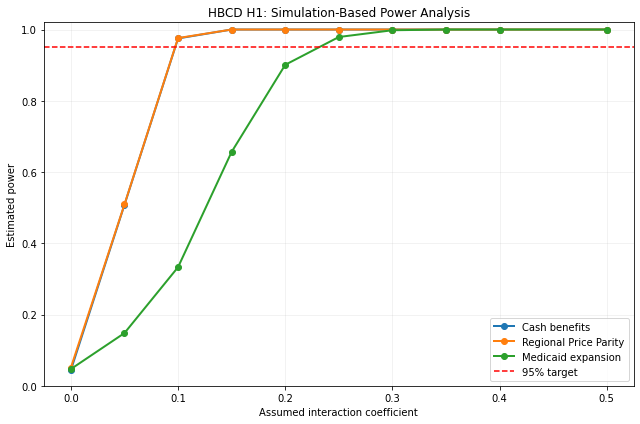


OPTIMIZER USAGE


,moderator,success_lbfgs,success_powell
0,cash_benefits,7887,2113
1,medicaid,7894,2105
2,rpp,7934,2064



BOUNDARY SOLUTION RATES


,optimizer,count,mean
0,lbfgs,23715,0.176091
1,powell,6282,0.678446



Files saved:
hbcd_h1_power_diagnostics_results.csv
hbcd_h1_individual_fit_diagnostics.csv

Total simulated datasets: 30000
Target power: 0.95
Significance threshold: 0.05

Note: Power is conditional on successful fits and does not include BH-FDR correction.


In [2]:

# ============================================================
# HBCD HYPOTHESIS 1
# SIMULATION-BASED POWER ANALYSIS WITH FIT DIAGNOSTICS
#
# 20 states | 1,500 simulated infants
# 3 moderators | 10 effect sizes | 1,000 simulations
# Total: 30,000 simulated datasets
#
# L-BFGS first, Powell fallback
# Text-based tqdm progress bar
# Separate failure categories and optimizer diagnostics
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import truncnorm
from statsmodels.regression.mixed_linear_model import MixedLM
from tqdm import tqdm

# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 2026

N_TOTAL = 1915
N_HIPPO = 1552
N_ANALYSIS = 1500

N_STATES = 20
N_SITES = 27

N_SIM = 1000
ALPHA = 0.05
TARGET_POWER = 0.95

EFFECTS = [
    0.00, 0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.35, 0.40, 0.50
]

MODERATORS = [
    "cash_benefits",
    "rpp",
    "medicaid"
]

OPTIMIZERS = ["lbfgs", "powell"]

OUTPUT_FILE = "hbcd_h1_power_diagnostics_results.csv"
FIT_LOG_FILE = "hbcd_h1_individual_fit_diagnostics.csv"

# Assumed variance components
VAR_STATE = 0.03
VAR_SITE = 0.04
VAR_FAMILY = 0.03
VAR_RESIDUAL = 0.90

# Assumed fixed-effect coefficients
BETA_INCOME = 0.10
BETA_MODERATOR = 0.05
BETA_GESTATIONAL = 0.08
BETA_SCAN_AGE = 0.10
BETA_SEX = 0.05
BETA_ICV = 0.25

# ============================================================
# 2. STATE-LEVEL MODERATORS
# ============================================================

STATE_ROWS = [
    ("Alabama", 255, 0.89, 0),
    ("Arkansas", 249, 0.87, 1),
    ("California", 778, 1.12, 1),
    ("Georgia", 287, 0.96, 0),
    ("Illinois", 465, 0.99, 1),
    ("Maryland", 584, 1.05, 1),
    ("Massachusetts", 583, 1.08, 1),
    ("Minnesota", 542, 0.98, 1),
    ("Missouri", 308, 0.91, 1),
    ("New Mexico", 458, 0.91, 1),
    ("New York", 586, 1.08, 1),
    ("North Carolina", 283, 0.94, 1),
    ("Ohio", 486, 0.92, 1),
    ("Oklahoma", 300, 0.89, 1),
    ("Oregon", 418, 1.05, 1),
    ("Pennsylvania", 349, 0.97, 1),
    ("Tennessee", 341, 0.92, 0),
    ("Vermont", 631, 0.97, 1),
    ("Virginia", 423, 1.01, 1),
    ("Wisconsin", 490, 0.93, 0)
]

state_df = pd.DataFrame(
    STATE_ROWS,
    columns=[
        "state", "cash_benefits", "rpp", "medicaid"
    ]
)

for col in ["cash_benefits", "rpp"]:
    state_df[col + "_z"] = (
        (state_df[col] - state_df[col].mean())
        / state_df[col].std(ddof=0)
    )

# ============================================================
# 3. HBCD DEMOGRAPHIC DISTRIBUTIONS
# ============================================================

RACE_LABELS = [
    "White", "Black", "Asian",
    "AIAN", "Mixed", "Other"
]

RACE_COUNTS = np.array([
    1050, 413, 59, 15, 273, 105
])

EDUCATION_COUNTS = np.array([
    382, 432, 439, 662
])

INCOME_COUNTS = np.array([
    193, 94, 56, 75, 92,
    131, 192, 194, 564, 324
])

INCOME_MIDPOINTS = np.array([
    10000, 12500, 17500, 22500, 30000,
    42500, 62500, 87500, 150000, 200000
], dtype=float)

RACE_PROBS = RACE_COUNTS / RACE_COUNTS.sum()
EDUCATION_PROBS = EDUCATION_COUNTS / EDUCATION_COUNTS.sum()
INCOME_PROBS = INCOME_COUNTS / INCOME_COUNTS.sum()

# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def standardize(x):
    x = np.asarray(x, dtype=float)
    sd = np.std(x, ddof=0)
    if sd == 0:
        return np.zeros_like(x)
    return (x - np.mean(x)) / sd


def truncated_normal(mean, sd, low, high, n, rng):
    a = (low - mean) / sd
    b = (high - mean) / sd

    return truncnorm.rvs(
        a, b,
        loc=mean,
        scale=sd,
        size=n,
        random_state=rng
    )


# ============================================================
# 5. GENERATE SIMULATED SAMPLE
# ============================================================

def generate_design(n, rng):

    state_ids = np.arange(n) % N_STATES
    rng.shuffle(state_ids)

    site_ids = np.empty(n, dtype=int)

    sites_per_state = [
        2 if s < 7 else 1
        for s in range(N_STATES)
    ]

    site_counter = 0

    for s, count in enumerate(sites_per_state):

        idx = np.where(state_ids == s)[0]

        available_sites = np.arange(
            site_counter,
            site_counter + count
        )

        site_ids[idx] = rng.choice(
            available_sites,
            size=len(idx)
        )

        site_counter += count

    family_ids = np.arange(n)

    for s in range(N_STATES):

        idx = np.where(state_ids == s)[0]
        rng.shuffle(idx)

        n_pairs = int(len(idx) * 0.05)

        for j in range(n_pairs):
            a = idx[2 * j]
            b = idx[2 * j + 1]
            family_ids[b] = family_ids[a]

    gestational_age = truncated_normal(
        38.52, 1.79, 25, 45, n, rng
    )

    scan_age = truncated_normal(
        3.05, 1.82, 0, 16, n, rng
    )

    sex_male = rng.binomial(
        1, 1005 / 1915, n
    )

    race = rng.choice(
        RACE_LABELS,
        size=n,
        p=RACE_PROBS
    )

    hispanic = rng.binomial(
        1, 389 / 1915, n
    )

    education = rng.choice(
        np.arange(4),
        size=n,
        p=EDUCATION_PROBS
    )

    income_band = rng.choice(
        np.arange(10),
        size=n,
        p=INCOME_PROBS
    )

    family_income = INCOME_MIDPOINTS[income_band]

    income_z = standardize(
        np.log(family_income)
    )

    icv_z = standardize(
        rng.normal(size=n)
    )

    manufacturer_by_site = rng.choice(
        ["GE", "Philips", "Siemens"],
        size=N_SITES,
        p=[0.25, 0.15, 0.60]
    )

    df = pd.DataFrame({
        "state_id": state_ids,
        "site_id": site_ids,
        "family_id": family_ids,
        "gestational_z": standardize(gestational_age),
        "scan_age_z": standardize(scan_age),
        "sex_male": sex_male,
        "race": race,
        "hispanic": hispanic,
        "education": education,
        "income_z": income_z,
        "icv_z": icv_z,
        "manufacturer": manufacturer_by_site[site_ids]
    })

    df["state"] = state_df.loc[
        df["state_id"], "state"
    ].to_numpy()

    df = df.merge(
        state_df[
            [
                "state",
                "cash_benefits_z",
                "rpp_z",
                "medicaid"
            ]
        ],
        on="state",
        how="left",
        validate="many_to_one"
    )

    return df


# ============================================================
# 6. SIMULATE HIPPOCAMPAL VOLUME
# ============================================================

def simulate_outcome(df, moderator, beta, rng):

    n = len(df)

    moderator_col = {
        "cash_benefits": "cash_benefits_z",
        "rpp": "rpp_z",
        "medicaid": "medicaid"
    }[moderator]

    m = df[moderator_col].to_numpy()
    x = df["income_z"].to_numpy()

    state_effects = rng.normal(
        0, np.sqrt(VAR_STATE), N_STATES
    )

    site_effects = rng.normal(
        0, np.sqrt(VAR_SITE), N_SITES
    )

    family_codes, _ = pd.factorize(
        df["family_id"]
    )

    family_effects = rng.normal(
        0,
        np.sqrt(VAR_FAMILY),
        len(np.unique(family_codes))
    )

    race_effect = {
        "White": 0.0,
        "Black": 0.02,
        "Asian": -0.02,
        "AIAN": 0.01,
        "Mixed": 0.01,
        "Other": 0.0
    }

    education_effect = np.array([
        -0.04, -0.02, 0.00, 0.02
    ])

    manufacturer_effect = {
        "GE": 0.02,
        "Philips": -0.02,
        "Siemens": 0.0
    }

    fixed = (
        BETA_INCOME * x
        + BETA_MODERATOR * m
        + beta * x * m
        + BETA_GESTATIONAL * df["gestational_z"].to_numpy()
        + BETA_SCAN_AGE * df["scan_age_z"].to_numpy()
        + BETA_SEX * df["sex_male"].to_numpy()
        + BETA_ICV * df["icv_z"].to_numpy()
        + df["race"].map(race_effect).to_numpy()
        + education_effect[df["education"].to_numpy()]
        + 0.02 * df["hispanic"].to_numpy()
        + df["manufacturer"].map(
            manufacturer_effect
        ).to_numpy()
    )

    random_part = (
        state_effects[df["state_id"].to_numpy()]
        + site_effects[df["site_id"].to_numpy()]
        + family_effects[family_codes]
        + rng.normal(
            0, np.sqrt(VAR_RESIDUAL), n
        )
    )

    return 1220 + 187 * (fixed + random_part)


# ============================================================
# 7. FIT MODEL WITH OPTIMIZER FALLBACK
# ============================================================

def fit_interaction(df, moderator):

    moderator_col = {
        "cash_benefits": "cash_benefits_z",
        "rpp": "rpp_z",
        "medicaid": "medicaid"
    }[moderator]

    data = df.copy()

    data["moderator_value"] = data[moderator_col]

    data["interaction"] = (
        data["income_z"] * data["moderator_value"]
    )

    data["hippo_z"] = (
        data["hippocampal_volume"] - 1220
    ) / 187

    formula = (
        "hippo_z ~ income_z + moderator_value "
        "+ interaction + gestational_z + scan_age_z "
        "+ sex_male + icv_z + hispanic "
        "+ C(race) + C(education) + C(manufacturer)"
    )

    attempts = []

    try:
        model = MixedLM.from_formula(
            formula,
            data=data,
            groups="state_id",
            re_formula="1",
            vc_formula={
                "site": "0 + C(site_id)",
                "family": "0 + C(family_id)"
            }
        )

    except Exception as e:
        return {
            "status": "exception",
            "optimizer": "none",
            "pvalue": np.nan,
            "attempts": [],
            "error": type(e).__name__ + ": " + str(e)
        }

    for optimizer in OPTIMIZERS:

        start = time.perf_counter()

        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")

                fit = model.fit(
                    reml=False,
                    method=optimizer,
                    maxiter=500,
                    disp=False
                )

            elapsed = time.perf_counter() - start

            warning_messages = " | ".join(
                str(w.message) for w in caught
            )

            if not fit.converged:

                attempts.append({
                    "optimizer": optimizer,
                    "status": "nonconvergence",
                    "seconds": elapsed,
                    "warnings": warning_messages
                })

                continue

            p = float(fit.pvalues["interaction"])

            if not np.isfinite(p):

                attempts.append({
                    "optimizer": optimizer,
                    "status": "invalid_pvalue",
                    "seconds": elapsed,
                    "warnings": warning_messages
                })

                continue

            # Variance components
            variance_lookup = dict(
                zip(model.exog_vc.names, fit.vcomp)
            )

            state_var = float(
                fit.cov_re.iloc[0, 0]
            )

            site_var = float(
                variance_lookup.get("site", np.nan)
            )

            family_var = float(
                variance_lookup.get("family", np.nan)
            )

            residual_var = float(fit.scale)

            variances = np.array([
                state_var,
                site_var,
                family_var
            ])

            boundary = bool(
                np.any(
                    variances
                    < 1e-4 * residual_var
                )
            )

            attempts.append({
                "optimizer": optimizer,
                "status": "success",
                "seconds": elapsed,
                "warnings": warning_messages
            })

            return {
                "status": "success",
                "optimizer": optimizer,
                "pvalue": p,
                "beta_estimate": float(
                    fit.params["interaction"]
                ),
                "se_estimate": float(
                    fit.bse["interaction"]
                ),
                "log_likelihood": float(fit.llf),
                "state_variance": state_var,
                "site_variance": site_var,
                "family_variance": family_var,
                "residual_variance": residual_var,
                "boundary_component": boundary,
                "attempts": attempts,
                "error": ""
            }

        except Exception as e:

            elapsed = time.perf_counter() - start

            attempts.append({
                "optimizer": optimizer,
                "status": "exception",
                "seconds": elapsed,
                "warnings": "",
                "error": type(e).__name__ + ": " + str(e)
            })

    # If all optimizers fail, classify by final attempt.
    final_status = (
        attempts[-1]["status"]
        if attempts else "exception"
    )

    return {
        "status": final_status,
        "optimizer": "none",
        "pvalue": np.nan,
        "attempts": attempts,
        "error": (
            attempts[-1].get("error", "")
            if attempts else ""
        )
    }


# ============================================================
# 8. RUN MONTE CARLO SIMULATIONS
# ============================================================

def run_power_analysis():

    rng = np.random.default_rng(SEED)

    total = len(MODERATORS) * len(EFFECTS) * N_SIM

    summary_records = []
    fit_records = []

    with tqdm(
        total=total,
        desc="HBCD H1 simulations",
        unit="fit",
        ncols=100,
        mininterval=1
    ) as progress:

        for moderator in MODERATORS:

            for beta in EFFECTS:

                pvalues = []

                counts = {
                    "success_lbfgs": 0,
                    "success_powell": 0,
                    "nonconvergence": 0,
                    "invalid_pvalue": 0,
                    "exception": 0
                }

                for sim in range(N_SIM):

                    local_rng = np.random.default_rng(
                        rng.integers(0, 2**32 - 1)
                    )

                    try:

                        df = generate_design(
                            N_ANALYSIS,
                            local_rng
                        )

                        df["hippocampal_volume"] = (
                            simulate_outcome(
                                df,
                                moderator,
                                beta,
                                local_rng
                            )
                        )

                        result = fit_interaction(
                            df, moderator
                        )

                    except Exception as e:

                        result = {
                            "status": "exception",
                            "optimizer": "none",
                            "pvalue": np.nan,
                            "attempts": [],
                            "error": (
                                type(e).__name__
                                + ": " + str(e)
                            )
                        }

                    status = result["status"]

                    if status == "success":

                        pvalues.append(result["pvalue"])

                        counts[
                            "success_" + result["optimizer"]
                        ] += 1

                    else:
                        counts[status] += 1

                    # Record each optimizer attempt separately.
                    for attempt_number, attempt in enumerate(
                        result.get("attempts", []), start=1
                    ):

                        fit_records.append({
                            "moderator": moderator,
                            "interaction_beta": beta,
                            "simulation": sim + 1,
                            "attempt_number": attempt_number,
                            "optimizer": attempt["optimizer"],
                            "attempt_status": attempt["status"],
                            "seconds": attempt["seconds"],
                            "warnings": attempt.get(
                                "warnings", ""
                            ),
                            "error": attempt.get(
                                "error", ""
                            )
                        })

                    # Record final fit outcome separately.
                    fit_records.append({
                        "moderator": moderator,
                        "interaction_beta": beta,
                        "simulation": sim + 1,
                        "attempt_number": 0,
                        "optimizer": result["optimizer"],
                        "attempt_status": (
                            "final_" + status
                        ),
                        "seconds": np.nan,
                        "warnings": "",
                        "error": result.get("error", ""),
                        "pvalue": result.get(
                            "pvalue", np.nan
                        ),
                        "beta_estimate": result.get(
                            "beta_estimate", np.nan
                        ),
                        "se_estimate": result.get(
                            "se_estimate", np.nan
                        ),
                        "log_likelihood": result.get(
                            "log_likelihood", np.nan
                        ),
                        "state_variance": result.get(
                            "state_variance", np.nan
                        ),
                        "site_variance": result.get(
                            "site_variance", np.nan
                        ),
                        "family_variance": result.get(
                            "family_variance", np.nan
                        ),
                        "residual_variance": result.get(
                            "residual_variance", np.nan
                        ),
                        "boundary_component": result.get(
                            "boundary_component", np.nan
                        )
                    })

                    progress.update(1)

                n_valid = len(pvalues)
                n_failed = N_SIM - n_valid

                if n_valid > 0:

                    power = np.mean(
                        np.asarray(pvalues) < ALPHA
                    )

                    mc_se = np.sqrt(
                        power * (1 - power) / n_valid
                    )

                else:
                    power = np.nan
                    mc_se = np.nan

                summary_records.append({
                    "moderator": moderator,
                    "interaction_beta": beta,
                    "n_analysis": N_ANALYSIS,
                    "n_sim": N_SIM,
                    "n_valid": n_valid,
                    "n_failed": n_failed,
                    "convergence_rate": n_valid / N_SIM,
                    "power_unadjusted": power,
                    "mc_se": mc_se,
                    **counts
                })

                # Save completed scenarios.
                pd.DataFrame(summary_records).to_csv(
                    OUTPUT_FILE,
                    index=False
                )

                pd.DataFrame(fit_records).to_csv(
                    FIT_LOG_FILE,
                    index=False
                )

                progress.set_postfix({
                    "mod": moderator,
                    "beta": beta,
                    "valid": n_valid,
                    "power": (
                        round(power, 3)
                        if np.isfinite(power)
                        else "NA"
                    )
                })

    return (
        pd.DataFrame(summary_records),
        pd.DataFrame(fit_records)
    )


# ============================================================
# 9. EXECUTE
# ============================================================

results, fit_diagnostics = run_power_analysis()

print("\nSIMULATION COMPLETE")

display(results)

# ============================================================
# 10. CONVERGENCE SUMMARY
# ============================================================

convergence_summary = (
    results.groupby("moderator")
    .agg(
        mean_convergence=("convergence_rate", "mean"),
        total_valid=("n_valid", "sum"),
        total_failed=("n_failed", "sum"),
        lbfgs_success=("success_lbfgs", "sum"),
        powell_success=("success_powell", "sum"),
        nonconvergence=("nonconvergence", "sum"),
        invalid_pvalue=("invalid_pvalue", "sum"),
        exception=("exception", "sum")
    )
    .reset_index()
)

print("\nCONVERGENCE SUMMARY")
display(convergence_summary.round(4))

# ============================================================
# 11. TYPE I ERROR CALIBRATION
# ============================================================

type1_error = results[
    results["interaction_beta"] == 0
][[
    "moderator",
    "power_unadjusted",
    "mc_se",
    "convergence_rate",
    "n_failed"
]].copy()

type1_error = type1_error.rename(
    columns={
        "power_unadjusted": "type1_error_rate"
    }
)

print("\nTYPE I ERROR CALIBRATION")
display(type1_error.round(4))

# ============================================================
# 12. MINIMUM TESTED EFFECT FOR 95% POWER
# ============================================================

minimum_effects = []

for moderator in MODERATORS:

    sub = results[
        (results["moderator"] == moderator)
        & (results["interaction_beta"] > 0)
        & (results["power_unadjusted"] >= TARGET_POWER)
    ].sort_values("interaction_beta")

    if len(sub):

        first = sub.iloc[0]

        minimum_effects.append({
            "moderator": moderator,
            "minimum_tested_beta": first["interaction_beta"],
            "estimated_power": first["power_unadjusted"],
            "convergence_rate": first["convergence_rate"]
        })

    else:

        minimum_effects.append({
            "moderator": moderator,
            "minimum_tested_beta": np.nan,
            "estimated_power": np.nan,
            "convergence_rate": np.nan
        })

print("\nMINIMUM TESTED EFFECT REACHING 95% POWER")
display(pd.DataFrame(minimum_effects))

# ============================================================
# 13. POWER CURVES
# ============================================================

plt.figure(figsize=(9, 6))

labels = {
    "cash_benefits": "Cash benefits",
    "rpp": "Regional Price Parity",
    "medicaid": "Medicaid expansion"
}

for moderator in MODERATORS:

    sub = results[
        results["moderator"] == moderator
    ].sort_values("interaction_beta")

    plt.plot(
        sub["interaction_beta"],
        sub["power_unadjusted"],
        marker="o",
        linewidth=2,
        label=labels[moderator]
    )

plt.axhline(
    TARGET_POWER,
    linestyle="--",
    color="red",
    label="95% target"
)

plt.xlabel("Assumed interaction coefficient")
plt.ylabel("Estimated power")
plt.title("HBCD H1: Simulation-Based Power Analysis")
plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ============================================================
# 14. OPTIMIZER USAGE
# ============================================================

optimizer_usage = (
    results.groupby("moderator")[
        ["success_lbfgs", "success_powell"]
    ]
    .sum()
    .reset_index()
)

print("\nOPTIMIZER USAGE")
display(optimizer_usage)

# ============================================================
# 15. BOUNDARY SOLUTIONS
# ============================================================

final_fits = fit_diagnostics[
    fit_diagnostics["attempt_status"] == "final_success"
].copy()

print("\nBOUNDARY SOLUTION RATES")

if len(final_fits):

    boundary_summary = (
        final_fits.groupby("optimizer")
        ["boundary_component"]
        .agg(["count", "mean"])
        .reset_index()
    )

    display(boundary_summary)

# ============================================================
# 16. FINAL OUTPUT
# ============================================================

print("\nFiles saved:")
print(OUTPUT_FILE)
print(FIT_LOG_FILE)

print("\nTotal simulated datasets:", len(MODERATORS) * len(EFFECTS) * N_SIM)
print("Target power:", TARGET_POWER)
print("Significance threshold:", ALPHA)

print(
    "\nNote: Power is conditional on successful fits "
    "and does not include BH-FDR correction."
)


In [3]:

import numpy as np
import pandas as pd

# Load individual model results
df = pd.read_csv(
    "hbcd_h1_individual_fit_diagnostics.csv"
)

# Keep only final successful fits
df = df[
    df["attempt_status"] == "final_success"
].copy()

# Three moderator tests in Hypothesis 1
alpha = 0.05
n_tests = 3
bonferroni_alpha = alpha / n_tests

# Rejection indicators
df["significant_unadjusted"] = (
    df["pvalue"] < alpha
)

df["significant_bonferroni"] = (
    df["pvalue"] < bonferroni_alpha
)

# Summarize empirical power
power_comparison = (
    df.groupby(
        ["moderator", "interaction_beta"]
    )
    .agg(
        n_valid=("pvalue", "count"),
        power_unadjusted=(
            "significant_unadjusted", "mean"
        ),
        power_bonferroni=(
            "significant_bonferroni", "mean"
        )
    )
    .reset_index()
)

power_comparison.to_csv(
    "hbcd_h1_power_bonferroni_comparison.csv",
    index=False
)

display(power_comparison.round(4))

# Find smallest tested effect reaching 95% power
minimum_effects = []

for moderator, group in power_comparison.groupby(
    "moderator"
):
    eligible = group[
        (group["interaction_beta"] > 0)
        & (group["power_bonferroni"] >= 0.95)
    ].sort_values("interaction_beta")

    if not eligible.empty:
        first = eligible.iloc[0]
        minimum_effects.append({
            "moderator": moderator,
            "minimum_tested_beta": first["interaction_beta"],
            "power_bonferroni": first["power_bonferroni"]
        })
    else:
        minimum_effects.append({
            "moderator": moderator,
            "minimum_tested_beta": np.nan,
            "power_bonferroni": np.nan
        })

print("Minimum tested effects with >=95% power:")
display(pd.DataFrame(minimum_effects))


,moderator,interaction_beta,n_valid,power_unadjusted,power_bonferroni
0,cash_benefits,0.00,1000,0.0440,0.0170
1,cash_benefits,0.05,1000,0.5080,0.3240
2,cash_benefits,0.10,1000,0.9750,0.9490
3,cash_benefits,0.15,1000,1.0000,0.9990
4,cash_benefits,0.20,1000,1.0000,1.0000
5,cash_benefits,0.25,1000,1.0000,1.0000
6,cash_benefits,0.30,1000,1.0000,1.0000
7,cash_benefits,0.35,1000,1.0000,1.0000
8,cash_benefits,0.40,1000,1.0000,1.0000
9,cash_benefits,0.50,1000,1.0000,1.0000


Minimum tested effects with >=95% power:


,moderator,minimum_tested_beta,power_bonferroni
0,cash_benefits,0.15,0.999
1,medicaid,0.30,0.994
2,rpp,0.15,1.000


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


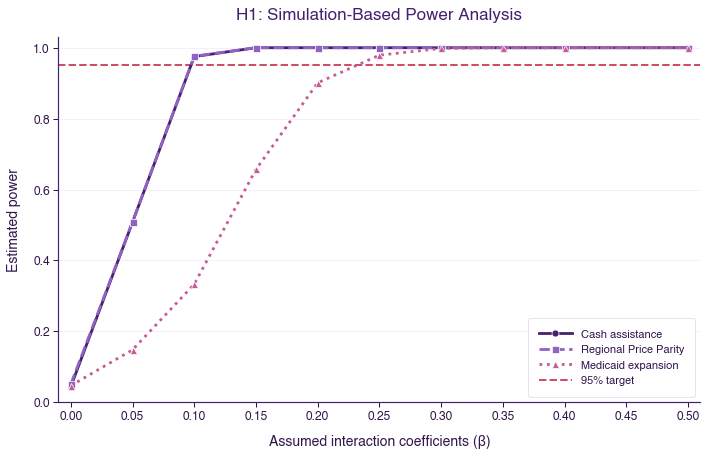

In [5]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# --------------------------------------------------
# Figure settings
# --------------------------------------------------

plt.rcParams.update({
    "font.family": "Helvetica",
    "font.size": 12,
    "axes.titlesize": 17,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

# Purple color palette
dark_purple = "#45216F"
medium_purple = "#9063C2"
pink_purple = "#C65B96"
light_purple = "#EAE1F3"
text_purple = "#32174D"
target_color = "#D14C65"

styles = {
    "cash_benefits": {
        "label": "Cash assistance",
        "color": dark_purple,
        "linestyle": "-",
        "marker": "o"
    },
    "rpp": {
        "label": "Regional Price Parity",
        "color": medium_purple,
        "linestyle": "--",
        "marker": "s"
    },
    "medicaid": {
        "label": "Medicaid expansion",
        "color": pink_purple,
        "linestyle": ":",
        "marker": "^"
    }
}

# --------------------------------------------------
# Create figure
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

for moderator, style in styles.items():

    subset = results[
        results["moderator"] == moderator
    ].sort_values("interaction_beta")

    ax.plot(
        subset["interaction_beta"],
        subset["power_unadjusted"],
        label=style["label"],
        color=style["color"],
        linestyle=style["linestyle"],
        marker=style["marker"],
        linewidth=2.8,
        markersize=7,
        markeredgecolor="white",
        markeredgewidth=0.7,
        zorder=3
    )

# 95% power target
ax.axhline(
    y=0.95,
    color=target_color,
    linestyle="--",
    linewidth=2,
    label="95% target",
    zorder=2
)

# --------------------------------------------------
# Labels and formatting
# --------------------------------------------------

ax.set_title(
    "H1: Simulation-Based Power Analysis",
    fontweight="bold",
    color=dark_purple,
    pad=18
)

ax.set_xlabel(
    "Assumed interaction coefficients (β)",
    fontweight="bold",
    color=text_purple,
    labelpad=12
)

ax.set_ylabel(
    "Estimated power",
    fontweight="bold",
    color=text_purple,
    labelpad=12
)

ax.set_xlim(-0.01, 0.51)
ax.set_ylim(0, 1.03)

ax.xaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_locator(MultipleLocator(0.2))

ax.tick_params(
    axis="both",
    colors=text_purple,
    length=5,
    width=1
)

# Subtle horizontal gridlines
ax.grid(
    axis="y",
    color=light_purple,
    linewidth=0.8,
    alpha=0.65
)

ax.grid(axis="x", visible=False)

# Remove upper and right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for side in ["left", "bottom"]:
    ax.spines[side].set_color(dark_purple)
    ax.spines[side].set_linewidth(1.2)

# --------------------------------------------------
# Legend
# --------------------------------------------------

legend = ax.legend(
    loc="lower right",
    frameon=True,
    fancybox=True,
    facecolor="white",
    edgecolor=light_purple,
    framealpha=0.97,
    borderpad=1,
    handlelength=3
)

for text in legend.get_texts():
    text.set_color(text_purple)

# --------------------------------------------------
# Export
# --------------------------------------------------

plt.tight_layout()

plt.savefig(
    "HBCD_H1_Power_Analysis_Purple.png",
    dpi=1000,
    bbox_inches="tight"
)

plt.savefig(
    "HBCD_H1_Power_Analysis_Purple.pdf",
    bbox_inches="tight"
)

plt.show()


Parallel scenario batches:   0%|          | 0/30 [00:00<?, ?it/s]

HYPOTHESIS 2 POWER ANALYSIS
Number of scenarios: 120
Total planned simulations: 120000
Parallel workers: 4
GM sample size: 1500
WM sample size: 1235

Completed scenarios: 0
Pending scenarios: 120
Simulations per scenario: 1000



Parallel scenario batches:   3%|3         | 1/30 [19:50<9:35:13, 1190.13s/it]

Completed 4/120 scenarios | 4,000/120,000 simulations


Parallel scenario batches:   7%|6         | 2/30 [39:10<9:11:12, 1181.18s/it]

Completed 8/120 scenarios | 8,000/120,000 simulations


Parallel scenario batches:  10%|#         | 3/30 [1:00:19<9:03:24, 1207.56s/it]

Completed 12/120 scenarios | 12,000/120,000 simulations


Parallel scenario batches:  13%|#3        | 4/30 [1:23:30<9:07:05, 1262.51s/it]

Completed 16/120 scenarios | 16,000/120,000 simulations


Parallel scenario batches:  17%|#6        | 5/30 [1:48:38<9:16:48, 1336.32s/it]

Completed 20/120 scenarios | 20,000/120,000 simulations


Parallel scenario batches:  20%|##        | 6/30 [2:09:05<8:41:19, 1303.32s/it]

Completed 24/120 scenarios | 24,000/120,000 simulations


Parallel scenario batches:  23%|##3       | 7/30 [2:28:58<8:06:56, 1270.29s/it]

Completed 28/120 scenarios | 28,000/120,000 simulations


Parallel scenario batches:  27%|##6       | 8/30 [2:48:17<7:33:34, 1237.01s/it]

Completed 32/120 scenarios | 32,000/120,000 simulations


Parallel scenario batches:  30%|###       | 9/30 [3:07:51<7:06:16, 1217.91s/it]

Completed 36/120 scenarios | 36,000/120,000 simulations


Parallel scenario batches:  33%|###3      | 10/30 [3:27:23<6:41:26, 1204.34s/it]

Completed 40/120 scenarios | 40,000/120,000 simulations


Parallel scenario batches:  37%|###6      | 11/30 [3:47:13<6:19:59, 1199.99s/it]

Completed 44/120 scenarios | 44,000/120,000 simulations


Parallel scenario batches:  40%|####      | 12/30 [4:06:54<5:58:15, 1194.19s/it]

Completed 48/120 scenarios | 48,000/120,000 simulations


Parallel scenario batches:  43%|####3     | 13/30 [4:26:42<5:37:51, 1192.44s/it]

Completed 52/120 scenarios | 52,000/120,000 simulations


Parallel scenario batches:  47%|####6     | 14/30 [4:46:35<5:18:00, 1192.53s/it]

Completed 56/120 scenarios | 56,000/120,000 simulations


Parallel scenario batches:  50%|#####     | 15/30 [5:06:24<4:57:51, 1191.43s/it]

Completed 60/120 scenarios | 60,000/120,000 simulations


Parallel scenario batches:  53%|#####3    | 16/30 [5:22:31<4:22:18, 1124.20s/it]

Completed 64/120 scenarios | 64,000/120,000 simulations


Parallel scenario batches:  57%|#####6    | 17/30 [5:38:57<3:54:35, 1082.74s/it]

Completed 68/120 scenarios | 68,000/120,000 simulations


Parallel scenario batches:  60%|######    | 18/30 [5:55:04<3:29:36, 1048.06s/it]

Completed 72/120 scenarios | 72,000/120,000 simulations


Parallel scenario batches:  63%|######3   | 19/30 [6:10:42<3:06:04, 1014.96s/it]

Completed 76/120 scenarios | 76,000/120,000 simulations


Parallel scenario batches:  67%|######6   | 20/30 [6:26:47<2:46:41, 1000.12s/it]

Completed 80/120 scenarios | 80,000/120,000 simulations


Parallel scenario batches:  70%|#######   | 21/30 [6:43:22<2:29:45, 998.35s/it] 

Completed 84/120 scenarios | 84,000/120,000 simulations


Parallel scenario batches:  73%|#######3  | 22/30 [6:59:24<2:11:40, 987.54s/it]

Completed 88/120 scenarios | 88,000/120,000 simulations


Parallel scenario batches:  77%|#######6  | 23/30 [7:15:45<1:54:59, 985.70s/it]

Completed 92/120 scenarios | 92,000/120,000 simulations


Parallel scenario batches:  80%|########  | 24/30 [7:31:39<1:37:36, 976.12s/it]

Completed 96/120 scenarios | 96,000/120,000 simulations


Parallel scenario batches:  83%|########3 | 25/30 [7:47:36<1:20:52, 970.46s/it]

Completed 100/120 scenarios | 100,000/120,000 simulations


Parallel scenario batches:  87%|########6 | 26/30 [8:03:52<1:04:48, 972.02s/it]

Completed 104/120 scenarios | 104,000/120,000 simulations


Parallel scenario batches:  90%|######### | 27/30 [8:20:19<48:49, 976.38s/it]  

Completed 108/120 scenarios | 108,000/120,000 simulations


Parallel scenario batches:  93%|#########3| 28/30 [8:36:23<32:25, 972.72s/it]

Completed 112/120 scenarios | 112,000/120,000 simulations


Parallel scenario batches:  97%|#########6| 29/30 [8:52:53<16:17, 977.98s/it]

Completed 116/120 scenarios | 116,000/120,000 simulations


Parallel scenario batches: 100%|##########| 30/30 [9:08:28<00:00, 1096.94s/it]

Completed 120/120 scenarios | 120,000/120,000 simulations

PARALLEL SIMULATION COMPLETED

Total scenarios: 120
Total valid fits: 119981
Total failed fits: 19
L-BFGS fits: 99973
Powell fits: 20008


,outcome_type,predictor,moderator,beta,power,valid_fits,failed_fits,lbfgs_fits,powell_fits,n_simulations
0,GM,Income-to-needs ratio,PC1,0.00,0.047,1000,0,865,135,1000
1,GM,Income-to-needs ratio,PC1,0.05,0.518,1000,0,847,153,1000
2,GM,Income-to-needs ratio,PC1,0.10,0.974,1000,0,843,157,1000
3,GM,Income-to-needs ratio,PC1,0.15,1.000,1000,0,840,160,1000
4,GM,Income-to-needs ratio,PC1,0.20,1.000,1000,0,856,144,1000
5,GM,Income-to-needs ratio,PC1,0.25,1.000,1000,0,846,154,1000
6,GM,Income-to-needs ratio,PC1,0.30,1.000,1000,0,837,163,1000
7,GM,Income-to-needs ratio,PC1,0.35,1.000,1000,0,856,144,1000
8,GM,Income-to-needs ratio,PC1,0.40,1.000,1000,0,826,174,1000
9,GM,Income-to-needs ratio,PC1,0.50,1.000,1000,0,843,157,1000



EMPIRICAL TYPE I ERROR (beta = 0)


,outcome_type,predictor,moderator,type_I_error,valid_fits,failed_fits
0,GM,Income-to-needs ratio,PC1,0.047,1000,0
10,GM,Income-to-needs ratio,PC2,0.058,1000,0
20,GM,Maternal depression,PC1,0.053,1000,0
30,GM,Maternal depression,PC2,0.046,1000,0
40,GM,Maternal substance use,PC1,0.054,1000,0
50,GM,Maternal substance use,PC2,0.053,1000,0
60,WM,Income-to-needs ratio,PC1,0.059,1000,0
70,WM,Income-to-needs ratio,PC2,0.053,1000,0
80,WM,Maternal depression,PC1,0.047,1000,0
90,WM,Maternal depression,PC2,0.039,1000,0



MINIMUM TESTED BETA AT 95% POWER


,outcome_type,predictor,moderator,minimum_tested_beta_95_power
0,GM,Income-to-needs ratio,PC1,0.10
1,GM,Income-to-needs ratio,PC2,0.10
2,GM,Maternal depression,PC1,0.10
3,GM,Maternal depression,PC2,0.10
4,GM,Maternal substance use,PC1,0.10
5,GM,Maternal substance use,PC2,0.10
6,WM,Income-to-needs ratio,PC1,0.15
7,WM,Income-to-needs ratio,PC2,0.15
8,WM,Maternal depression,PC1,0.10
9,WM,Maternal depression,PC2,0.15


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


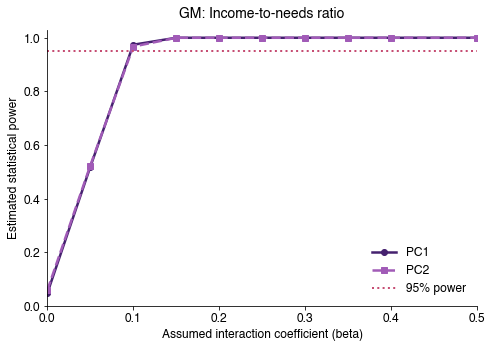

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


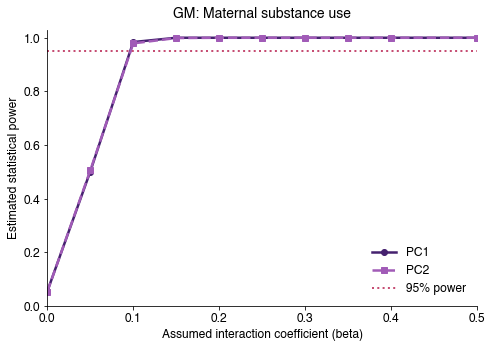

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


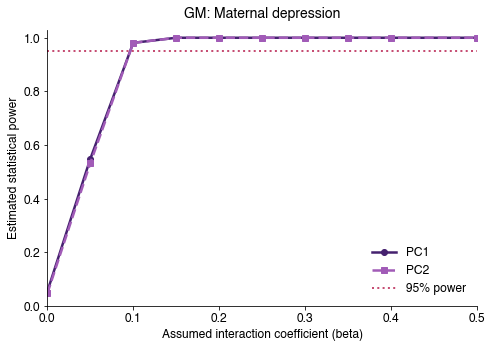

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


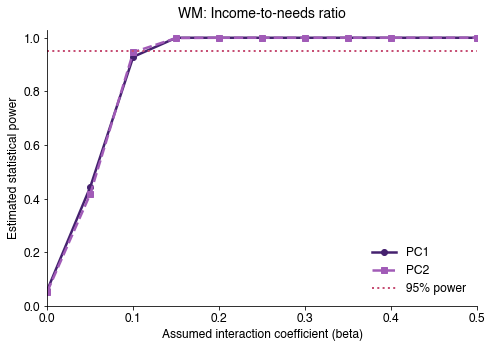

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


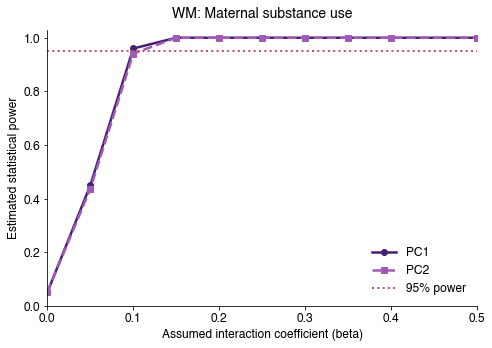

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


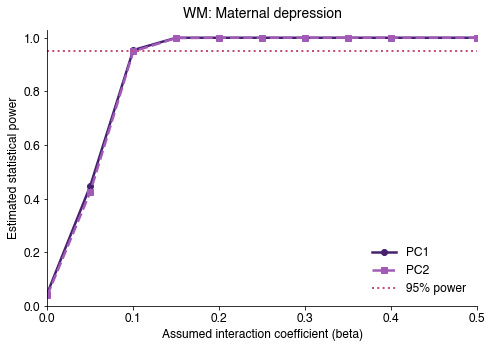


All results saved to:
/Users/jivesh/Downloads/HBCD_H2_parallel_power_1000sim


In [4]:

# ============================================================
# HYPOTHESIS 2: PARALLEL SIMULATION-BASED POWER ANALYSIS
# HBCD Study Release 2.1
# ============================================================

# If needed, install:
# %pip install numpy pandas scipy statsmodels joblib tqdm
# %pip install threadpoolctl matplotlib

import os

# Set thread limits before importing numerical libraries.
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from scipy.stats import truncnorm
from statsmodels.regression.mixed_linear_model import MixedLM
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

# Use text-based tqdm rather than tqdm.auto
from tqdm import tqdm

# ============================================================
# 1. SIMULATION SETTINGS
# ============================================================

N_GM = 1500
N_WM = 1235

N_STATES = 20
N_SITES = 27

# Final analysis: 1000
# Short test: change to 10
N_SIMULATIONS = 1000

EFFECT_SIZES = [
    0.00, 0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.35, 0.40, 0.50
]

ALPHA = 0.05
TARGET_POWER = 0.95
SEED = 12345

N_JOBS = min(4, os.cpu_count() or 1)

# Variance components on standardized outcome scale
VAR_STATE = 0.03
VAR_SITE = 0.04
VAR_FAMILY = 0.03
VAR_RESIDUAL = 0.90

# Assumed fixed effects
BETA_PREDICTOR = 0.10
BETA_PC = 0.05

BETA_GESTATIONAL_AGE = 0.08
BETA_SCAN_AGE = 0.10
BETA_SEX = 0.05
BETA_EDUCATION = 0.05
BETA_ICV = 0.25

# Hypothesis 1 GM assumptions
GM_MEAN = 1220
GM_SD = 187

# Use a distinct directory for each simulation setting.
OUTPUT_DIR = (
    f"HBCD_H2_parallel_power_{N_SIMULATIONS}sim"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SUMMARY_FILE = os.path.join(
    OUTPUT_DIR, "power_summary.csv"
)

DETAIL_FILE = os.path.join(
    OUTPUT_DIR, "fit_diagnostics.csv"
)

MDE_FILE = os.path.join(
    OUTPUT_DIR, "minimum_detectable_effects.csv"
)

# ============================================================
# 2. ACTUAL STANDARDIZED STATE PC SCORES
# ============================================================

state_data = [
    ("Alabama", 1.551, 0.014),
    ("Arkansas", 1.534, 0.203),
    ("California", -1.175, 1.699),
    ("Georgia", 1.112, 0.445),
    ("Illinois", -0.920, 0.857),
    ("Maryland", -0.970, -1.105),
    ("Massachusetts", -1.238, 0.446),
    ("Minnesota", -0.908, -1.586),
    ("Missouri", 0.624, -0.637),
    ("New Mexico", -0.314, 0.958),
    ("New York", -1.134, 2.054),
    ("North Carolina", 0.672, 0.066),
    ("Ohio", 0.331, -0.033),
    ("Oklahoma", 1.319, 0.149),
    ("Oregon", -1.114, -0.218),
    ("Pennsylvania", 0.339, 0.278),
    ("Tennessee", 1.226, 0.416),
    ("Vermont", -1.199, -1.986),
    ("Virginia", -0.064, -0.591),
    ("Wisconsin", 0.329, -1.429)
]

states_df = pd.DataFrame(
    state_data,
    columns=["state", "PC1", "PC2"]
)

assert len(states_df) == N_STATES

# ============================================================
# 3. DEFINE SIMULATION SCENARIOS
# ============================================================

PREDICTORS = [
    "Income-to-needs ratio",
    "Maternal substance use",
    "Maternal depression"
]

MODERATORS = ["PC1", "PC2"]
OUTCOME_TYPES = ["GM", "WM"]

SCENARIOS = [
    (outcome_type, predictor, moderator, beta)
    for outcome_type in OUTCOME_TYPES
    for predictor in PREDICTORS
    for moderator in MODERATORS
    for beta in EFFECT_SIZES
]

print("=" * 60)
print("HYPOTHESIS 2 POWER ANALYSIS")
print("=" * 60)
print("Number of scenarios:", len(SCENARIOS))
print(
    "Total planned simulations:",
    len(SCENARIOS) * N_SIMULATIONS
)
print("Parallel workers:", N_JOBS)
print("GM sample size:", N_GM)
print("WM sample size:", N_WM)
print("=" * 60)

# ============================================================
# 4. STANDARDIZATION
# ============================================================

def standardize(x):

    x = np.asarray(x, dtype=float)

    sd = np.std(x, ddof=0)

    if not np.isfinite(sd) or sd <= 0:
        raise ValueError("Cannot standardize variable")

    return (x - np.mean(x)) / sd


# ============================================================
# 5. SIMULATE FAMILY CHARACTERISTICS
# ============================================================

def simulate_predictor(n, predictor, rng):

    if predictor == "Income-to-needs ratio":

        # Right-skewed distribution, as in H1.
        # This is an assumed proxy, not empirical HBCD data.
        x = rng.lognormal(
            mean=0,
            sigma=0.75,
            size=n
        )

    elif predictor == "Maternal substance use":

        # Empirical summary:
        # Mean = 4.00
        # SD = 2.88
        # Range = 0 to 18

        mean = 4.00
        variance = 2.88 ** 2

        r = mean ** 2 / (variance - mean)
        p = r / (r + mean)

        x = rng.negative_binomial(
            n=r,
            p=p,
            size=n
        )

        x = np.clip(x, 0, 18)

    elif predictor == "Maternal depression":

        # Empirical summary:
        # Mean = 46.33
        # SD = 8.12
        # Observed range = 38.20 to 81.30
        #
        # Truncated normal approximation.

        mean = 46.33
        sd = 8.12

        lower = (38.20 - mean) / sd
        upper = (81.30 - mean) / sd

        x = truncnorm.rvs(
            lower,
            upper,
            loc=mean,
            scale=sd,
            size=n,
            random_state=rng
        )

    else:
        raise ValueError(
            f"Unknown predictor: {predictor}"
        )

    return standardize(x)


# ============================================================
# 6. SIMULATE MULTILEVEL STRUCTURE
# ============================================================

def simulate_structure(n, rng):

    # Approximately balanced recruitment across states.
    state_idx = np.tile(
        np.arange(N_STATES),
        int(np.ceil(n / N_STATES))
    )[:n]

    rng.shuffle(state_idx)

    # 27 sites distributed across 20 states.
    # This allocation is assumed rather than empirical.
    site_counts = np.array(
        [2] * 7 + [1] * 13
    )

    site_starts = np.cumsum(
        np.r_[0, site_counts[:-1]]
    )

    site_idx = np.empty(n, dtype=int)

    for s in range(N_STATES):

        members = np.where(
            state_idx == s
        )[0]

        site_idx[members] = (
            site_starts[s]
            + rng.integers(
                0,
                site_counts[s],
                size=len(members)
            )
        )

    # Approximately 5% of participants belong
    # to sibling pairs.
    family_idx = np.arange(n)

    n_pairs = int(round(0.05 * n / 2))

    available = {
        s: list(np.where(state_idx == s)[0])
        for s in range(N_STATES)
    }

    for s in available:
        rng.shuffle(available[s])

    for _ in range(n_pairs):

        eligible_states = [
            s for s in range(N_STATES)
            if len(available[s]) >= 2
        ]

        if not eligible_states:
            break

        s = rng.choice(eligible_states)

        a = available[s].pop()
        b = available[s].pop()

        family_idx[b] = family_idx[a]

    df = pd.DataFrame({
        "state_idx": state_idx,
        "site_idx": site_idx,
        "family_idx": family_idx
    })

    # Attach actual state PC scores.
    df["PC1"] = (
        states_df["PC1"].to_numpy()[state_idx]
    )

    df["PC2"] = (
        states_df["PC2"].to_numpy()[state_idx]
    )

    # Simulated covariates
    df["gestational_age"] = standardize(
        rng.normal(39, 1.5, n)
    )

    df["scan_age"] = standardize(
        rng.uniform(0, 12, n)
    )

    df["sex"] = rng.binomial(
        1, 0.5, size=n
    )

    df["maternal_education"] = standardize(
        rng.normal(15, 2.5, n)
    )

    df["ICV"] = standardize(
        rng.normal(0, 1, n)
    )

    # Assumed manufacturer distribution.
    df["scanner_manufacturer"] = rng.choice(
        ["GE", "Siemens", "Philips"],
        size=n,
        p=[0.25, 0.60, 0.15]
    )

    # Placeholder race/ethnicity categories.
    df["race_ethnicity"] = rng.choice(
        ["Group1", "Group2", "Group3", "Group4"],
        size=n,
        p=[0.45, 0.25, 0.20, 0.10]
    )

    return df


# ============================================================
# 7. GENERATE OUTCOME
# ============================================================

def generate_outcome(
    df,
    predictor,
    moderator,
    beta_interaction,
    outcome_type,
    rng
):

    n = len(df)

    x = simulate_predictor(
        n, predictor, rng
    )

    pc = df[moderator].to_numpy()

    state_effects = rng.normal(
        0,
        np.sqrt(VAR_STATE),
        size=N_STATES
    )

    site_effects = rng.normal(
        0,
        np.sqrt(VAR_SITE),
        size=N_SITES
    )

    family_codes, unique_families = pd.factorize(
        df["family_idx"],
        sort=False
    )

    family_effects = rng.normal(
        0,
        np.sqrt(VAR_FAMILY),
        size=len(unique_families)
    )

    residual = rng.normal(
        0,
        np.sqrt(VAR_RESIDUAL),
        size=n
    )

    y = (
        BETA_PREDICTOR * x
        + BETA_PC * pc
        + beta_interaction * x * pc

        + BETA_GESTATIONAL_AGE
        * df["gestational_age"].to_numpy()

        + BETA_SCAN_AGE
        * df["scan_age"].to_numpy()

        + BETA_SEX
        * df["sex"].to_numpy()

        + BETA_EDUCATION
        * df["maternal_education"].to_numpy()

        + state_effects[
            df["state_idx"].to_numpy()
        ]

        + site_effects[
            df["site_idx"].to_numpy()
        ]

        + family_effects[family_codes]

        + residual
    )

    if outcome_type == "GM":

        y += (
            BETA_ICV
            * df["ICV"].to_numpy()
        )

        # Transform standardized-scale volume
        # into the assumed H1 GM measurement scale.
        y = GM_MEAN + GM_SD * y

    result = df.copy()

    result["predictor"] = x
    result["moderator"] = pc
    result["interaction"] = x * pc
    result["outcome"] = y

    return result


# ============================================================
# 8. FIT MIXED-EFFECTS MODEL
# ============================================================

def fit_lme(df, outcome_type):

    formula = (
        "outcome ~ predictor + moderator + interaction"
        " + gestational_age + scan_age + sex"
        " + maternal_education"
        " + C(scanner_manufacturer)"
        " + C(race_ethnicity)"
    )

    if outcome_type == "GM":
        formula += " + ICV"

    model = MixedLM.from_formula(
        formula=formula,
        data=df,
        groups="state_idx",
        re_formula="1",
        vc_formula={
            "site": "0 + C(site_idx)",
            "family": "0 + C(family_idx)"
        }
    )

    for method in ["lbfgs", "powell"]:

        try:

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                fit = model.fit(
                    reml=False,
                    method=method,
                    maxiter=500,
                    disp=False
                )

            beta_hat = float(
                fit.params["interaction"]
            )

            se = float(
                fit.bse["interaction"]
            )

            if (
                fit.converged
                and np.isfinite(beta_hat)
                and np.isfinite(se)
                and se > 0
            ):

                z = beta_hat / se
                p_value = 2 * norm.sf(abs(z))

                return {
                    "p_value": p_value,
                    "beta_hat": beta_hat,
                    "se": se,
                    "optimizer": method,
                    "converged": True
                }

        except Exception:
            continue

    return {
        "p_value": np.nan,
        "beta_hat": np.nan,
        "se": np.nan,
        "optimizer": "failed",
        "converged": False
    }


# ============================================================
# 9. RUN ONE SCENARIO
# ============================================================

def run_scenario(scenario, seed):

    outcome_type, predictor, moderator, beta = scenario

    n = N_GM if outcome_type == "GM" else N_WM

    rng = np.random.default_rng(seed)

    details = []
    significant = 0
    valid = 0

    lbfgs_count = 0
    powell_count = 0

    with threadpool_limits(limits=1):

        for sim in range(N_SIMULATIONS):

            structure = simulate_structure(n, rng)

            simulated_df = generate_outcome(
                structure,
                predictor,
                moderator,
                beta,
                outcome_type,
                rng
            )

            fit_result = fit_lme(
                simulated_df,
                outcome_type
            )

            p = fit_result["p_value"]

            if np.isfinite(p):
                valid += 1
                significant += int(p < ALPHA)

            if fit_result["optimizer"] == "lbfgs":
                lbfgs_count += 1

            elif fit_result["optimizer"] == "powell":
                powell_count += 1

            details.append({
                "outcome_type": outcome_type,
                "predictor": predictor,
                "moderator": moderator,
                "beta": beta,
                "simulation": sim + 1,
                **fit_result
            })

    power = (
        significant / valid
        if valid > 0
        else np.nan
    )

    summary = {
        "outcome_type": outcome_type,
        "predictor": predictor,
        "moderator": moderator,
        "beta": beta,
        "power": power,
        "valid_fits": valid,
        "failed_fits": N_SIMULATIONS - valid,
        "lbfgs_fits": lbfgs_count,
        "powell_fits": powell_count,
        "n_simulations": N_SIMULATIONS
    }

    return summary, details


# ============================================================
# 10. PARALLEL EXECUTION WITH VISIBLE PROGRESS
# ============================================================

seed_sequence = np.random.SeedSequence(SEED)

scenario_seeds = seed_sequence.spawn(
    len(SCENARIOS)
)

scenario_jobs = list(
    zip(SCENARIOS, scenario_seeds)
)

# Read completed scenarios.
if os.path.exists(SUMMARY_FILE):

    existing_summary = pd.read_csv(
        SUMMARY_FILE
    )

else:
    existing_summary = pd.DataFrame()

completed = set()

if not existing_summary.empty:

    if not (
        existing_summary["n_simulations"]
        == N_SIMULATIONS
    ).all():

        raise ValueError(
            "Checkpoint simulation counts do not match. "
            "Use a new output directory."
        )

    for _, row in existing_summary.iterrows():

        completed.add((
            row["outcome_type"],
            row["predictor"],
            row["moderator"],
            round(float(row["beta"]), 8)
        ))

pending_jobs = [
    (scenario, seed)
    for scenario, seed in scenario_jobs
    if (
        scenario[0],
        scenario[1],
        scenario[2],
        round(float(scenario[3]), 8)
    ) not in completed
]

print()
print("Completed scenarios:", len(completed))
print("Pending scenarios:", len(pending_jobs))
print("Simulations per scenario:", N_SIMULATIONS)
print()

# Number of parallel batches
n_batches = int(
    np.ceil(len(pending_jobs) / N_JOBS)
)

# Text-based progress bar (no ipywidgets needed)
progress = tqdm(
    total=n_batches,
    desc="Parallel scenario batches",
    ascii=True,
    dynamic_ncols=True,
    leave=True,
    mininterval=1
)

for start in range(
    0,
    len(pending_jobs),
    N_JOBS
):

    batch = pending_jobs[
        start:start + N_JOBS
    ]

    batch_results = Parallel(
        n_jobs=N_JOBS,
        backend="loky",
        verbose=0
    )(
        delayed(run_scenario)(
            scenario,
            seed
        )
        for scenario, seed in batch
    )

    batch_summary = pd.DataFrame([
        result[0]
        for result in batch_results
    ])

    batch_details = pd.DataFrame([
        row
        for result in batch_results
        for row in result[1]
    ])

    # Save summary after each batch.
    batch_summary.to_csv(
        SUMMARY_FILE,
        mode="a",
        header=not os.path.exists(SUMMARY_FILE),
        index=False
    )

    # Save diagnostics after each batch.
    batch_details.to_csv(
        DETAIL_FILE,
        mode="a",
        header=not os.path.exists(DETAIL_FILE),
        index=False
    )

    progress.update(1)

    completed_this_run = min(
        start + len(batch),
        len(pending_jobs)
    )

    total_completed = (
        len(completed) + completed_this_run
    )

    tqdm.write(
        f"Completed {total_completed}/{len(SCENARIOS)} "
        f"scenarios | "
        f"{total_completed * N_SIMULATIONS:,}/"
        f"{len(SCENARIOS) * N_SIMULATIONS:,} "
        f"simulations"
    )

progress.close()

print()
print("=" * 60)
print("PARALLEL SIMULATION COMPLETED")
print("=" * 60)

# ============================================================
# 11. LOAD AND SUMMARIZE RESULTS
# ============================================================

results = pd.read_csv(SUMMARY_FILE)

results = results.sort_values(
    [
        "outcome_type",
        "predictor",
        "moderator",
        "beta"
    ]
).reset_index(drop=True)

print("\nTotal scenarios:", len(results))

print(
    "Total valid fits:",
    int(results["valid_fits"].sum())
)

print(
    "Total failed fits:",
    int(results["failed_fits"].sum())
)

print(
    "L-BFGS fits:",
    int(results["lbfgs_fits"].sum())
)

print(
    "Powell fits:",
    int(results["powell_fits"].sum())
)

display(results.head(10))

# ============================================================
# 12. EMPIRICAL TYPE I ERROR
# ============================================================

null_results = results[
    np.isclose(results["beta"], 0)
].copy()

null_results = null_results.rename(
    columns={"power": "type_I_error"}
)

print("\nEMPIRICAL TYPE I ERROR (beta = 0)")

display(
    null_results[
        [
            "outcome_type",
            "predictor",
            "moderator",
            "type_I_error",
            "valid_fits",
            "failed_fits"
        ]
    ]
)

# ============================================================
# 13. MINIMUM DETECTABLE INTERACTION EFFECTS
# ============================================================

group_cols = [
    "outcome_type",
    "predictor",
    "moderator"
]

detected = (
    results.loc[
        (results["power"] >= TARGET_POWER)
        & (results["beta"] > 0)
    ]
    .groupby(group_cols)["beta"]
    .min()
    .reset_index()
    .rename(columns={
        "beta": "minimum_tested_beta_95_power"
    })
)

all_configs = results[
    group_cols
].drop_duplicates()

detectable = all_configs.merge(
    detected,
    on=group_cols,
    how="left"
)

detectable.to_csv(
    MDE_FILE,
    index=False
)

print("\nMINIMUM TESTED BETA AT 95% POWER")

display(detectable)

# ============================================================
# 14. POWER CURVES
# ============================================================

plt.rcParams.update({
    "font.family": "Helvetica",
    "font.size": 12,
    "pdf.fonttype": 42,
    "savefig.dpi": 1000
})

purple_dark = "#45216F"
purple_light = "#A15BB7"
target_color = "#C64D73"

for outcome_type in OUTCOME_TYPES:

    for predictor in PREDICTORS:

        subset = results[
            (results["outcome_type"] == outcome_type)
            & (results["predictor"] == predictor)
        ]

        fig, ax = plt.subplots(
            figsize=(7, 5)
        )

        for moderator, color, linestyle, marker in [
            ("PC1", purple_dark, "-", "o"),
            ("PC2", purple_light, "--", "s")
        ]:

            d = subset[
                subset["moderator"] == moderator
            ].sort_values("beta")

            ax.plot(
                d["beta"],
                d["power"],
                color=color,
                linestyle=linestyle,
                marker=marker,
                linewidth=2.5,
                markersize=6,
                label=moderator
            )

        ax.axhline(
            TARGET_POWER,
            color=target_color,
            linestyle=":",
            linewidth=2,
            label="95% power"
        )

        ax.set_xlabel(
            "Assumed interaction coefficient (beta)"
        )

        ax.set_ylabel(
            "Estimated statistical power"
        )

        ax.set_title(
            f"{outcome_type}: {predictor}",
            fontsize=14,
            pad=12
        )

        ax.set_xlim(
            min(EFFECT_SIZES),
            max(EFFECT_SIZES)
        )

        ax.set_ylim(0, 1.03)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.legend(
            frameon=False
        )

        plt.tight_layout()

        safe_name = (
            predictor.lower()
            .replace(" ", "_")
            .replace("-", "_")
        )

        base = os.path.join(
            OUTPUT_DIR,
            f"power_{outcome_type}_{safe_name}"
        )

        plt.savefig(
            base + ".png",
            dpi=1000,
            bbox_inches="tight"
        )

        plt.savefig(
            base + ".pdf",
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

print()
print("All results saved to:")
print(os.path.abspath(OUTPUT_DIR))


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


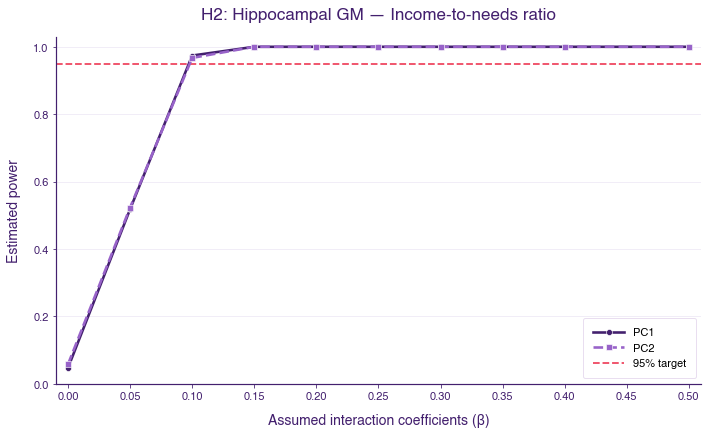

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


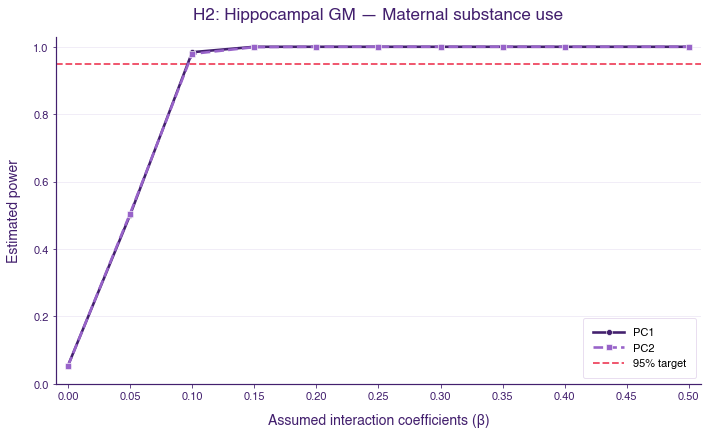

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


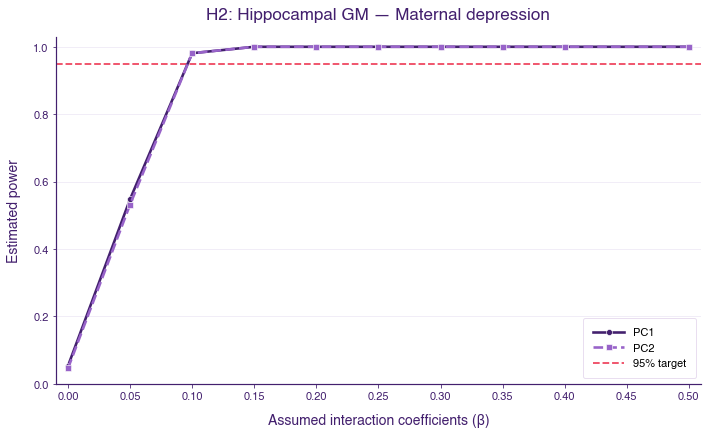

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


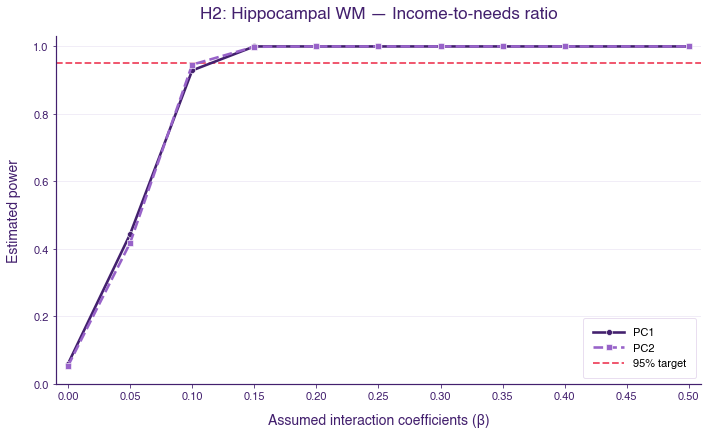

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


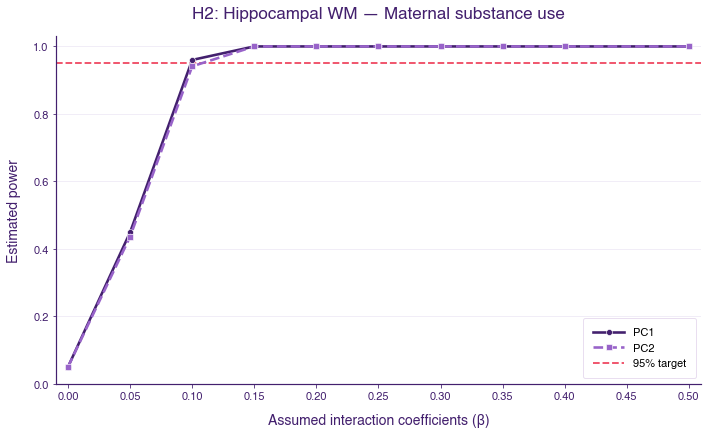

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


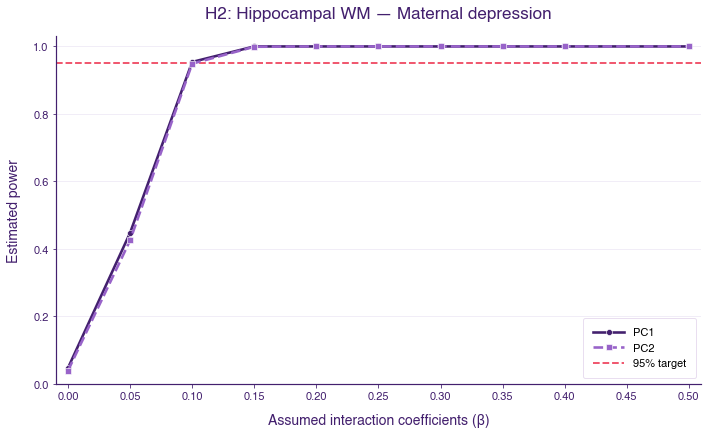

In [6]:

# ============================================================
# 14. POWER CURVES — MATCH HYPOTHESIS 1 STYLE
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import os

plt.rcParams.update({
    "font.family": "Helvetica",
    "font.size": 12,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# Hypothesis 1 color palette
DARK_PURPLE = "#43206E"
LIGHT_PURPLE = "#9863C9"
TARGET_RED = "#EF4760"
GRID_COLOR = "#EEE9F5"

predictor_labels = {
    "Income-to-needs ratio": "Income-to-needs ratio",
    "Maternal depression": "Maternal depression",
    "Maternal substance use": "Maternal substance use"
}

for outcome_type in OUTCOME_TYPES:
    for predictor in PREDICTORS:

        subset = results[
            (results["outcome_type"] == outcome_type)
            & (results["predictor"] == predictor)
        ]

        fig, ax = plt.subplots(figsize=(10, 6.2))

        # PC1: dark purple solid line with circles
        pc1 = subset[
            subset["moderator"] == "PC1"
        ].sort_values("beta")

        ax.plot(
            pc1["beta"],
            pc1["power"],
            color=DARK_PURPLE,
            linewidth=2.6,
            linestyle="-",
            marker="o",
            markersize=6,
            markeredgecolor="white",
            markeredgewidth=0.6,
            label="PC1",
            zorder=3
        )

        # PC2: light purple dashed line with squares
        pc2 = subset[
            subset["moderator"] == "PC2"
        ].sort_values("beta")

        ax.plot(
            pc2["beta"],
            pc2["power"],
            color=LIGHT_PURPLE,
            linewidth=2.6,
            linestyle="--",
            marker="s",
            markersize=6,
            markeredgecolor="white",
            markeredgewidth=0.6,
            label="PC2",
            zorder=4
        )

        # 95% power threshold
        ax.axhline(
            y=0.95,
            color=TARGET_RED,
            linestyle="--",
            linewidth=1.8,
            label="95% target",
            zorder=2
        )

        # Axes
        ax.set_xlim(-0.01, 0.51)
        ax.set_ylim(0, 1.03)

        ax.set_xticks(np.arange(0, 0.51, 0.05))
        ax.set_yticks(np.arange(0, 1.01, 0.2))

        ax.set_xlabel(
            "Assumed interaction coefficients (β)",
            fontsize=14,
            color=DARK_PURPLE,
            labelpad=12
        )

        ax.set_ylabel(
            "Estimated power",
            fontsize=14,
            color=DARK_PURPLE,
            labelpad=12
        )

        ax.set_title(
            f"H2: Hippocampal {outcome_type} — {predictor_labels[predictor]}",
            fontsize=17,
            color=DARK_PURPLE,
            pad=18
        )

        # Horizontal gridlines only
        ax.grid(
            axis="y",
            color=GRID_COLOR,
            linewidth=0.8
        )

        ax.set_axisbelow(True)

        # Spine styling
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.spines["left"].set_color(DARK_PURPLE)
        ax.spines["bottom"].set_color(DARK_PURPLE)

        ax.spines["left"].set_linewidth(1.2)
        ax.spines["bottom"].set_linewidth(1.2)

        ax.tick_params(
            axis="both",
            colors=DARK_PURPLE,
            labelsize=11
        )

        # Legend matching H1
        ax.legend(
            loc="lower right",
            fontsize=11,
            frameon=True,
            facecolor="white",
            edgecolor="#E8DDF0",
            framealpha=0.95,
            borderpad=0.9,
            handlelength=2.8
        )

        plt.tight_layout()

        safe_name = (
            predictor.lower()
            .replace(" ", "_")
            .replace("-", "_")
        )

        filename = os.path.join(
            OUTPUT_DIR,
            f"H2_power_{outcome_type}_{safe_name}"
        )

        fig.savefig(
            filename + ".png",
            dpi=1000,
            bbox_inches="tight",
            facecolor="white"
        )

        fig.savefig(
            filename + ".pdf",
            bbox_inches="tight",
            facecolor="white"
        )

        plt.show()
        plt.close(fig)



2-CLASS ITEM PROBABILITIES
    SNAP    WIC  Housing   Cash  Unemployment  Childcare
0  0.113  0.103    0.025  0.018         0.009      0.020
1  0.680  0.621    0.120  0.087         0.044      0.098

3-CLASS ITEM PROBABILITIES
    SNAP    WIC  Housing   Cash  Unemployment  Childcare
0  0.084  0.077    0.020  0.015         0.007      0.017
1  0.505  0.461    0.038  0.027         0.014      0.031
2  0.601  0.549    0.290  0.210         0.105      0.236

HYPOTHESIS 3 MONTE CARLO POWER ANALYSIS
Total scenarios: 120
Total simulations: 60000
Already completed: 0
Pending: 60000
Parallel workers: 4
Completed 4 of 60,000 simulations                                                         
Completed 8 of 60,000 simulations                                                         
Completed 12 of 60,000 simulations                                                        
Completed 16 of 60,000 simulations                                                        
Completed 20 of 60,000 simulations    

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


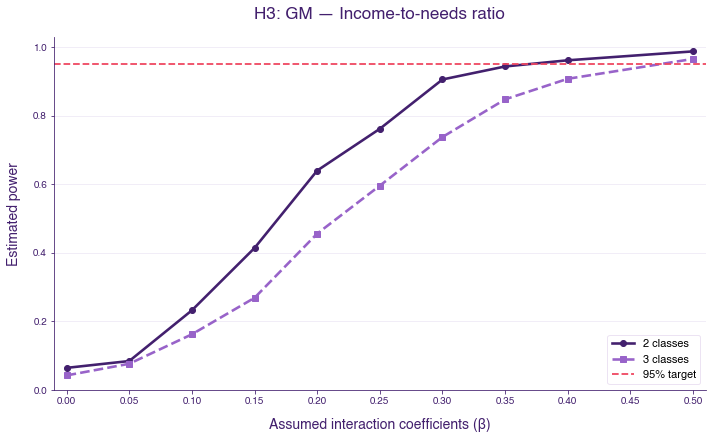

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


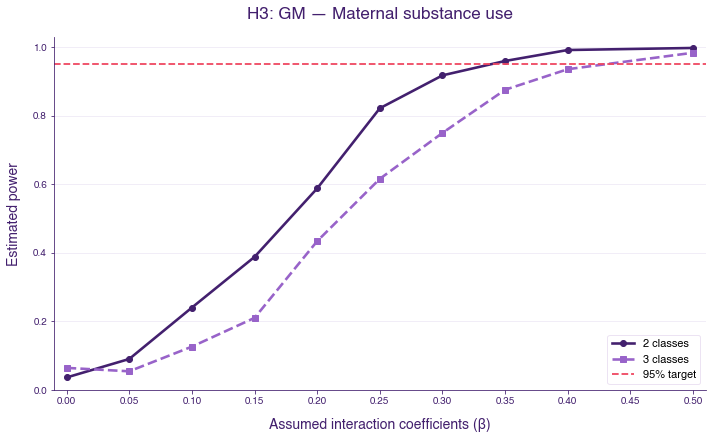

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


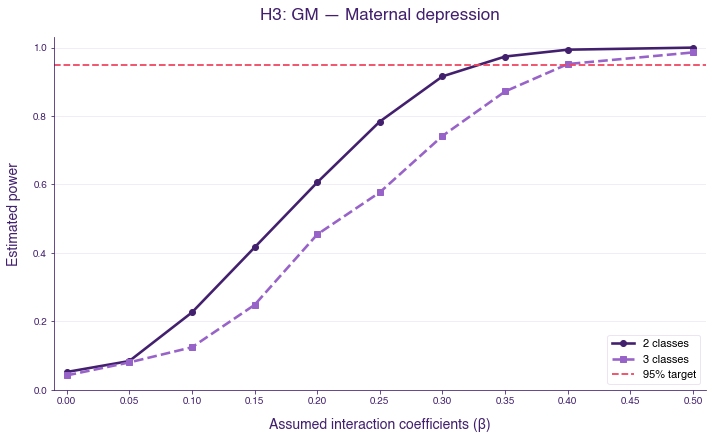

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


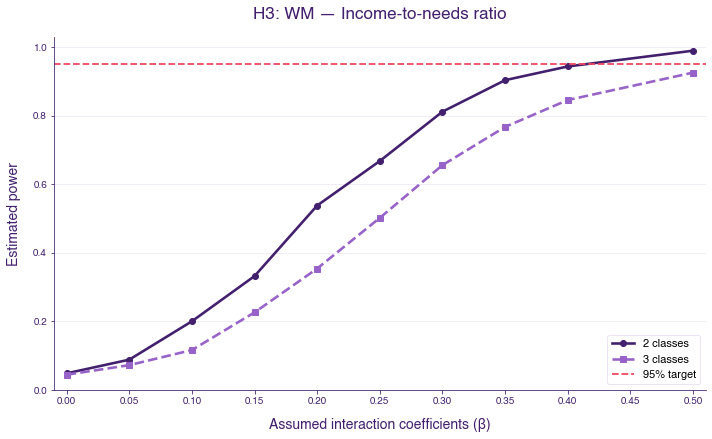

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


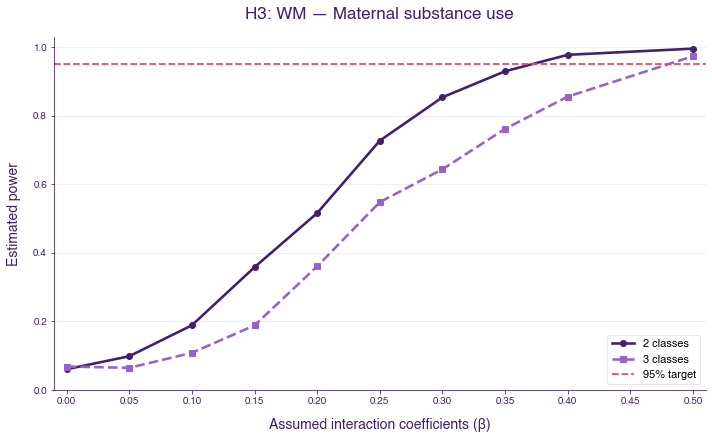

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


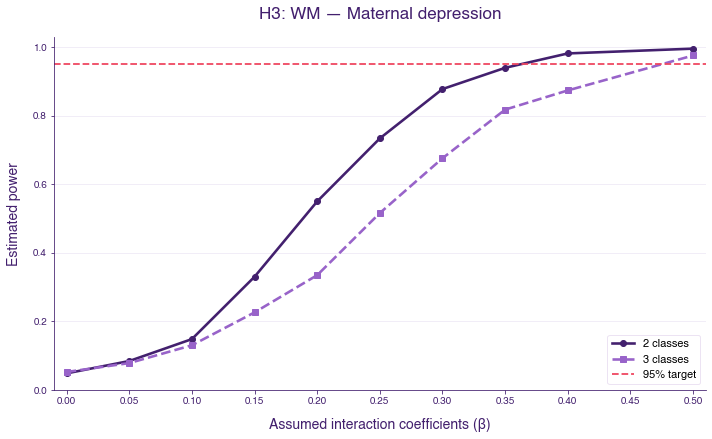


HYPOTHESIS 3 SIMULATION COMPLETED
Total simulations: 60000
Valid LME fits: 59991
Failed LME fits: 9
Mean LCA entropy: 0.588
Mean classification accuracy: 0.761
Mean AIC correct selection rate: 0.448
Mean BIC correct selection rate: 0.43

Results saved to: /Users/jivesh/Downloads/HBCD_H3_LCA_power_500sim_text


In [3]:

# ============================================================
# HYPOTHESIS 3: MONTE CARLO POWER ANALYSIS WITH LCA
# HBCD STUDY RELEASE 2.1
# ============================================================
#
# Install if needed:
# pip install numpy pandas scipy statsmodels joblib
# pip install threadpoolctl tqdm matplotlib
#
# Text-based progress bar: no Jupyter widgets required.
# ============================================================

import os
import sys
import warnings
import json
from pathlib import Path
from itertools import product

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import logsumexp
from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2, truncnorm

from statsmodels.regression.mixed_linear_model import MixedLM
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from tqdm import tqdm


# ============================================================
# 1. SETTINGS
# ============================================================

N_GM = 1500
N_WM = 1235

N_STATES = 20
N_SITES = 27

N_SIMULATIONS = 500

N_JOBS = 4
BATCH_SIZE = 4

SEED = 12345

ALPHA = 0.05
TARGET_POWER = 0.95

EFFECT_SIZES = [
    0.00, 0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.35, 0.40, 0.50
]

PREDICTORS = [
    "Income-to-needs ratio",
    "Maternal substance use",
    "Maternal depression"
]

OUTCOMES = ["GM", "WM"]

GENERATING_CLASSES = [2, 3]
CANDIDATE_CLASSES = [1, 2, 3, 4, 5]

LCA_N_STARTS = 10
LCA_MAX_ITER = 300
LCA_TOL = 1e-6

MIN_CLASS_PROPORTION = 0.05

VAR_STATE = 0.03
VAR_SITE = 0.04
VAR_FAMILY = 0.03
VAR_RESIDUAL = 0.90

BETA_PREDICTOR = 0.10

GM_MEAN = 1220
GM_SD = 187

THREE_CLASS_EFFECT_PATTERN = np.array([
    0.0, 1.0, 1.0
])

OUTPUT_DIR = Path(
    f"HBCD_H3_LCA_power_{N_SIMULATIONS}sim_text"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. RESOURCE RECEIPT INDICATORS
# ============================================================

RESOURCE_NAMES = [
    "SNAP",
    "WIC",
    "Housing",
    "Cash",
    "Unemployment",
    "Childcare"
]

RESOURCE_PREVALENCE = np.array([
    0.2832,
    0.2586,
    0.0533,
    0.0387,
    0.0193,
    0.0434
])

CLASS_PROPORTIONS = {
    2: np.array([0.70, 0.30]),
    3: np.array([0.55, 0.35, 0.10])
}

RELATIVE_ITEM_WEIGHTS = {

    2: np.array([
        [0.40, 0.40, 0.45, 0.45, 0.45, 0.45],
        [2.40, 2.40, 2.20, 2.20, 2.20, 2.20]
    ]),

    3: np.array([
        [0.35, 0.35, 0.35, 0.35, 0.35, 0.35],
        [2.10, 2.10, 0.65, 0.65, 0.65, 0.65],
        [2.50, 2.50, 5.00, 5.00, 5.00, 5.00]
    ])
}


def calibrate_item_probabilities(k):

    weights = RELATIVE_ITEM_WEIGHTS[k]
    proportions = CLASS_PROPORTIONS[k]

    denominator = (
        proportions[:, None] * weights
    ).sum(axis=0)

    probabilities = (
        RESOURCE_PREVALENCE[None, :]
        * weights
        / denominator[None, :]
    )

    if np.any(probabilities <= 0) or np.any(probabilities >= 1):
        raise ValueError(
            "Invalid class-specific probabilities."
        )

    return probabilities


ITEM_PROBABILITIES = {
    k: calibrate_item_probabilities(k)
    for k in GENERATING_CLASSES
}

for k in GENERATING_CLASSES:

    print(f"\n{k}-CLASS ITEM PROBABILITIES")

    print(
        pd.DataFrame(
            ITEM_PROBABILITIES[k],
            columns=RESOURCE_NAMES
        ).round(3)
    )


# ============================================================
# 3. STANDARDIZATION
# ============================================================

def standardize(x):

    x = np.asarray(x, dtype=float)

    sd = x.std(ddof=0)

    if sd <= 0:
        raise ValueError(
            "Cannot standardize constant variable."
        )

    return (x - x.mean()) / sd


# ============================================================
# 4. SIMULATE FAMILY CHARACTERISTICS
# ============================================================

def simulate_predictor(n, predictor, rng):

    if predictor == "Income-to-needs ratio":

        x = rng.lognormal(
            mean=0,
            sigma=0.75,
            size=n
        )

    elif predictor == "Maternal substance use":

        mean = 4.0
        variance = 2.88 ** 2

        r = mean ** 2 / (variance - mean)
        p = r / (r + mean)

        x = rng.negative_binomial(
            r, p, size=n
        )

        x = np.clip(x, 0, 19)

    elif predictor == "Maternal depression":

        mean = 46.33
        sd = 8.12

        lower = (38.20 - mean) / sd
        upper = (81.30 - mean) / sd

        x = truncnorm.rvs(
            lower,
            upper,
            loc=mean,
            scale=sd,
            size=n,
            random_state=rng
        )

    else:
        raise ValueError("Unknown predictor.")

    return standardize(x)


# ============================================================
# 5. SIMULATE MULTILEVEL STRUCTURE
# ============================================================

def simulate_structure(n, rng):

    state_idx = np.tile(
        np.arange(N_STATES),
        int(np.ceil(n / N_STATES))
    )[:n]

    rng.shuffle(state_idx)

    site_counts = np.array(
        [2] * 7 + [1] * 13
    )

    site_starts = np.cumsum(
        np.r_[0, site_counts[:-1]]
    )

    site_idx = np.empty(n, dtype=int)

    for state in range(N_STATES):

        members = np.where(
            state_idx == state
        )[0]

        site_idx[members] = (
            site_starts[state]
            + rng.integers(
                0,
                site_counts[state],
                size=len(members)
            )
        )

    family_idx = np.arange(n)

    n_pairs = int(
        round(0.05 * n / 2)
    )

    available = {}

    for state in range(N_STATES):

        members = list(
            np.where(state_idx == state)[0]
        )

        rng.shuffle(members)
        available[state] = members

    for _ in range(n_pairs):

        eligible = [
            s for s in range(N_STATES)
            if len(available[s]) >= 2
        ]

        if not eligible:
            break

        state = int(
            rng.choice(eligible)
        )

        a = available[state].pop()
        b = available[state].pop()

        family_idx[b] = family_idx[a]

    df = pd.DataFrame({
        "state_idx": state_idx,
        "site_idx": site_idx,
        "family_idx": family_idx
    })

    df["gestational_age"] = standardize(
        rng.normal(39, 1.5, n)
    )

    df["scan_age"] = standardize(
        rng.uniform(0, 12, n)
    )

    df["sex"] = rng.binomial(
        1, 0.5, n
    )

    df["maternal_education"] = standardize(
        rng.normal(15, 2.5, n)
    )

    df["ICV"] = standardize(
        rng.normal(0, 1, n)
    )

    df["scanner_manufacturer"] = rng.choice(
        ["GE", "Siemens", "Philips"],
        size=n,
        p=[0.25, 0.60, 0.15]
    )

    df["race_ethnicity"] = rng.choice(
        ["Group1", "Group2", "Group3", "Group4"],
        size=n,
        p=[0.45, 0.25, 0.20, 0.10]
    )

    return df


# ============================================================
# 6. GENERATE LATENT CLASSES AND RESOURCE INDICATORS
# ============================================================

def simulate_resources(n, k, rng):

    true_class = rng.choice(
        k,
        size=n,
        p=CLASS_PROPORTIONS[k]
    )

    probabilities = (
        ITEM_PROBABILITIES[k][true_class]
    )

    indicators = rng.binomial(
        1, probabilities
    ).astype(float)

    return true_class, indicators


# ============================================================
# 7. BINARY LCA VIA EM
# ============================================================

def fit_binary_lca(
    X,
    k,
    rng,
    n_starts=LCA_N_STARTS,
    max_iter=LCA_MAX_ITER,
    tol=LCA_TOL
):

    X = np.asarray(X, dtype=float)

    n, n_items = X.shape
    best = None

    for start in range(n_starts):

        pi = rng.dirichlet(
            np.ones(k)
        )

        theta = rng.uniform(
            0.05,
            0.80,
            size=(k, n_items)
        )

        previous_ll = -np.inf
        converged = False

        for iteration in range(max_iter):

            log_prob = (
                np.log(pi)[None, :]
                + X @ np.log(theta).T
                + (1 - X) @ np.log(1 - theta).T
            )

            log_denom = logsumexp(
                log_prob,
                axis=1,
                keepdims=True
            )

            posterior = np.exp(
                log_prob - log_denom
            )

            ll = float(
                log_denom.sum()
            )

            nk = posterior.sum(axis=0)

            pi_new = nk / n

            theta_new = (
                posterior.T @ X
            ) / np.maximum(
                nk[:, None], 1e-10
            )

            pi_new = np.clip(
                pi_new, 1e-8, None
            )

            pi_new /= pi_new.sum()

            theta_new = np.clip(
                theta_new,
                1e-6,
                1 - 1e-6
            )

            pi = pi_new
            theta = theta_new

            if abs(ll - previous_ll) < tol:
                converged = True
                break

            previous_ll = ll

        log_prob = (
            np.log(pi)[None, :]
            + X @ np.log(theta).T
            + (1 - X) @ np.log(1 - theta).T
        )

        log_denom = logsumexp(
            log_prob,
            axis=1,
            keepdims=True
        )

        posterior = np.exp(
            log_prob - log_denom
        )

        ll = float(
            log_denom.sum()
        )

        n_parameters = (
            (k - 1) + k * n_items
        )

        aic = (
            -2 * ll + 2 * n_parameters
        )

        bic = (
            -2 * ll
            + np.log(n) * n_parameters
        )

        if k > 1:

            raw_entropy = -np.sum(
                posterior * np.log(
                    np.clip(
                        posterior, 1e-12, 1
                    )
                )
            )

            entropy = (
                1
                - raw_entropy
                / (n * np.log(k))
            )

        else:
            entropy = np.nan

        assigned = np.argmax(
            posterior,
            axis=1
        )

        class_sizes = np.bincount(
            assigned,
            minlength=k
        )

        class_proportions = (
            class_sizes / n
        )

        candidate = {
            "pi": pi.copy(),
            "theta": theta.copy(),
            "posterior": posterior.copy(),
            "loglik": ll,
            "aic": aic,
            "bic": bic,
            "entropy": entropy,
            "converged": converged,
            "iterations": iteration + 1,
            "class_sizes": class_sizes,
            "class_proportions": class_proportions,
            "minimum_class_proportion": (
                class_proportions.min()
            ),
            "average_posterior_probability": (
                posterior.max(axis=1).mean()
            )
        }

        if (
            best is None
            or (
                converged
                and not best["converged"]
            )
            or (
                converged == best["converged"]
                and ll > best["loglik"]
            )
        ):
            best = candidate

    return best


# ============================================================
# 8. COMPARE 1–5 LCA CLASS SOLUTIONS
# ============================================================

def evaluate_lca_models(X, rng):

    models = {}
    rows = []

    for k in CANDIDATE_CLASSES:

        fit = fit_binary_lca(
            X, k, rng
        )

        models[k] = fit

        rows.append({
            "candidate_classes": k,
            "aic": fit["aic"],
            "bic": fit["bic"],
            "entropy": fit["entropy"],
            "converged": fit["converged"],
            "minimum_class_proportion": (
                fit["minimum_class_proportion"]
            ),
            "average_posterior_probability": (
                fit["average_posterior_probability"]
            )
        })

    comparison = pd.DataFrame(rows)

    eligible = comparison.loc[
        comparison["converged"]
    ]

    if len(eligible) == 0:

        selected_aic = np.nan
        selected_bic = np.nan

    else:

        selected_aic = int(
            eligible.loc[
                eligible["aic"].idxmin(),
                "candidate_classes"
            ]
        )

        selected_bic = int(
            eligible.loc[
                eligible["bic"].idxmin(),
                "candidate_classes"
            ]
        )

    return {
        "models": models,
        "comparison": comparison,
        "selected_aic": selected_aic,
        "selected_bic": selected_bic
    }


# ============================================================
# 9. ALIGN ESTIMATED CLASSES
# ============================================================

def align_classes(
    estimated_theta,
    reference_theta,
    posterior
):

    cost = (
        (
            estimated_theta[:, None, :]
            - reference_theta[None, :, :]
        ) ** 2
    ).sum(axis=2)

    estimated_idx, reference_idx = (
        linear_sum_assignment(cost)
    )

    aligned_posterior = np.zeros_like(
        posterior
    )

    for e, r in zip(
        estimated_idx, reference_idx
    ):

        aligned_posterior[:, r] = (
            posterior[:, e]
        )

    assigned = np.argmax(
        aligned_posterior,
        axis=1
    )

    return assigned, aligned_posterior


# ============================================================
# 10. GENERATE BRAIN OUTCOME
# ============================================================

def generate_outcome(
    df,
    predictor,
    true_class,
    k,
    beta,
    outcome_type,
    rng
):

    n = len(df)

    if k == 2:

        class_main = (
            true_class == 1
        ).astype(float)

        interaction = (
            beta * predictor * class_main
        )

    else:

        class_main = (
            true_class > 0
        ).astype(float)

        interaction = (
            beta
            * predictor
            * THREE_CLASS_EFFECT_PATTERN[true_class]
        )

    state_effects = rng.normal(
        0,
        np.sqrt(VAR_STATE),
        N_STATES
    )

    site_effects = rng.normal(
        0,
        np.sqrt(VAR_SITE),
        N_SITES
    )

    family_codes, family_labels = (
        pd.factorize(
            df["family_idx"],
            sort=False
        )
    )

    family_effects = rng.normal(
        0,
        np.sqrt(VAR_FAMILY),
        len(family_labels)
    )

    residual = rng.normal(
        0,
        np.sqrt(VAR_RESIDUAL),
        n
    )

    y = (
        BETA_PREDICTOR * predictor
        + 0.05 * class_main
        + interaction

        + 0.08 * df["gestational_age"].to_numpy()
        + 0.10 * df["scan_age"].to_numpy()
        + 0.05 * df["sex"].to_numpy()
        + 0.05 * df["maternal_education"].to_numpy()

        + state_effects[
            df["state_idx"].to_numpy()
        ]

        + site_effects[
            df["site_idx"].to_numpy()
        ]

        + family_effects[family_codes]

        + residual
    )

    if outcome_type == "GM":

        y += (
            0.25 * df["ICV"].to_numpy()
        )

        y = GM_MEAN + GM_SD * y

    return y


# ============================================================
# 11. FIT LINEAR MIXED-EFFECTS MODEL
# ============================================================

def fit_lme(df, outcome_type, k):

    formula = (
        "outcome ~ predictor * C(estimated_class)"
        " + gestational_age"
        " + scan_age"
        " + sex"
        " + maternal_education"
        " + C(scanner_manufacturer)"
        " + C(race_ethnicity)"
    )

    if outcome_type == "GM":
        formula += " + ICV"

    try:

        model = MixedLM.from_formula(
            formula=formula,
            data=df,
            groups="state_idx",
            re_formula="1",
            vc_formula={
                "site": "0 + C(site_idx)",
                "family": "0 + C(family_idx)"
            }
        )

    except Exception:

        return {
            "p_value": np.nan,
            "converged": False,
            "optimizer": "failed"
        }

    for method in ["lbfgs", "powell"]:

        try:

            with warnings.catch_warnings():

                warnings.simplefilter(
                    "ignore"
                )

                fit = model.fit(
                    reml=False,
                    method=method,
                    maxiter=500,
                    disp=False
                )

            if not fit.converged:
                continue

            names = [
                name
                for name in fit.fe_params.index
                if (
                    "predictor:C(estimated_class)"
                    in name
                )
            ]

            if len(names) != k - 1:
                continue

            coefficients = (
                fit.fe_params.loc[names]
                .to_numpy(dtype=float)
            )

            covariance = (
                fit.cov_params()
                .loc[names, names]
                .to_numpy(dtype=float)
            )

            statistic = float(
                coefficients
                @ np.linalg.solve(
                    covariance,
                    coefficients
                )
            )

            p_value = float(
                chi2.sf(
                    statistic,
                    df=k - 1
                )
            )

            return {
                "p_value": p_value,
                "converged": True,
                "optimizer": method,
                "wald_statistic": statistic
            }

        except Exception:
            continue

    return {
        "p_value": np.nan,
        "converged": False,
        "optimizer": "failed"
    }


# ============================================================
# 12. RUN ONE MONTE CARLO REPLICATE
# ============================================================

def run_one_replicate(
    scenario,
    replicate,
    seed
):

    outcome_type, predictor_name, k, beta = scenario

    rng = np.random.default_rng(seed)

    n = (
        N_GM if outcome_type == "GM"
        else N_WM
    )

    result = {
        "outcome_type": outcome_type,
        "predictor": predictor_name,
        "n_classes": k,
        "beta": beta,
        "replicate": replicate,
        "p_value": np.nan,
        "converged": False,
        "lca_converged": False,
        "error": ""
    }

    try:

        df = simulate_structure(
            n, rng
        )

        x = simulate_predictor(
            n, predictor_name, rng
        )

        true_class, indicators = (
            simulate_resources(
                n, k, rng
            )
        )

        evaluation = evaluate_lca_models(
            indicators, rng
        )

        lca = evaluation["models"][k]

        selected_aic = evaluation[
            "selected_aic"
        ]

        selected_bic = evaluation[
            "selected_bic"
        ]

        estimated_class, posterior = (
            align_classes(
                lca["theta"],
                ITEM_PROBABILITIES[k],
                lca["posterior"]
            )
        )

        accuracy = np.mean(
            estimated_class == true_class
        )

        avg_posterior = np.mean(
            np.max(posterior, axis=1)
        )

        class_sizes = np.bincount(
            estimated_class,
            minlength=k
        )

        minimum_proportion = (
            class_sizes.min() / n
        )

        result.update({
            "lca_converged": lca["converged"],
            "lca_aic": lca["aic"],
            "lca_bic": lca["bic"],
            "lca_entropy": lca["entropy"],
            "lca_loglik": lca["loglik"],
            "lca_iterations": lca["iterations"],
            "classification_accuracy": accuracy,
            "average_posterior_probability": avg_posterior,
            "minimum_class_proportion": minimum_proportion,
            "selected_classes_aic": selected_aic,
            "selected_classes_bic": selected_bic,
            "aic_correct": (
                selected_aic == k
            ),
            "bic_correct": (
                selected_bic == k
            ),
            "class_size_acceptable": (
                minimum_proportion >=
                MIN_CLASS_PROPORTION
            )
        })

        y = generate_outcome(
            df,
            x,
            true_class,
            k,
            beta,
            outcome_type,
            rng
        )

        df["predictor"] = x
        df["outcome"] = y

        df["estimated_class"] = pd.Categorical(
            estimated_class,
            categories=list(range(k))
        )

        if np.any(class_sizes == 0):

            result["error"] = (
                "One or more estimated classes empty"
            )

            return result

        lme = fit_lme(
            df,
            outcome_type,
            k
        )

        result.update(lme)

    except Exception as error:

        result["error"] = str(error)[:200]

    return result


# ============================================================
# 13. DEFINE SIMULATION JOBS
# ============================================================

SCENARIOS = list(
    product(
        OUTCOMES,
        PREDICTORS,
        GENERATING_CLASSES,
        EFFECT_SIZES
    )
)

assert len(SCENARIOS) == 120

TOTAL_REPLICATES = (
    len(SCENARIOS) * N_SIMULATIONS
)

seed_sequence = np.random.SeedSequence(
    SEED
)

seeds = seed_sequence.spawn(
    TOTAL_REPLICATES
)

JOBS = []

index = 0

for scenario in SCENARIOS:

    for replicate in range(
        1,
        N_SIMULATIONS + 1
    ):

        JOBS.append((
            scenario,
            replicate,
            seeds[index]
        ))

        index += 1


# ============================================================
# 14. PARALLEL PROCESSING WITH TEXT PROGRESS BAR
# ============================================================

DETAIL_FILE = OUTPUT_DIR / "fit_diagnostics.csv"

if DETAIL_FILE.exists():

    existing = pd.read_csv(
        DETAIL_FILE
    )

    completed = set(
        zip(
            existing["outcome_type"],
            existing["predictor"],
            existing["n_classes"],
            existing["beta"].round(8),
            existing["replicate"]
        )
    )

else:
    completed = set()


PENDING_JOBS = []

for scenario, replicate, seed in JOBS:

    key = (
        scenario[0],
        scenario[1],
        scenario[2],
        round(scenario[3], 8),
        replicate
    )

    if key not in completed:

        PENDING_JOBS.append((
            scenario,
            replicate,
            seed
        ))


print("\n" + "=" * 60, flush=True)
print("HYPOTHESIS 3 MONTE CARLO POWER ANALYSIS", flush=True)
print("=" * 60, flush=True)

print("Total scenarios:", len(SCENARIOS), flush=True)
print("Total simulations:", TOTAL_REPLICATES, flush=True)
print("Already completed:", len(completed), flush=True)
print("Pending:", len(PENDING_JOBS), flush=True)
print("Parallel workers:", N_JOBS, flush=True)

total_batches = int(
    np.ceil(len(PENDING_JOBS) / BATCH_SIZE)
)

progress_bar = tqdm(
    total=total_batches,
    desc="H3 simulation batches",
    ascii=True,
    dynamic_ncols=False,
    ncols=90,
    mininterval=1,
    leave=True,
    file=sys.stdout
)

with threadpool_limits(limits=1):

    for start in range(
        0,
        len(PENDING_JOBS),
        BATCH_SIZE
    ):

        batch = PENDING_JOBS[
            start:start + BATCH_SIZE
        ]

        batch_results = Parallel(
            n_jobs=N_JOBS,
            backend="loky",
            verbose=0
        )(
            delayed(run_one_replicate)(
                scenario,
                replicate,
                seed
            )
            for scenario, replicate, seed in batch
        )

        batch_df = pd.DataFrame(
            batch_results
        )

        batch_df.to_csv(
            DETAIL_FILE,
            mode="a",
            header=not DETAIL_FILE.exists(),
            index=False
        )

        progress_bar.update(1)

        completed_count = (
            len(completed)
            + min(
                start + len(batch),
                len(PENDING_JOBS)
            )
        )

        tqdm.write(
            f"Completed {completed_count:,} "
            f"of {TOTAL_REPLICATES:,} simulations",
            file=sys.stdout
        )

progress_bar.close()

print(
    "\nAll simulation batches completed.",
    flush=True
)


# ============================================================
# 15. LOAD AND SUMMARIZE RESULTS
# ============================================================

details = pd.read_csv(
    DETAIL_FILE
)

details = details.drop_duplicates(
    subset=[
        "outcome_type",
        "predictor",
        "n_classes",
        "beta",
        "replicate"
    ],
    keep="last"
)

details["significant"] = (
    details["p_value"] < ALPHA
)

details["valid_fit"] = (
    details["p_value"].notna()
)

group_cols = [
    "outcome_type",
    "predictor",
    "n_classes",
    "beta"
]

summary = (
    details
    .groupby(group_cols)
    .agg(
        simulations=("replicate", "count"),
        valid_fits=("valid_fit", "sum"),
        significant_fits=("significant", "sum"),
        lca_convergence_rate=(
            "lca_converged", "mean"
        ),
        lme_convergence_rate=(
            "converged", "mean"
        ),
        mean_entropy=(
            "lca_entropy", "mean"
        ),
        mean_classification_accuracy=(
            "classification_accuracy", "mean"
        )
    )
    .reset_index()
)

summary["failed_fits"] = (
    summary["simulations"]
    - summary["valid_fits"]
)

summary["power"] = (
    summary["significant_fits"]
    / summary["valid_fits"].replace(0, np.nan)
)

summary.to_csv(
    OUTPUT_DIR / "power_summary.csv",
    index=False
)


# ============================================================
# 16. LCA DIAGNOSTIC SUMMARY
# ============================================================

lca_summary = (
    details
    .groupby([
        "n_classes",
        "outcome_type"
    ])
    .agg(
        mean_AIC=(
            "lca_aic", "mean"
        ),
        mean_BIC=(
            "lca_bic", "mean"
        ),
        mean_entropy=(
            "lca_entropy", "mean"
        ),
        mean_posterior_probability=(
            "average_posterior_probability",
            "mean"
        ),
        mean_minimum_class_proportion=(
            "minimum_class_proportion",
            "mean"
        ),
        mean_classification_accuracy=(
            "classification_accuracy",
            "mean"
        ),
        aic_correct_selection_rate=(
            "aic_correct", "mean"
        ),
        bic_correct_selection_rate=(
            "bic_correct", "mean"
        ),
        acceptable_class_size_rate=(
            "class_size_acceptable", "mean"
        ),
        lca_convergence_rate=(
            "lca_converged", "mean"
        ),
        lme_convergence_rate=(
            "converged", "mean"
        )
    )
    .reset_index()
)

lca_summary.to_csv(
    OUTPUT_DIR / "LCA_diagnostic_summary.csv",
    index=False
)

print("\nLCA DIAGNOSTIC SUMMARY")

print(
    lca_summary.round(3).to_string(
        index=False
    )
)


# ============================================================
# 17. EMPIRICAL TYPE I ERROR
# ============================================================

type_I_error = summary[
    np.isclose(summary["beta"], 0)
].copy()

type_I_error = type_I_error.rename(
    columns={
        "power": "type_I_error"
    }
)

type_I_error.to_csv(
    OUTPUT_DIR / "type_I_error.csv",
    index=False
)

print("\nEMPIRICAL TYPE I ERROR")

print(
    type_I_error[
        [
            "n_classes",
            "outcome_type",
            "predictor",
            "type_I_error",
            "valid_fits"
        ]
    ].round(3).to_string(index=False)
)


# ============================================================
# 18. MINIMUM DETECTABLE EFFECT SIZE
# ============================================================

detectable = (
    summary.loc[
        (summary["power"] >= TARGET_POWER)
        & (summary["beta"] > 0)
    ]
    .groupby([
        "n_classes",
        "outcome_type",
        "predictor"
    ])["beta"]
    .min()
    .reset_index()
    .rename(
        columns={
            "beta": "minimum_beta_95_power"
        }
    )
)

all_configs = (
    summary[
        [
            "n_classes",
            "outcome_type",
            "predictor"
        ]
    ]
    .drop_duplicates()
)

detectable = all_configs.merge(
    detectable,
    on=[
        "n_classes",
        "outcome_type",
        "predictor"
    ],
    how="left"
)

detectable.to_csv(
    OUTPUT_DIR / "minimum_detectable_effects.csv",
    index=False
)

print("\nMINIMUM TESTED BETA AT 95% POWER")

print(
    detectable.to_string(index=False)
)


# ============================================================
# 19. PLOT POWER CURVES
# ============================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": [
        "Helvetica",
        "Arial",
        "DejaVu Sans"
    ],
    "font.size": 12,
    "pdf.fonttype": 42
})

DARK_PURPLE = "#43206E"
LIGHT_PURPLE = "#9863C9"
TARGET_RED = "#EF4760"
GRID_COLOR = "#EEE9F5"

for outcome_type in OUTCOMES:

    for predictor in PREDICTORS:

        subset = summary[
            (summary["outcome_type"] == outcome_type)
            & (summary["predictor"] == predictor)
        ]

        fig, ax = plt.subplots(
            figsize=(10, 6.2)
        )

        for k, color, linestyle, marker in [
            (2, DARK_PURPLE, "-", "o"),
            (3, LIGHT_PURPLE, "--", "s")
        ]:

            data = subset[
                subset["n_classes"] == k
            ].sort_values("beta")

            ax.plot(
                data["beta"],
                data["power"],
                color=color,
                linestyle=linestyle,
                marker=marker,
                linewidth=2.6,
                markersize=6,
                label=f"{k} classes"
            )

        ax.axhline(
            TARGET_POWER,
            color=TARGET_RED,
            linestyle="--",
            linewidth=1.8,
            label="95% target"
        )

        ax.set_xlim(-0.01, 0.51)
        ax.set_ylim(0, 1.03)

        ax.set_xticks(
            np.arange(0, 0.51, 0.05)
        )

        ax.set_yticks(
            np.arange(0, 1.01, 0.2)
        )

        ax.set_xlabel(
            "Assumed interaction coefficients (β)",
            fontsize=14,
            color=DARK_PURPLE,
            labelpad=12
        )

        ax.set_ylabel(
            "Estimated power",
            fontsize=14,
            color=DARK_PURPLE,
            labelpad=12
        )

        ax.set_title(
            f"H3: {outcome_type} — {predictor}",
            fontsize=17,
            color=DARK_PURPLE,
            pad=18
        )

        ax.grid(
            axis="y",
            color=GRID_COLOR,
            linewidth=0.8
        )

        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.spines["left"].set_color(
            DARK_PURPLE
        )

        ax.spines["bottom"].set_color(
            DARK_PURPLE
        )

        ax.tick_params(
            axis="both",
            colors=DARK_PURPLE
        )

        ax.legend(
            loc="lower right",
            fontsize=11,
            frameon=True,
            facecolor="white",
            edgecolor="#E8DDF0"
        )

        plt.tight_layout()

        safe_name = (
            predictor.lower()
            .replace(" ", "_")
            .replace("-", "_")
        )

        filename = (
            OUTPUT_DIR
            / f"H3_power_{outcome_type}_{safe_name}"
        )

        fig.savefig(
            str(filename) + ".png",
            dpi=1000,
            bbox_inches="tight"
        )

        fig.savefig(
            str(filename) + ".pdf",
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)


# ============================================================
# 20. SAVE SIMULATION CONFIGURATION
# ============================================================

configuration = {
    "N_GM": N_GM,
    "N_WM": N_WM,
    "N_STATES": N_STATES,
    "N_SITES": N_SITES,
    "N_SIMULATIONS": N_SIMULATIONS,
    "EFFECT_SIZES": EFFECT_SIZES,
    "ALPHA": ALPHA,
    "TARGET_POWER": TARGET_POWER,
    "CLASS_PROPORTIONS": {
        str(k): v.tolist()
        for k, v in CLASS_PROPORTIONS.items()
    },
    "RESOURCE_PREVALENCE": (
        RESOURCE_PREVALENCE.tolist()
    ),
    "ITEM_PROBABILITIES": {
        str(k): v.tolist()
        for k, v in ITEM_PROBABILITIES.items()
    }
}

with open(
    OUTPUT_DIR / "simulation_config.json",
    "w"
) as file:

    json.dump(
        configuration,
        file,
        indent=4
    )


# ============================================================
# 21. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("HYPOTHESIS 3 SIMULATION COMPLETED")
print("=" * 60)

print(
    "Total simulations:",
    len(details)
)

print(
    "Valid LME fits:",
    details["valid_fit"].sum()
)

print(
    "Failed LME fits:",
    (~details["valid_fit"]).sum()
)

print(
    "Mean LCA entropy:",
    round(
        details["lca_entropy"].mean(),
        3
    )
)

print(
    "Mean classification accuracy:",
    round(
        details["classification_accuracy"].mean(),
        3
    )
)

print(
    "Mean AIC correct selection rate:",
    round(
        details["aic_correct"].mean(),
        3
    )
)

print(
    "Mean BIC correct selection rate:",
    round(
        details["bic_correct"].mean(),
        3
    )
)

print(
    "\nResults saved to:",
    OUTPUT_DIR.resolve()
)
